# **Real-Time Credit Card Fraud Detection: A Machine Learning Approach to Reduce Financial Losses and Protect Cardholders**

# **Part 1 - Business Problem**

Credit card fraud causes direct financial losses through chargebacks and reimbursements, increases operational costs from manual reviews and disputes, and erodes customer trust. Fraud is extremely rare and constantly evolving. In this dataset, only about 0.55% of 34.6 million transactions (January 2019 to December 2020) are fraudulent, so rule-based systems and manual review do not scale.

The business needs an automated model that scores each transaction at authorization time, balancing two competing costs:

- **False negatives:** a missed fraud means the full transaction amount is lost, plus chargeback fees.
- **False positives:** a legitimate purchase declined means customer friction, call-center cost, and possible churn.

**Objective:** build a supervised ML classifier that predicts `is_fraud` from transaction, merchant, and cardholder behavior features, maximizing fraud captured (recall) at an acceptable false-positive rate, so the fraud team reviews only the highest-risk transactions.

**Success metrics:**

- PR-AUC (primary, because of the heavy class imbalance)
- Recall at a fixed precision, or precision at a fixed recall
- F1 / F2-score
- Estimated monetary savings = fraud amount blocked minus the cost of false positives

ROC-AUC and accuracy alone would be misleading here, since predicting "not fraud" for everything already gives about 99.45% accuracy.


In [36]:
"""Check that imbalanced-learn (SMOTENC) and polars are installed.

Confere se o imbalanced-learn (que traz o SMOTENC) e o polars estão instalados.
"""

import imblearn
import polars as pl

print("imbalanced-learn:", imblearn.__version__)
print("polars:", pl.__version__)

imbalanced-learn: 0.12.3
polars: 2.0.0


In [37]:
"""Check that a GPU is available (XGBoost and CatBoost GPU models need it).

Confere se há GPU NVIDIA disponível (os modelos XGBoost e CatBoost em GPU precisam dela).
"""

import subprocess

# empty output means no NVIDIA GPU / saída vazia significa que não há GPU NVIDIA
gpu = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
    capture_output=True, text=True, check=False,
)
print("GPU:", gpu.stdout.strip() or "none, the GPU models will fail / nenhuma, os modelos em GPU vão falhar")

GPU: NVIDIA GeForce RTX 3050 Laptop GPU, 4096 MiB


In [38]:
# Importação das bibliotecas
import os
from pathlib import Path
import sys
import shutil
import shutil
import subprocess
import time
import re
import joblib

import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter

import imblearn
from imblearn.over_sampling import SMOTENC

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier, XGBRFClassifier

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, fbeta_score, precision_score, recall_score, roc_auc_score)

COR_PRIMARIA = "#0072B2"    # main series / série principal
COR_SECUNDARIA = "#94A3B8"  # neutral support / apoio neutro
COR_DESTAQUE = "#E69F00"    # key highlight / destaque principal

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# **Part 2 - Local paths**

In [39]:
"""Local folders, relative to the repository root.

Pastas locais, relativas à raiz do repositório.
"""

# works whether Jupyter starts in notebook/ or in the repository root / funciona se o Jupyter abrir em notebook/ ou na raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

DATA_DIR = RAIZ / "input"                    # raw dataset and Parquet / base bruta e Parquet
MODELOS_DIR = RAIZ / "models"                # fitted models and final bundle / modelos treinados e pacote final
RESULTADOS_DIR = MODELOS_DIR / "resultados"  # predictions / previsões
OUTPUT_DIR = RAIZ / "output"                 # sample file to try the prediction / arquivo de exemplo para testar a previsão

CSV_PATH = str(DATA_DIR / "credit_card_fraud.csv")
PARQUET_PATH = str(DATA_DIR / "credit_card_fraud_full.parquet")

for pasta in (DATA_DIR, MODELOS_DIR, RESULTADOS_DIR, OUTPUT_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

print("Root / Raiz:", RAIZ)
print(f"Free disk / Espaço livre: {shutil.disk_usage(RAIZ).free / 1e9:.1f} GB")

Root / Raiz: c:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Credit-Card-Fraud-Detection-on-34.6M-Transactions
Free disk / Espaço livre: 670.4 GB


# **Part 3 - Database**

In [40]:
"""Confirm the dataset is in input/ (no download needed locally).

Confirma que a base está em input/ (não precisa baixar localmente).
"""

csv_path = CSV_PATH
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Put credit_card_fraud.csv in / Coloque credit_card_fraud.csv em {DATA_DIR}")
print(f"File size / Tamanho do arquivo: {os.path.getsize(csv_path) / 1e9:.2f} GB")

File size / Tamanho do arquivo: 11.19 GB


# **Part 4 - Preprocessing**

In [41]:
"""Check column names and types from the first rows of the CSV.

Checa nomes e tipos das colunas nas primeiras linhas do CSV.
"""

# read only 1000 rows, instant even on an 11 GB file / ler só 1000 linhas, instantâneo mesmo em arquivo de 11 GB
amostra = pl.read_csv(CSV_PATH, n_rows=1000)

# columns the conversion expects / colunas que a conversão espera
keep_cols = [
    "unix_time", "dob", "lat", "long", "merch_lat", "merch_long", "city_pop",
    "amt", "category", "gender", "state", "job", "merchant", "is_fraud",
]

print("Missing columns / Colunas ausentes:", [c for c in keep_cols if c not in amostra.columns])
print(amostra.shape)
print(amostra.schema)

Missing columns / Colunas ausentes: []
(1000, 27)
Schema({'': Int64, 'ssn': String, 'cc_num': Int64, 'first': String, 'last': String, 'gender': String, 'street': String, 'city': String, 'state': String, 'zip': Int64, 'lat': Float64, 'long': Float64, 'city_pop': Int64, 'job': String, 'dob': String, 'acct_num': Int64, 'profile': String, 'trans_num': String, 'trans_date': String, 'trans_time': String, 'unix_time': Int64, 'category': String, 'amt': Float64, 'is_fraud': Int64, 'merchant': String, 'merch_lat': Float64, 'merch_long': Float64})


In [42]:
"""Convert the full CSV to Parquet keeping only analysis columns.

Converte o CSV completo para Parquet mantendo só as colunas de análise.
"""

# input and output paths / caminhos de entrada e saída
csv_path = CSV_PATH
parquet_path = PARQUET_PATH

# columns kept, personal identifiers are dropped / colunas mantidas, identificadores pessoais removidos
keep_cols = [
    "unix_time", "dob", "lat", "long", "merch_lat", "merch_long", "city_pop",
    "amt", "category", "gender", "state", "job", "merchant", "is_fraud",
]

# lazy scan, fraud flag as boolean and timestamp from unix_time / leitura lazy, flag de fraude como booleano e timestamp a partir do unix_time
(
    pl.scan_csv(csv_path, infer_schema_length=10000)
    .select(keep_cols)
    .with_columns(
        pl.col("is_fraud").cast(pl.Boolean),
        pl.from_epoch("unix_time", time_unit="s").alias("trans_dt"),
    )
    .sink_parquet(parquet_path)
)
print(f"Parquet size: {os.path.getsize(parquet_path) / 1e9:.2f} GB")

Parquet size: 0.95 GB


In [43]:
"""Check shape, dtypes and a sample of the Parquet file.

Checa tamanho, tipos e uma amostra do arquivo Parquet.
"""

pl.Config.set_tbl_cols(-1)

# lazy handle on the Parquet file / ponteiro lazy para o arquivo Parquet
lazy = pl.scan_parquet(PARQUET_PATH)

# row count and column types / contagem de linhas e tipos das colunas
print("Rows / Linhas:", lazy.select(pl.len()).collect().item())
print(lazy.collect_schema())

# small sample to confirm readable values / amostra pequena para confirmar valores legíveis
lazy.head(10).collect()

Rows / Linhas: 34636378
Schema({'unix_time': Int64, 'dob': String, 'lat': Float64, 'long': Float64, 'merch_lat': Float64, 'merch_long': Float64, 'city_pop': Int64, 'amt': Float64, 'category': String, 'gender': String, 'state': String, 'job': String, 'merchant': String, 'is_fraud': Boolean, 'trans_dt': Datetime(time_unit='us', time_zone=None)})


unix_time,dob,lat,long,merch_lat,merch_long,city_pop,amt,category,gender,state,job,merchant,is_fraud,trans_dt
i64,str,f64,f64,f64,f64,i64,f64,str,str,str,str,str,bool,datetime[μs]
1581715097,"""2003-09-14""",37.7383,-121.4345,38.724545,-120.916415,106426,4.34,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Moore, Dibbert and Koepp""",true,2020-02-14 21:18:17
1581710376,"""2003-09-14""",37.7383,-121.4345,37.288981,-121.791754,106426,11.2,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Dach-Nader""",true,2020-02-14 19:59:36
1581747004,"""2003-09-14""",37.7383,-121.4345,38.46153,-120.624583,106426,282.55,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Pacocha-O'Reilly""",true,2020-02-15 06:10:04
1581709848,"""2003-09-14""",37.7383,-121.4345,37.920539,-121.43939,106426,294.94,"""gas_transport""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Kutch, Hermiston and Far…",true,2020-02-14 19:50:48
1581709519,"""2003-09-14""",37.7383,-121.4345,38.12385,-120.843755,106426,326.4,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Kuphal-Bartoletti""",true,2020-02-14 19:45:19
1581727053,"""2003-09-14""",37.7383,-121.4345,37.10285,-121.515057,106426,675.0,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Auer-Mosciski""",true,2020-02-15 00:37:33
1581712611,"""2003-09-14""",37.7383,-121.4345,37.819908,-121.793001,106426,628.75,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Strosin-Cruickshank""",true,2020-02-14 20:36:51
1581718745,"""2003-09-14""",37.7383,-121.4345,37.034358,-121.629142,106426,751.03,"""grocery_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Towne, Walker and Borer""",true,2020-02-14 22:19:05
1581872880,"""2003-09-14""",37.7383,-121.4345,37.958785,-121.960836,106426,994.33,"""shopping_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Volkman-Predovic""",true,2020-02-16 17:08:00


# **Part 5 - Data cleaning**

In [44]:
"""Count null values per column in the full Parquet file.

Conta valores nulos por coluna no arquivo Parquet completo.
"""

pl.Config.set_tbl_rows(30)

# fresh handle on the raw Parquet, independent of earlier filters / ponteiro novo para o Parquet bruto, independente de filtros anteriores
base_bruta = pl.scan_parquet(PARQUET_PATH)
n_total = base_bruta.select(pl.len()).collect().item()

# one row per column with null count and percentage / uma linha por coluna com contagem e porcentagem de nulos
nulos = (
    base_bruta.select(pl.all().null_count())
    .collect()
    .transpose(include_header=True, header_name="coluna", column_names=["nulos"])
    .with_columns((pl.col("nulos") / n_total * 100).round(4).alias("pct_nulos"))
)
print("Rows / Linhas:", n_total)
nulos

Rows / Linhas: 34636378


coluna,nulos,pct_nulos
str,u32,f64
"""unix_time""",0,0.0
"""dob""",0,0.0
"""lat""",0,0.0
"""long""",0,0.0
"""merch_lat""",0,0.0
"""merch_long""",0,0.0
"""city_pop""",0,0.0
"""amt""",0,0.0
"""category""",0,0.0


In [45]:
"""Count empty or blank text values in string columns.

Conta valores de texto vazios ou só com espaços nas colunas de texto.
"""

# blank means no content after removing spaces / vazio significa sem conteúdo após remover os espaços
base_bruta.select((pl.col(pl.String).str.strip_chars() == "").sum()).collect()

dob,category,gender,state,job,merchant
u32,u32,u32,u32,u32,u32
0,0,0,0,0,0


In [46]:
"""Check whether any transaction id appears more than once.

Checa se algum id de transação aparece mais de uma vez.
"""

# hash to 64 bits keeps memory low, collisions are practically impossible / hash de 64 bits economiza memória, colisões são praticamente impossíveis
ids = (
    pl.scan_csv(CSV_PATH, infer_schema_length=10000)
    .select(pl.col("trans_num").hash(seed=0).alias("h"))
)

# rows versus distinct ids / linhas versus ids distintos
ids.select(
    pl.len().alias("linhas"),
    pl.col("h").n_unique().alias("ids_unicos"),
).with_columns((pl.col("linhas") - pl.col("ids_unicos")).alias("repetidas")).collect()

linhas,ids_unicos,repetidas
u32,u32,u32
34636378,34636378,0


In [47]:
"""List distinct values of gender and category with their counts.

Lista os valores distintos de gênero e categoria com suas contagens.
"""

rotulos = pl.concat([
    base_bruta.group_by("gender").agg(pl.len().alias("n"))
    .select(pl.lit("gender").alias("coluna"), pl.col("gender").alias("valor"), "n"),
    base_bruta.group_by("category").agg(pl.len().alias("n"))
    .select(pl.lit("category").alias("coluna"), pl.col("category").alias("valor"), "n"),
]).sort(["coluna", "n"], descending=[False, True]).collect()
rotulos

coluna,valor,n
str,str,u32
"""category""","""shopping_pos""",3418709
"""category""","""grocery_pos""",3266890
"""category""","""home""",3253637
"""category""","""kids_pets""",3014244
"""category""","""gas_transport""",2980489
"""category""","""food_dining""",2602138
"""category""","""shopping_net""",2543488
"""category""","""entertainment""",2517230
"""category""","""personal_care""",2447892


In [48]:
"""Count distinct values of the text columns.

Conta valores distintos das colunas de texto.
"""

base_bruta.select(
    pl.col("state").n_unique().alias("estados"),
    pl.col("merchant").n_unique().alias("comerciantes"),
    pl.col("job").n_unique().alias("cargos"),
).collect()

estados,comerciantes,cargos
u32,u32,u32
51,693,639


# **Part 6 - Exploratory Data Analysis**

In [49]:
# one pass over the Parquet, only needed columns are read / uma passada no Parquet, só as colunas necessárias são lidas
resumo = lazy.select(
    pl.len().alias("n_transacoes"),
    pl.col("is_fraud").sum().alias("n_fraudes"),
    pl.col("amt").sum().alias("valor_total"),
    pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
).collect()
resumo

n_transacoes,n_fraudes,valor_total,valor_fraude
u32,u32,f64,f64
34636378,189925,2.4618e9,1.0217e8


In [50]:
"""Rebuild the lazy handle and the class counts, printing checks along the way.

Refaz o ponteiro lazy e a contagem de classes, imprimindo checagens pelo caminho.
"""

# raw file and the filtered view / arquivo bruto e a visão filtrada
bruto = pl.scan_parquet(PARQUET_PATH)
lazy = bruto.filter(pl.col("trans_dt") < pl.datetime(2020, 12, 24))

# rows before and after the cutoff / linhas antes e depois do corte
n_bruto = bruto.select(pl.len()).collect().item()
n_filtrado = lazy.select(pl.len()).collect().item()
print("Rows raw / Linhas brutas:", n_bruto)
print("Rows after cutoff / Linhas após o corte:", n_filtrado)

# date range of the raw file / intervalo de datas do arquivo bruto
print(bruto.select(pl.col("trans_dt").min().alias("primeira"), pl.col("trans_dt").max().alias("ultima")).collect())

# class counts used by the chart / contagem de classes usada pelo gráfico
alvo = (
    lazy.group_by("is_fraud")
    .agg(pl.len().alias("n"))
    .sort("is_fraud")
    .with_columns((pl.col("n") / pl.col("n").sum() * 100).alias("pct"))
    .collect()
)
alvo

Rows raw / Linhas brutas: 34636378
Rows after cutoff / Linhas após o corte: 33974423
shape: (1, 2)
┌─────────────────────┬─────────────────────┐
│ primeira            ┆ ultima              │
│ ---                 ┆ ---                 │
│ datetime[μs]        ┆ datetime[μs]        │
╞═════════════════════╪═════════════════════╡
│ 2018-12-31 18:30:00 ┆ 2020-12-31 18:29:59 │
└─────────────────────┴─────────────────────┘


is_fraud,n,pct
bool,u32,f64
false,33784795,99.441851
true,189628,0.558149


**Resultado:** de 33.974.423 transações depois do corte, 33.784.795 são legítimas (99,44%) e 189.628 são fraude (0,56%), ou seja, 1 fraude para cada 178 legítimas. Um modelo que respondesse “não é fraude” para tudo acertaria 99,44% e não pegaria nenhuma fraude. Por isso a acurácia não serve aqui, e a métrica principal será a PR-AUC. Um modelo aleatório tem PR-AUC igual à taxa de fraude, perto de 0,0056, e esse é o piso de comparação.

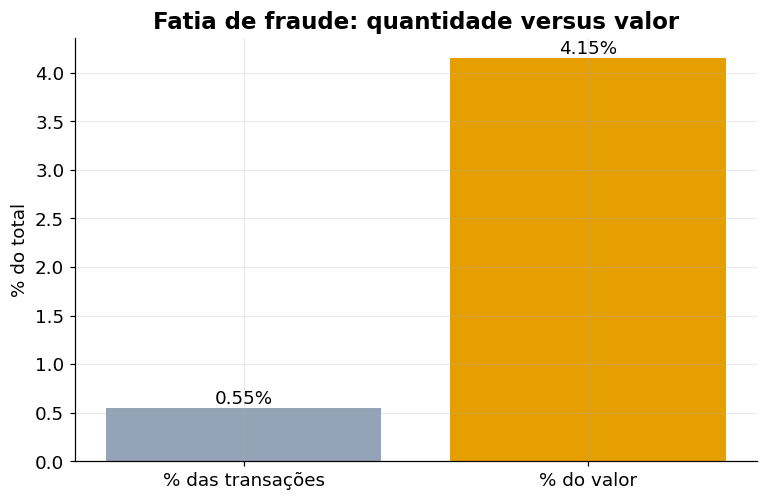

In [51]:
"""Fraud share by count versus by amount.

Fatia de fraude por quantidade versus por valor.
"""

r = resumo.row(0, named=True)
pct_qtd = r["n_fraudes"] / r["n_transacoes"] * 100
pct_valor = r["valor_fraude"] / r["valor_total"] * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(["% das transações", "% do valor"], [pct_qtd, pct_valor], color=[COR_SECUNDARIA, COR_DESTAQUE])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_title("Fatia de fraude: quantidade versus valor")
ax.set_ylabel("% do total")
plt.show()

In [52]:
"""Build a uniform sample with numeric features for the correlation matrix.
Cria uma amostra uniforme com variáveis numéricas para a matriz de correlação.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# every 30th row gives about 1.1M rows and keeps the real fraud rate / uma a cada 30 linhas dá cerca de 1,1M linhas e mantém a taxa real de fraude
amostra = (
    lazy.with_row_index("idx")
    .filter(pl.col("idx") % 30 == 0)
    .select(
        pl.col("amt").alias("valor"),
        pl.col("city_pop").alias("pop_cidade"),
        pl.col("lat").alias("lat_cliente"),
        pl.col("long").alias("long_cliente"),
        pl.col("merch_lat").alias("lat_comerc"),
        pl.col("merch_long").alias("long_comerc"),
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        ((pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25).alias("idade"),
        pl.col("trans_dt").dt.hour().alias("hora"),
        pl.col("trans_dt").dt.weekday().alias("dia_semana"),
        pl.col("trans_dt").dt.month().alias("mes"),
        pl.col("is_fraud").cast(pl.Int8).alias("fraude"),
    )
    .collect()
    .to_pandas()
)
print(amostra.shape, "| fraud rate / taxa de fraude:", round(amostra["fraude"].mean() * 100, 3), "%")
amostra.head()

(1132481, 12) | fraud rate / taxa de fraude: 0.562 %


,valor,pop_cidade,lat_cliente,long_cliente,lat_comerc,long_comerc,distancia_km,idade,hora,dia_semana,mes,fraude
0,4.34,106426,37.7383,-121.4345,38.724545,-120.916415,118.634486,16.418891,21,5,2,1
1,333.56,54963,32.9346,-96.5544,32.319614,-95.615212,111.408347,21.286790,21,5,10,1
2,46.99,54963,32.9346,-96.5544,32.569317,-96.142178,55.998829,19.912389,0,7,5,0
3,71.65,54963,32.9346,-96.5544,32.439038,-96.843991,61.407907,19.731691,21,4,3,0
4,62.82,54963,32.9346,-96.5544,32.883135,-96.451553,11.177101,19.663244,6,7,2,0


In [53]:
"""Spearman correlation matrix, robust to the skewed amount column.

Matriz de correlação de Spearman, robusta à assimetria da coluna de valor.
"""

# spearman uses ranks, so outliers in amount do not dominate / spearman usa ranks, então outliers no valor não dominam
corr = amostra.corr(method="spearman")
corr["fraude"].drop("fraude").sort_values(key=abs, ascending=False).to_frame("corr_com_fraude")

,corr_com_fraude
valor,0.086822
hora,0.065267
idade,0.019051
dia_semana,-0.012615
mes,-0.011352
pop_cidade,0.003070
long_comerc,-0.000740
long_cliente,-0.000687
distancia_km,-0.000543
lat_comerc,-0.000384


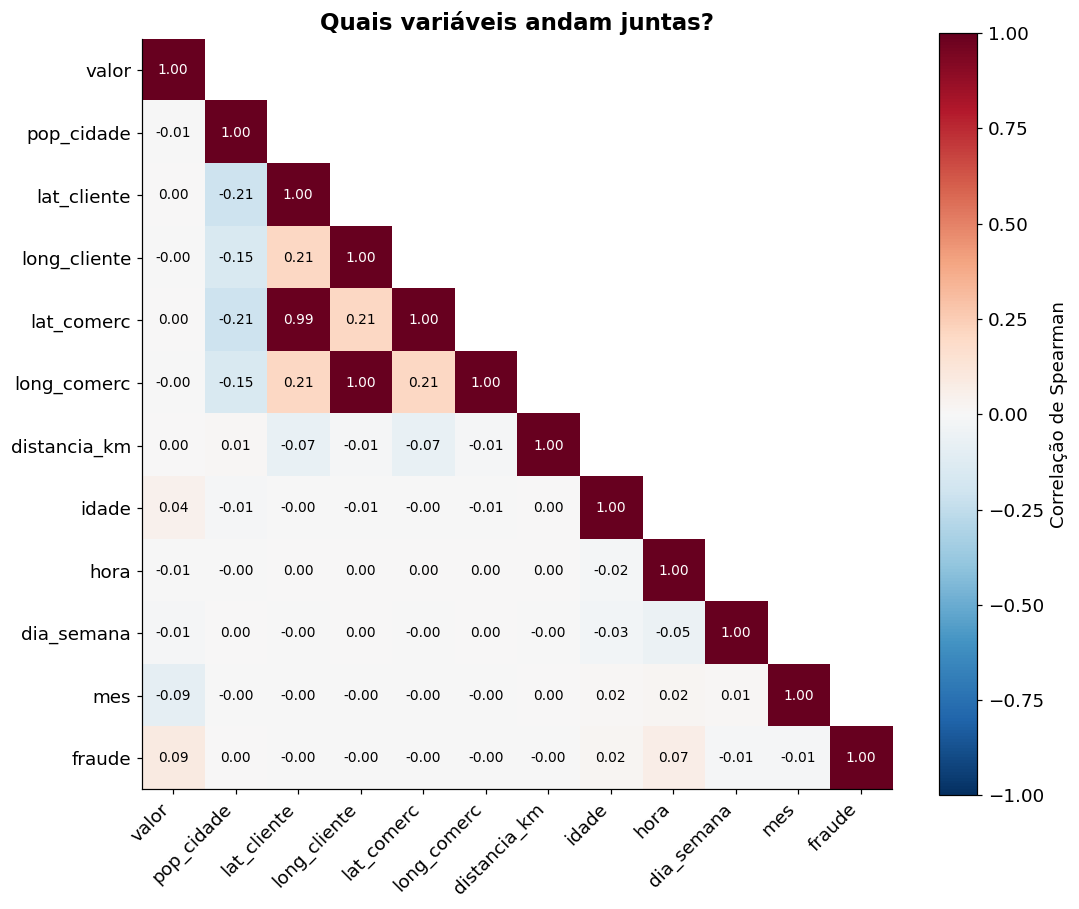

In [54]:
"""Lower-triangle heatmap of the correlation matrix.

Mapa de calor do triângulo inferior da matriz de correlação.
"""

# hide the upper triangle, it repeats the lower one / esconder o triângulo superior, que repete o inferior
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
valores = np.ma.array(corr.values, mask=mascara)

fig, ax = plt.subplots(figsize=(11, 9))
img = ax.imshow(valores, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)

# print the coefficient inside each visible square / escrever o coeficiente dentro de cada quadrado visível
for i in range(len(corr)):
    for j in range(i + 1):
        cor_texto = "white" if abs(corr.iloc[i, j]) > 0.6 else "black"
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color=cor_texto)

fig.colorbar(img, ax=ax, label="Correlação de Spearman")
ax.set_title("Quais variáveis andam juntas?")
plt.show()

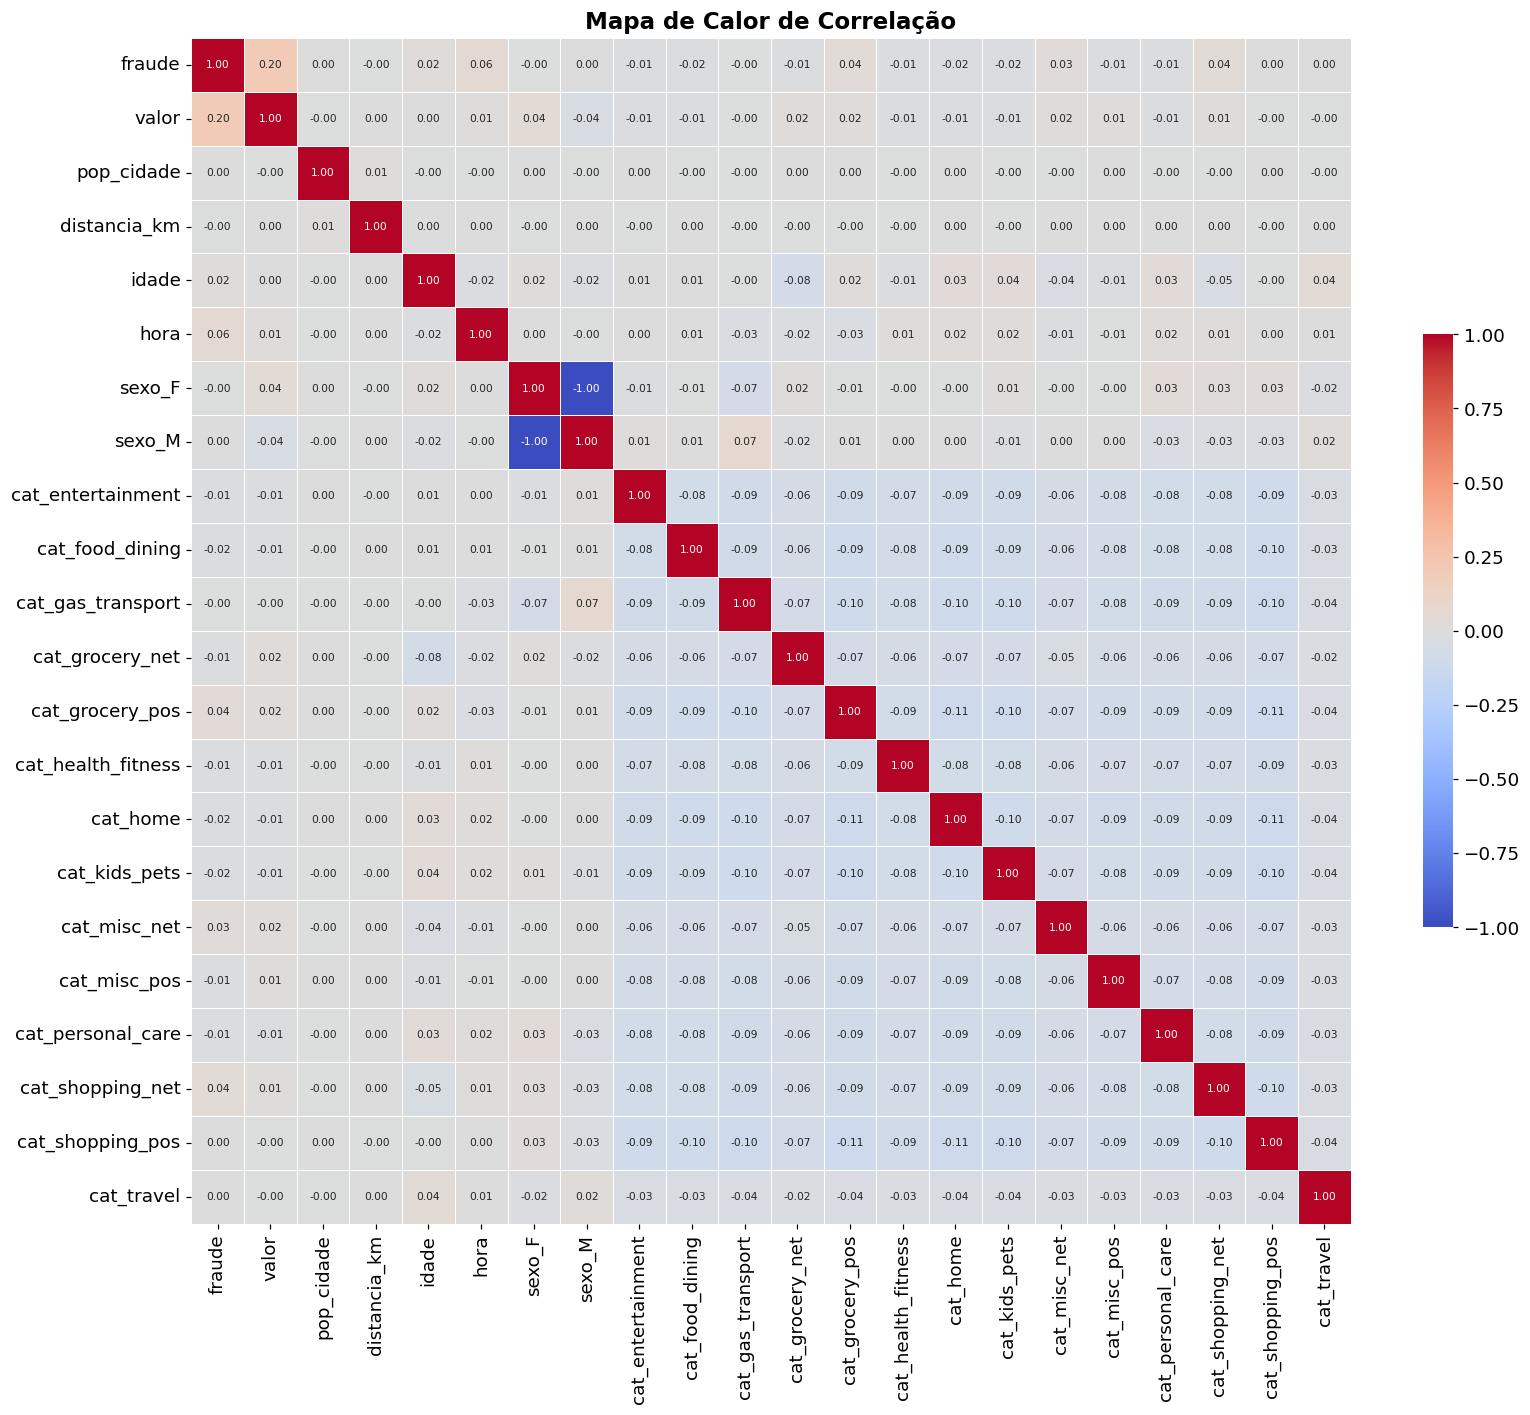

In [55]:
"""Seaborn correlation heatmap with gender and purchase categories as dummies.

Mapa de calor de correlação em seaborn com gênero e categorias de compra em colunas de sim/não.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# every 30th row keeps the real fraud rate, about 1.1M rows / uma a cada 30 linhas mantém a taxa real de fraude, cerca de 1,1M linhas
base = (
    lazy.with_row_index("idx")
    .filter(pl.col("idx") % 30 == 0)
    .select(
        pl.col("amt").alias("valor"),
        pl.col("city_pop").alias("pop_cidade"),
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        ((pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25).alias("idade"),
        pl.col("trans_dt").dt.hour().alias("hora"),
        pl.col("gender").alias("sexo"),
        pl.col("category").alias("cat"),
        pl.col("is_fraud").cast(pl.Int8).alias("fraude"),
    )
    .collect()
    .to_pandas()
)

# one column per gender and per category / uma coluna por gênero e por categoria
dados = pd.get_dummies(base, columns=["sexo", "cat"], dtype=int)

# fraud first, then the other columns / fraude primeiro, depois as demais colunas
colunas = ["fraude"] + [c for c in dados.columns if c != "fraude"]
corr = dados[colunas].corr()

# palette name, try: coolwarm, RdBu_r, vlag, Spectral_r, PiYG / nome da paleta, teste: coolwarm, RdBu_r, vlag, Spectral_r, PiYG
PALETA_MAPA = "coolwarm"

fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=PALETA_MAPA,
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.5},
    ax=ax,
)
ax.grid(False)
ax.set_title("Mapa de Calor de Correlação")
plt.show()

C:\Users\rafae\AppData\Local\Temp\ipykernel_39044\1244424228.py:12: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  lazy.with_columns(idade.cut(quebras_idade, labels=rotulos_idade).cast(pl.String).alias("faixa_idade"))


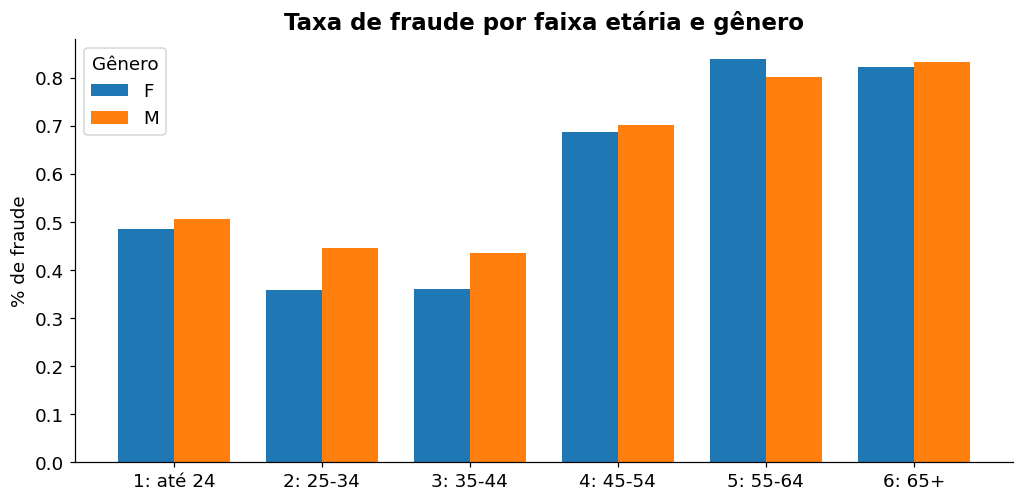

faixa_idade,gender,n,n_fraudes,taxa_pct
str,str,u32,u32,f64
"""1: até 24""","""F""",3084902,14991,0.485947
"""1: até 24""","""M""",3166518,16059,0.50715
"""2: 25-34""","""F""",3985541,14330,0.35955
"""2: 25-34""","""M""",3388133,15127,0.44647
"""3: 35-44""","""F""",3898069,14037,0.360101
"""3: 35-44""","""M""",3636319,15862,0.43621
"""4: 45-54""","""F""",2440625,16764,0.686873
"""4: 45-54""","""M""",2493001,17503,0.702086
"""5: 55-64""","""F""",1847328,15512,0.839699


In [56]:
"""Fraud rate by age band and gender.

Taxa de fraude por faixa etária e gênero.
"""

# age at the purchase date, in years / idade na data da compra, em anos
idade = (pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25
quebras_idade = [24, 34, 44, 54, 64]
rotulos_idade = ["1: até 24", "2: 25-34", "3: 35-44", "4: 45-54", "5: 55-64", "6: 65+"]

perfil = (
    lazy.with_columns(idade.cut(quebras_idade, labels=rotulos_idade).cast(pl.String).alias("faixa_idade"))
    .group_by("faixa_idade", "gender")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("faixa_idade", "gender")
    .collect()
)

"""Grouped bars of fraud rate by age band, one bar per gender.

Barras agrupadas da taxa de fraude por faixa etária, uma barra por gênero.
"""

fig, ax = plt.subplots(figsize=(11, 5))
faixas_ordem = sorted(perfil["faixa_idade"].unique().to_list())
largura = 0.38
for i, genero in enumerate(sorted(perfil["gender"].unique().to_list())):
    sub = perfil.filter(pl.col("gender") == genero).sort("faixa_idade")
    posicoes = [faixas_ordem.index(f) + i * largura for f in sub["faixa_idade"].to_list()]
    ax.bar(posicoes, sub["taxa_pct"].to_list(), width=largura, label=genero)
ax.set_xticks([p + largura / 2 for p in range(len(faixas_ordem))], faixas_ordem)
ax.set_ylabel("% de fraude")
ax.set_title("Taxa de fraude por faixa etária e gênero")
ax.legend(title="Gênero")
plt.grid(False)
plt.show()

perfil

# **Part 7 - Outlier Analysis**

In [57]:
"""Rebuild the original columns, the cutoff and the temporal train split.
Refaz as colunas originais, o corte e a divisão temporal do treino.
"""

# raw file with the cutoff for incomplete fraud labels / arquivo bruto com o corte para rótulos de fraude incompletos
lazy = pl.scan_parquet(PARQUET_PATH).filter(pl.col("trans_dt") < pl.datetime(2020, 12, 24))

# original columns only, trans_dt is just the split key / só colunas originais, trans_dt é apenas a chave da divisão
num_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
cat_cols = ["category", "gender", "state"]
base = lazy.select(["trans_dt"] + num_cols + cat_cols + ["is_fraud"])

# train until June 2020, outlier fences use this set only / treino até junho de 2020, os limites de outliers usam só este conjunto
treino = base.filter(pl.col("trans_dt") < pl.datetime(2020, 7, 1))
validacao = base.filter((pl.col("trans_dt") >= pl.datetime(2020, 7, 1)) & (pl.col("trans_dt") < pl.datetime(2020, 10, 1)))
teste = base.filter(pl.col("trans_dt") >= pl.datetime(2020, 10, 1))

# confirm columns and size of train / confirmar colunas e tamanho do treino
print(treino.collect_schema().names())
print("Train rows / Linhas de treino:", treino.select(pl.len()).collect().item())

['trans_dt', 'amt', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long', 'category', 'gender', 'state', 'is_fraud']
Train rows / Linhas de treino: 24853976


In [58]:
"""Compute IQR fences from the training set only.

Calcula os limites do intervalo interquartil só com o conjunto de treino.
"""

# first and third quartiles of every numeric column in train / 1º e 3º quartis de cada coluna numérica no treino
quartis = treino.select(
    [pl.col(c).quantile(0.25).alias(f"{c}__q1") for c in num_cols]
    + [pl.col(c).quantile(0.75).alias(f"{c}__q3") for c in num_cols]
).collect()

# lower and upper fence per column / limite inferior e superior por coluna
limites = {}
for c in num_cols:
    q1, q3 = quartis[f"{c}__q1"][0], quartis[f"{c}__q3"][0]
    amplitude = q3 - q1
    limites[c] = (q1 - 1.5 * amplitude, q3 + 1.5 * amplitude)

pl.DataFrame({
    "coluna": num_cols,
    "limite_inferior": [limites[c][0] for c in num_cols],
    "limite_superior": [limites[c][1] for c in num_cols],
})

coluna,limite_inferior,limite_superior
str,f64,f64
"""amt""",-102.115,195.365
"""city_pop""",-310702.0,565338.0
"""lat""",22.89335,52.23615
"""long""",-126.4177,-52.0753
"""merch_lat""",22.694047,52.471571
"""merch_long""",-127.391717,-51.10556


In [59]:
"""Outlier count per column and fraud rate inside versus outside the fences.

Contagem de valores extremos por coluna e taxa de fraude dentro e fora dos limites.
"""

linhas = []
for c in num_cols:
    inferior, superior = limites[c]
    fora = (pl.col(c) < inferior) | (pl.col(c) > superior)
    linha = treino.select(
        pl.len().alias("n"),
        fora.sum().alias("n_outliers"),
        pl.col("is_fraud").filter(fora).sum().alias("fraudes_nos_outliers"),
        pl.col("is_fraud").sum().alias("fraudes_total"),
        (pl.col("is_fraud").filter(fora).mean() * 100).alias("taxa_fraude_fora_pct"),
        (pl.col("is_fraud").filter(~fora).mean() * 100).alias("taxa_fraude_dentro_pct"),
    ).collect().with_columns(pl.lit(c).alias("coluna"))
    linhas.append(linha)

outliers = pl.concat(linhas).with_columns(
    (pl.col("n_outliers") / pl.col("n") * 100).alias("pct_outliers"),
    (pl.col("fraudes_nos_outliers") / pl.col("fraudes_total") * 100).alias("pct_das_fraudes_nos_outliers"),
).select(
    "coluna", "n", "n_outliers", "pct_outliers",
    "taxa_fraude_fora_pct", "taxa_fraude_dentro_pct", "pct_das_fraudes_nos_outliers",
)
outliers

coluna,n,n_outliers,pct_outliers,taxa_fraude_fora_pct,taxa_fraude_dentro_pct,pct_das_fraudes_nos_outliers
str,u32,u32,f64,f64,f64,f64
"""amt""",24853976,1659162,6.67564,6.615448,0.14492,76.555187
"""city_pop""",24853976,4025290,16.195759,0.594168,0.573526,16.68143
"""lat""",24853976,178846,0.719587,0.549076,0.577071,0.684917
"""long""",24853976,178846,0.719587,0.549076,0.577071,0.684917
"""merch_lat""",24853976,177150,0.712763,0.549817,0.577064,0.679337
"""merch_long""",24853976,178846,0.719587,0.549076,0.577071,0.684917


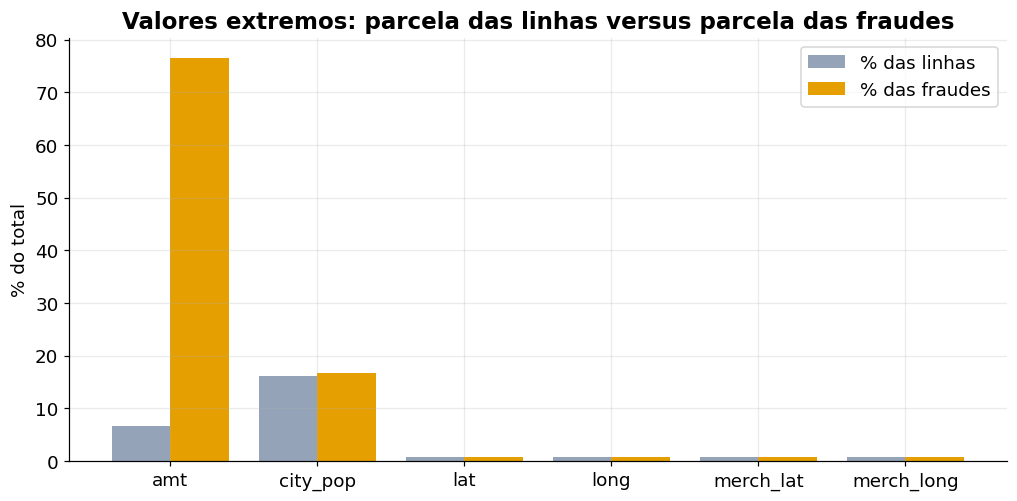

In [60]:
"""Share of rows versus share of frauds that fall in outliers, per column.

Parcela das linhas versus parcela das fraudes que caem em valores extremos, por coluna.
"""

colunas = outliers["coluna"].to_list()
posicoes = np.arange(len(colunas))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(posicoes - 0.2, outliers["pct_outliers"].to_list(), width=0.4, color=COR_SECUNDARIA, label="% das linhas")
ax.bar(posicoes + 0.2, outliers["pct_das_fraudes_nos_outliers"].to_list(), width=0.4, color=COR_DESTAQUE, label="% das fraudes")
ax.set_xticks(posicoes, colunas)
ax.set_ylabel("% do total")
ax.set_title("Valores extremos: parcela das linhas versus parcela das fraudes")
ax.legend()
plt.show()

In [61]:
# stable row key for a reproducible sample / chave estável da linha para uma amostra reprodutível
chave = pl.struct(["trans_dt", "amt", "lat", "long"])

amostra_box = (
    pl.concat([
        treino.filter(pl.col("is_fraud")),
        treino.filter(~pl.col("is_fraud") & (chave.hash(seed=11) % 100 == 0)),
    ])
    .select(num_cols + ["is_fraud"])
    .collect()
    .to_pandas()
)
print(amostra_box.groupby("is_fraud").size().to_frame("n"))

               n
is_fraud        
False     247362
True      143375


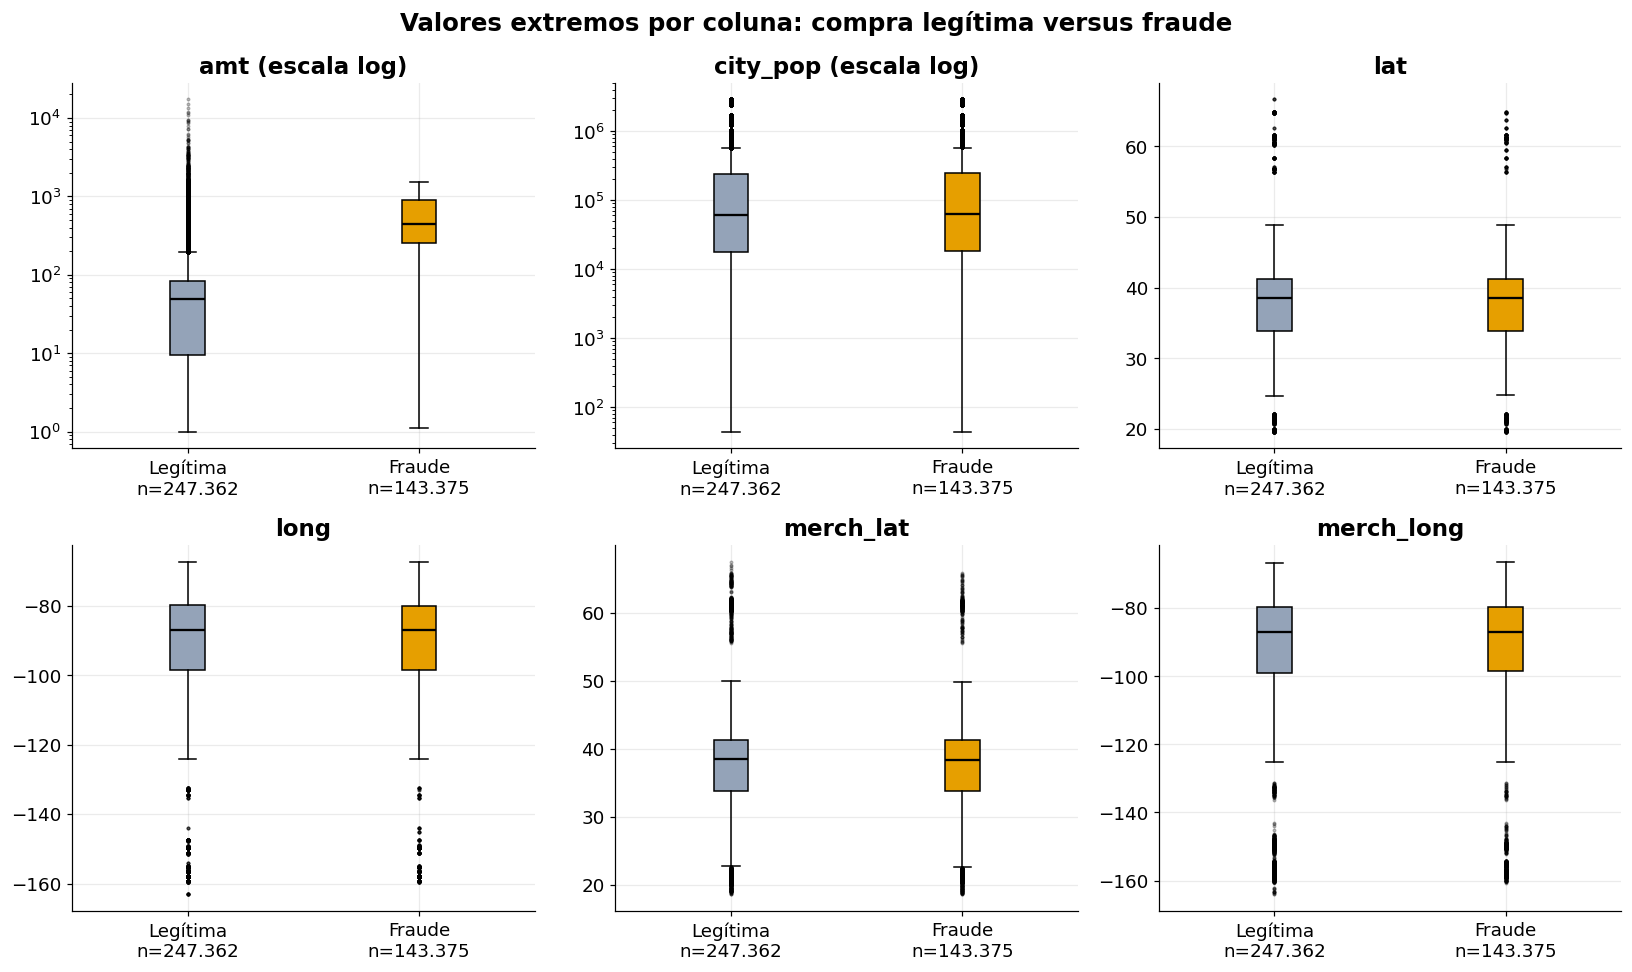

In [62]:
"""Boxplot of each numeric column, legit versus fraud, with outliers as dots.

Boxplot de cada coluna numérica, legítima versus fraude, com os valores extremos como pontos.
"""

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, c in zip(axes.ravel(), num_cols):
    legit = amostra_box.loc[~amostra_box["is_fraud"], c]
    fraude = amostra_box.loc[amostra_box["is_fraud"], c]

    # n shown under each box / n mostrado embaixo de cada caixa
    n_legit = f"{len(legit):,}".replace(",", ".")
    n_fraude = f"{len(fraude):,}".replace(",", ".")

    caixas = ax.boxplot(
        [legit, fraude],
        tick_labels=[f"Legítima\nn={n_legit}", f"Fraude\nn={n_fraude}"],
        patch_artist=True,
        flierprops={"marker": ".", "markersize": 3, "alpha": 0.35},
        medianprops={"color": "black", "linewidth": 1.5},
    )
    for caixa, cor in zip(caixas["boxes"], [COR_SECUNDARIA, COR_DESTAQUE]):
        caixa.set_facecolor(cor)

    # long tailed columns on log scale / colunas com cauda longa em escala log
    if c in ["amt", "city_pop"]:
        ax.set_yscale("log")
        ax.set_title(f"{c} (escala log)")
    else:
        ax.set_title(c)

fig.suptitle("Valores extremos por coluna: compra legítima versus fraude", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado:**  O boxplot mostra que o único campo em que os valores extremos têm a ver com a fraude é o amt, e que nenhum valor é impossível. Nos outros cinco campos as duas caixas são praticamente idênticas, e os pontos extremos são lugares reais e cidades grandes.

# **Part 8 - Handling outliers using z-score**

**Which values ​​are more than 3 standard deviations away from the mean?**

We will calculate the z-score for each numerical column and count how many rows have an absolute value greater than 3. Alongside this, I show what proportion of the fraud cases fall into these extremes, helping to determine whether they represent errors or meaningful signals.

In [63]:
"""Compute mean and standard deviation per column on the training set only.

Calcula média e desvio padrão por coluna só no conjunto de treino.
"""

# one row with mean and std of every numeric column / uma linha com média e desvio padrão de cada coluna numérica
estatisticas = treino.select(
    [pl.col(c).mean().alias(f"{c}__media") for c in num_cols]
    + [pl.col(c).std().alias(f"{c}__desvio") for c in num_cols]
).collect()

media_desvio = {c: (estatisticas[f"{c}__media"][0], estatisticas[f"{c}__desvio"][0]) for c in num_cols}

pl.DataFrame({
    "coluna": num_cols,
    "media": [media_desvio[c][0] for c in num_cols],
    "desvio_padrao": [media_desvio[c][1] for c in num_cols],
})

coluna,media,desvio_padrao
str,f64,f64
"""amt""",73.276269,154.655804
"""city_pop""",296495.255206,570052.367405
"""lat""",37.573724,5.187079
"""long""",-91.934881,16.4669
"""merch_lat""",37.573693,5.219063
"""merch_long""",-91.934681,16.476857


In [64]:
"""Count rows with absolute z-score above 3 and the fraud share inside them.

Conta linhas com z-score absoluto acima de 3 e a parcela de fraude dentro delas.
"""

LIMITE_Z = 3

linhas = []
for c in num_cols:
    media, desvio = media_desvio[c]
    fora = ((pl.col(c) - media) / desvio).abs() > LIMITE_Z
    linha = treino.select(
        pl.len().alias("n"),
        fora.sum().alias("n_outliers"),
        pl.col("is_fraud").filter(fora).sum().alias("fraudes_nos_outliers"),
        pl.col("is_fraud").sum().alias("fraudes_total"),
        (pl.col("is_fraud").filter(fora).mean() * 100).alias("taxa_fraude_fora_pct"),
        (pl.col("is_fraud").filter(~fora).mean() * 100).alias("taxa_fraude_dentro_pct"),
    ).collect().with_columns(pl.lit(c).alias("coluna"))
    linhas.append(linha)

outliers_z = pl.concat(linhas).with_columns(
    (pl.col("n_outliers") / pl.col("n") * 100).alias("pct_outliers"),
    (pl.col("fraudes_nos_outliers") / pl.col("fraudes_total") * 100).alias("pct_das_fraudes_nos_outliers"),
).select(
    "coluna", "n", "n_outliers", "pct_outliers",
    "fraudes_nos_outliers", "taxa_fraude_fora_pct", "taxa_fraude_dentro_pct", "pct_das_fraudes_nos_outliers",
)
outliers_z

coluna,n,n_outliers,pct_outliers,fraudes_nos_outliers,taxa_fraude_fora_pct,taxa_fraude_dentro_pct,pct_das_fraudes_nos_outliers
str,u32,u32,f64,u32,f64,f64,f64
"""amt""",24853976,281318,1.131883,69862,24.833818,0.299166,48.726765
"""city_pop""",24853976,884139,3.557334,4847,0.548217,0.577926,3.380645
"""lat""",24853976,175152,0.704724,956,0.545812,0.57709,0.666783
"""long""",24853976,166285,0.669048,942,0.566497,0.576939,0.657018
"""merch_lat""",24853976,152319,0.612856,845,0.554757,0.577006,0.589364
"""merch_long""",24853976,166285,0.669048,942,0.566497,0.576939,0.657018


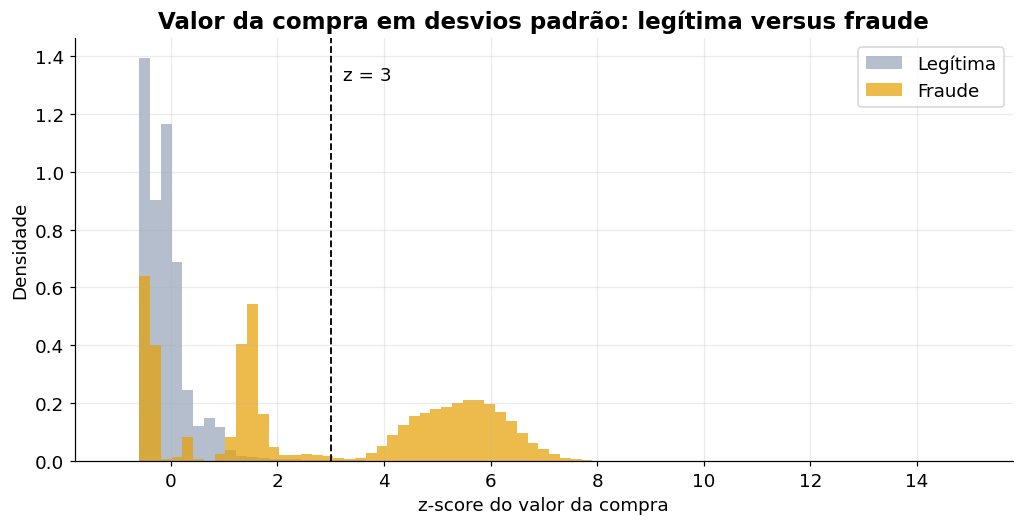

In [65]:
"""Histogram of the amount z-score for legit and fraud with the plus and minus 3 lines.

Histograma do z-score do valor para legítima e fraude com as linhas de mais e menos 3.
"""

# z-score of amt using train mean and std, on the boxplot sample / z-score do amt com média e desvio do treino, na amostra do boxplot
media_amt, desvio_amt = media_desvio["amt"]
amostra_box["z_amt"] = (amostra_box["amt"] - media_amt) / desvio_amt

fig, ax = plt.subplots(figsize=(11, 5))
limites_hist = np.linspace(-1, 15, 80)
ax.hist(amostra_box.loc[~amostra_box["is_fraud"], "z_amt"], bins=limites_hist, density=True, alpha=0.7, color=COR_SECUNDARIA, label="Legítima")
ax.hist(amostra_box.loc[amostra_box["is_fraud"], "z_amt"], bins=limites_hist, density=True, alpha=0.7, color=COR_DESTAQUE, label="Fraude")
ax.axvline(LIMITE_Z, color="black", linestyle="--", linewidth=1.2)
ax.annotate("z = 3", (LIMITE_Z, ax.get_ylim()[1] * 0.9), xytext=(8, 0), textcoords="offset points")
ax.set_xlabel("z-score do valor da compra")
ax.set_ylabel("Densidade")
ax.set_title("Valor da compra em desvios padrão: legítima versus fraude")
ax.legend()
plt.show()

In [66]:
"""Build the clipping limits from the training statistics only.

Monta os limites de corte usando só as estatísticas do treino.
"""

# columns to treat, add the coordinates here only if you want them clipped too / colunas a tratar, inclua as coordenadas aqui só se quiser limitá-las também
COLUNAS_TRATAR = ["amt", "city_pop"]
LIMITE_Z = 3

# lower and upper limit as mean plus or minus 3 std of train / limite inferior e superior como média mais ou menos 3 desvios do treino
limites_corte = {
    c: (media_desvio[c][0] - LIMITE_Z * media_desvio[c][1], media_desvio[c][0] + LIMITE_Z * media_desvio[c][1])
    for c in COLUNAS_TRATAR
}

pl.DataFrame({
    "coluna": COLUNAS_TRATAR,
    "limite_inferior": [limites_corte[c][0] for c in COLUNAS_TRATAR],
    "limite_superior": [limites_corte[c][1] for c in COLUNAS_TRATAR],
})

coluna,limite_inferior,limite_superior
str,f64,f64
"""amt""",-390.691144,537.243682
"""city_pop""",-1.4137e6,2.0067e6


In [67]:
"""Apply the clipping to a copy of the sample, keeping the original for comparison.

Aplica o corte em uma cópia da amostra, mantendo a original para comparação.
"""

# the same columns, only values beyond the limits change / as mesmas colunas, só mudam os valores além dos limites
amostra_depois = amostra_box.copy()
for c, (inferior, superior) in limites_corte.items():
    amostra_depois[c] = amostra_depois[c].clip(lower=inferior, upper=superior)

amostra_depois[COLUNAS_TRATAR].describe().T[["min", "50%", "max"]]

,min,50%,max
amt,1.0,70.63,5.372437e+02
city_pop,44.0,62097.00,2.006652e+06


In [68]:
"""Exact count of rows and frauds changed by the clipping in the full training set.

Contagem exata de linhas e fraudes alteradas pelo corte em todo o conjunto de treino.
"""

linhas = []
for c, (inferior, superior) in limites_corte.items():
    alterada = (pl.col(c) < inferior) | (pl.col(c) > superior)
    linhas.append(
        treino.select(
            pl.lit(c).alias("coluna"),
            pl.len().alias("n"),
            alterada.sum().alias("linhas_alteradas"),
            pl.col("is_fraud").filter(alterada).sum().alias("fraudes_alteradas"),
            pl.col("is_fraud").sum().alias("fraudes_total"),
        ).collect()
    )

pl.concat(linhas).with_columns(
    (pl.col("linhas_alteradas") / pl.col("n") * 100).alias("pct_linhas"),
    (pl.col("fraudes_alteradas") / pl.col("fraudes_total") * 100).alias("pct_fraudes"),
)

coluna,n,linhas_alteradas,fraudes_alteradas,fraudes_total,pct_linhas,pct_fraudes
str,u32,u32,u32,u32,f64,f64
"""amt""",24853976,281318,69862,143375,1.131883,48.726765
"""city_pop""",24853976,884139,4847,143375,3.557334,3.380645


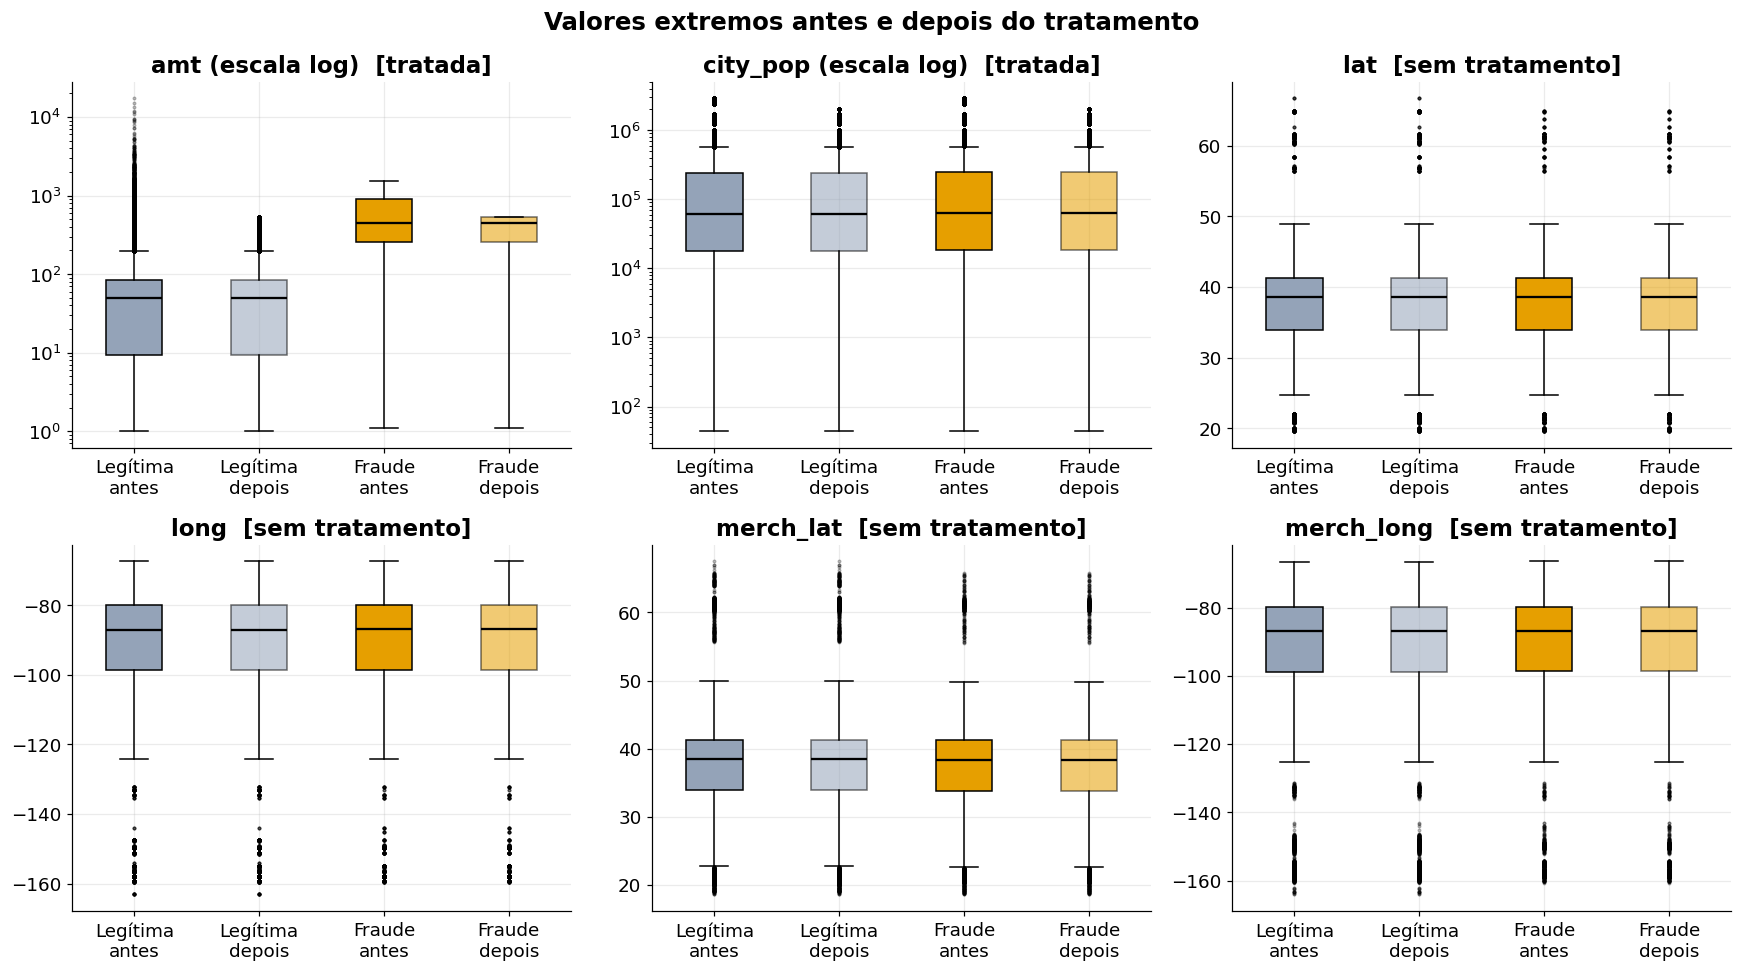

In [69]:
"""Boxplot before and after the treatment, legit and fraud side by side.

Boxplot antes e depois do tratamento, legítima e fraude lado a lado.
"""

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
rotulos = ["Legítima\nantes", "Legítima\ndepois", "Fraude\nantes", "Fraude\ndepois"]
cores = [COR_SECUNDARIA, COR_SECUNDARIA, COR_DESTAQUE, COR_DESTAQUE]

for ax, c in zip(axes.ravel(), num_cols):
    mascara = amostra_box["is_fraud"]
    grupos = [
        amostra_box.loc[~mascara, c], amostra_depois.loc[~mascara, c],
        amostra_box.loc[mascara, c], amostra_depois.loc[mascara, c],
    ]
    caixas = ax.boxplot(
        grupos,
        tick_labels=rotulos,
        patch_artist=True,
        flierprops={"marker": ".", "markersize": 3, "alpha": 0.35},
        medianprops={"color": "black", "linewidth": 1.5},
    )
    for caixa, cor, i in zip(caixas["boxes"], cores, range(4)):
        caixa.set_facecolor(cor)
        # lighter fill for the after boxes / preenchimento mais claro nas caixas de depois
        caixa.set_alpha(1.0 if i in (0, 2) else 0.55)

    # long tailed columns on log scale / colunas com cauda longa em escala log
    sufixo = ""
    if c in ["amt", "city_pop"]:
        ax.set_yscale("log")
        sufixo = " (escala log)"
    ax.set_title(f"{c}{sufixo}" + ("  [tratada]" if c in COLUNAS_TRATAR else "  [sem tratamento]"))

fig.suptitle("Valores extremos antes e depois do tratamento", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

Resultado: o antes e depois mostra que o tratamento funciona em city_pop e prejudica o amt. O ponto central é a caixa da fraude em amt, que encolheu. Os números abaixo foram lidos no gráfico, então são aproximados.

**amt**, legítima: o limite fica em cerca de 540 dólares. Os pontos acima dele sumiram, e a caixa (de cerca de 9 a 85) e a mediana não mudaram. Sobraram pontos entre cerca de 200 e 540. Eles são extremos pela regra do boxplot, mas ficam dentro de 3 desvios, então o corte não os tocou.

**amt**, fraude: a parte de cima da caixa caiu de cerca de 900 para cerca de 540, e o bigode superior de cerca de 1.500 para 540. A borda da caixa só desce até o limite quando mais de um quarto das fraudes estava acima dele, então pelo menos 25% das fraudes foram alteradas. A mediana quase não se mexeu, perto de 450.

**city_pop**: o limite fica em cerca de 2 milhões e o máximo caiu de cerca de 3 milhões para esse valor. As caixas e as medianas ficaram iguais, então o corte só mexeu em umas poucas cidades muito grandes, sem efeito prático.
Coordenadas: as quatro caixas ficaram idênticas antes e depois, como esperado, porque não foram tratadas.

**Conclusão: tratamento de valores extremos**

**Diagnóstico.** Os limites foram calculados só no conjunto de treino (média e desvio padrão, ou quartis), e a mesma regra vale para validação e teste. Nenhuma coluna tem valor impossível: o menor valor de compra é de cerca de 1 dólar, as latitudes e longitudes ficam dentro dos limites do planeta e os pontos extremos de coordenadas são Alasca e Havaí, que são lugares válidos. Os extremos de população são cidades grandes.

**Teste do tratamento.** Limitamos em 3 desvios padrão o valor da compra e a população da cidade, sem remover linhas. O resultado:

- **Valor da compra:** o corte fica em cerca de 540 dólares e alterou pelo menos um quarto das fraudes, porque a fraude se concentra entre 250 e 1.250 dólares. Todas as compras acima do limite passam a ter o mesmo valor, e o modelo perde o sinal que separa a fraude da compra legítima grande.
- **População da cidade:** o corte quase não mudou a distribuição, e também não traz ganho.
- **Coordenadas:** não precisam de tratamento.

**Decisão.** Não limitamos nem removemos valores extremos. Eles carregam sinal e são dado válido. Para a regressão logística e a rede neural, a escala é padronizada dentro do pipeline, com média e desvio ajustados só no treino. Os modelos de árvore não são sensíveis a extremos e usam os valores originais.

# Part 9 - SMOTE

In [70]:
"""Rebuild everything the SMOTENC cell needs: split, 1 to 10 train and validation.
Refaz tudo que a célula do SMOTENC precisa: divisão, treino 1 para 10 e validação.
"""

# raw file with the cutoff for incomplete fraud labels / arquivo bruto com o corte para rótulos de fraude incompletos
lazy = pl.scan_parquet(PARQUET_PATH).filter(pl.col("trans_dt") < pl.datetime(2020, 12, 24))

# original columns only, trans_dt is just the split key / só colunas originais, trans_dt é apenas a chave da divisão
num_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
cat_cols = ["category", "gender", "state"]
base = lazy.select(["trans_dt"] + num_cols + cat_cols + ["is_fraud"])

# train until June 2020, validation in Q3 / treino até junho de 2020, validação no 3º trimestre
treino = base.filter(pl.col("trans_dt") < pl.datetime(2020, 7, 1))
validacao = base.filter((pl.col("trans_dt") >= pl.datetime(2020, 7, 1)) & (pl.col("trans_dt") < pl.datetime(2020, 10, 1)))

# stable row key for reproducible sampling / chave estável da linha para amostragem reprodutível
chave = pl.struct(["trans_dt", "amt", "lat", "long"])

# class counts of the training set / contagem de classes do conjunto de treino
contagem_treino = treino.select(pl.len().alias("n"), pl.col("is_fraud").sum().alias("fraudes")).collect()
n_fraudes = int(contagem_treino["fraudes"][0])
n_legitimas = int(contagem_treino["n"][0]) - n_fraudes

# undersampling 1 to 10, every fraud and 10 legit rows per fraud / subamostragem 1 para 10, todas as fraudes e 10 legítimas por fraude
fracao = 10 * n_fraudes / n_legitimas
variantes = {
    "subamostragem 1:10": pl.concat([
        treino.filter(pl.col("is_fraud")),
        treino.filter(~pl.col("is_fraud") & (chave.hash(seed=7) % 100000 < fracao * 100000)),
    ]).collect().to_pandas()
}

# validation keeps the real fraud rate, one fifth of the rows / validação mantém a taxa real de fraude, um quinto das linhas
validacao_df = validacao.filter(chave.hash(seed=3) % 5 == 0).collect().to_pandas()
taxa_validacao = validacao_df["is_fraud"].mean()

# empty comparison table, used only if the earlier comparison was not run / tabela de comparação vazia, usada só se a comparação anterior não foi rodada
if "resultados" not in globals():
    resultados = pl.DataFrame(schema={"tratamento": pl.String, "linhas_treino": pl.Int64, "pr_auc_validacao": pl.Float64})

df_1_10 = variantes["subamostragem 1:10"]
print(f"Train 1:10: {df_1_10.shape[0]:,} rows | fraud rate / taxa de fraude: {df_1_10['is_fraud'].mean() * 100:.2f}%")
print(f"Validation: {validacao_df.shape[0]:,} rows | fraud rate / taxa de fraude: {taxa_validacao * 100:.3f}%")

Train 1:10: 1,578,902 rows | fraud rate / taxa de fraude: 9.08%
Validation: 913,819 rows | fraud rate / taxa de fraude: 0.531%


**Resultado:** A reconstrução bate com o esperado. O treino 1:10 tem 1.577.177 linhas, com 9,09% de fraude, que é exatamente 1 fraude para cada 10 legítimas. Isso dá cerca de 143 mil fraudes e 1,43 milhão de legítimas, e o número de fraudes bate com o n=143.375 do boxplot. A validação tem 915.606 linhas com 0,540% de fraude, perto da taxa real de 0,56%. Ela tem cerca de 4.900 fraudes, base suficiente para a PR-AUC não oscilar por acaso.

In [71]:
"""Clip outliers at mean plus or minus 3 std, limits from the full train, same limits on validation.

Limita outliers em média mais ou menos 3 desvios, limites do treino completo, mesmos limites na validação.
"""

# columns to clip, start with city_pop only, add amt knowing it flattens the fraud signal / colunas a limitar, comece só com city_pop, inclua amt sabendo que achata o sinal da fraude
COLUNAS_TRATAR = ["city_pop"]
LIMITE_Z = 3

# mean and std come from the full training set, not from the undersampled one / média e desvio vêm do treino completo, não do subamostrado
estat = treino.select(
    [pl.col(c).mean().alias(f"{c}__media") for c in COLUNAS_TRATAR]
    + [pl.col(c).std().alias(f"{c}__desvio") for c in COLUNAS_TRATAR]
).collect()

limites_corte = {
    c: (estat[f"{c}__media"][0] - LIMITE_Z * estat[f"{c}__desvio"][0],
        estat[f"{c}__media"][0] + LIMITE_Z * estat[f"{c}__desvio"][0])
    for c in COLUNAS_TRATAR
}

# apply the same limits to the training variant and to validation / aplicar os mesmos limites na versão do treino e na validação
variantes["subamostragem 1:10"] = variantes["subamostragem 1:10"].copy()
for c, (inferior, superior) in limites_corte.items():
    for df_ in (variantes["subamostragem 1:10"], validacao_df):
        n_alterados = int(((df_[c] < inferior) | (df_[c] > superior)).sum())
        df_[c] = df_[c].clip(lower=inferior, upper=superior)
        print(f"{c}: {n_alterados:,} values clipped / valores limitados | limits / limites: {inferior:,.0f} a {superior:,.0f}")

city_pop: 55,778 values clipped / valores limitados | limits / limites: -1,413,662 a 2,006,652
city_pop: 32,764 values clipped / valores limitados | limits / limites: -1,413,662 a 2,006,652


In [72]:
"""Run the whole SMOTENC step with tqdm progress bars: stages and elapsed time.
Executa toda a etapa do SMOTENC com barras de progresso tqdm: etapas e tempo decorrido.
"""

# outer bar with the 4 stages of the step / barra externa com as 4 etapas da etapa
etapas = tqdm(total=4, desc="SMOTENC pipeline", unit="etapa")

# stage 1: 1 to 10 undersampled train / etapa 1: treino subamostrado 1 para 10
etapas.set_postfix_str("copiando treino")
base_treino = variantes["subamostragem 1:10"].copy()
etapas.update(1)

# stage 2: scaler and encoder fitted on train only / etapa 2: padronizador e codificador ajustados só no treino
etapas.set_postfix_str("padronizando e codificando")
escalador = StandardScaler().fit(base_treino[num_cols])
codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(base_treino[cat_cols])

X_treino_base = np.hstack([
    escalador.transform(base_treino[num_cols]),
    codificador.transform(base_treino[cat_cols]),
])
y_treino = base_treino["is_fraud"].astype(int).values

# categorical columns sit after the numeric ones / colunas categóricas ficam depois das numéricas
indices_cat = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
etapas.update(1)

# stage 3: oversampling runs in a thread so the elapsed time bar can update / etapa 3: geração roda em uma thread para a barra de tempo poder atualizar
etapas.set_postfix_str("gerando fraudes sintéticas")
smote = SMOTENC(categorical_features=indices_cat, sampling_strategy=0.5, k_neighbors=5, random_state=42)

with ThreadPoolExecutor(max_workers=1) as executor:
    futuro = executor.submit(smote.fit_resample, X_treino_base, y_treino)
    with tqdm(desc="fit_resample", bar_format="{desc}: {elapsed} decorrido", leave=False) as relogio:
        while not futuro.done():
            time.sleep(1)
            relogio.update(1)
    X_smote, y_smote = futuro.result()
etapas.update(1)

# stage 4: summary / etapa 4: resumo
etapas.set_postfix_str("concluído")
etapas.update(1)
etapas.close()

print(f"Before / Antes: {len(y_treino):,} rows | fraud {y_treino.mean() * 100:.2f}%")
print(f"After / Depois: {len(y_smote):,} rows | fraud {y_smote.mean() * 100:.2f}%")

SMOTENC pipeline:   0%|          | 0/4 [00:00<?, ?etapa/s]

fit_resample: 00:00 decorrido

Before / Antes: 1,578,902 rows | fraud 9.08%
After / Depois: 2,153,290 rows | fraud 33.33%


In [73]:
smote

SMOTENC(categorical_features=[6, 7, 8], random_state=42, sampling_strategy=0.5)

In [74]:
"""Split the SMOTENC output into original rows and synthetic rows, in real units.

Separa a saída do SMOTENC em linhas originais e sintéticas, em unidades reais.
"""

# imblearn appends the synthetic rows after the original ones / o imblearn adiciona as linhas sintéticas depois das originais
n_original = len(y_treino)

# numeric columns back to dollars, people and degrees / colunas numéricas de volta para dólares, pessoas e graus
valores_reais = escalador.inverse_transform(X_smote[:, :len(num_cols)])
df_depois = pd.DataFrame(valores_reais, columns=num_cols)
df_depois["is_fraud"] = y_smote.astype(bool)
df_depois["sintetica"] = np.arange(len(y_smote)) >= n_original

# only synthetic rows should be fraud, so the original rows must match the input / só as sintéticas devem ser fraude, então as originais precisam bater com a entrada
print("Original rows match / Linhas originais conferem:", bool((df_depois["is_fraud"].values[:n_original] == y_treino.astype(bool)).all()))
df_depois.groupby(["is_fraud", "sintetica"]).size().to_frame("n")

Original rows match / Linhas originais conferem: True


n
is_fraud sintetica         
False    False      1435527
True     False       143375
         True        574388

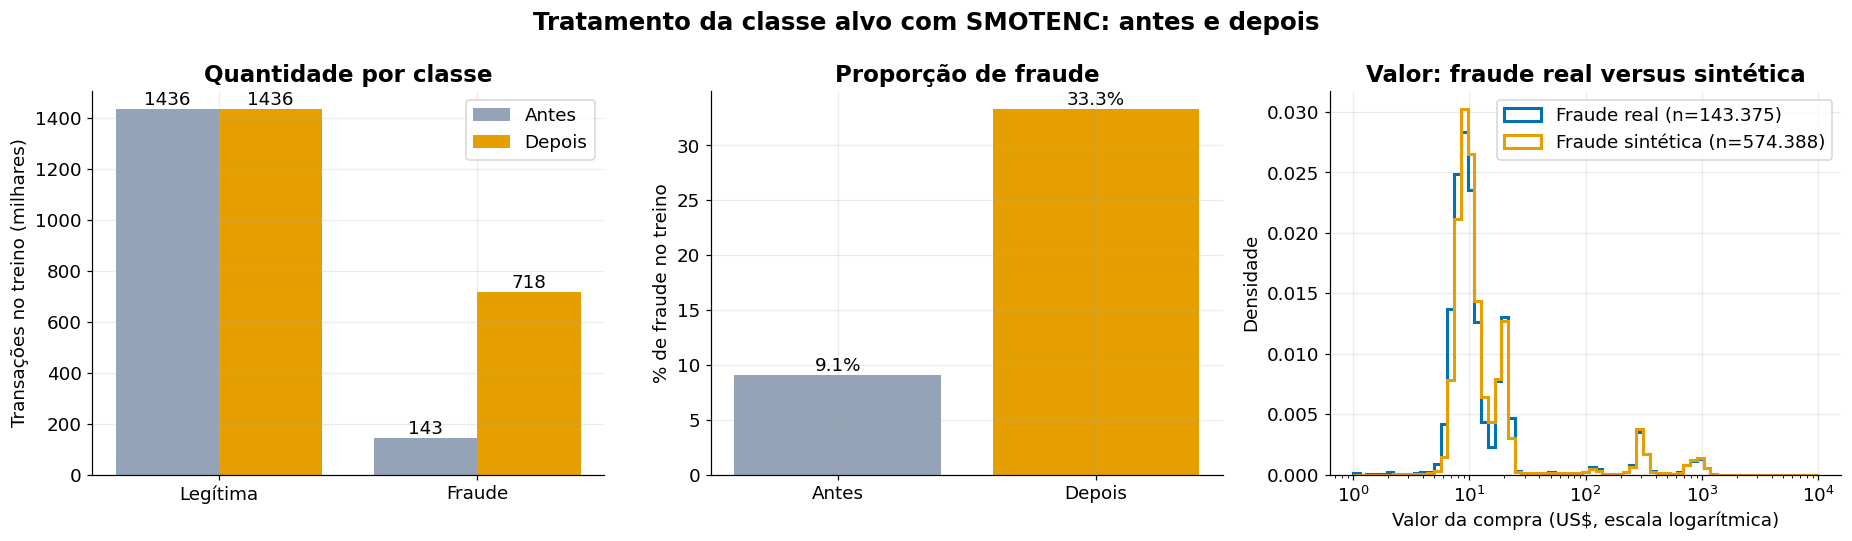

Real fraud amt range / Faixa do valor, fraude real: 1 a 1,525
Synthetic fraud amt range / Faixa do valor, fraude sintética: 2 a 1,512


In [75]:
"""Before and after SMOTENC: class counts, fraud share and amount of real versus synthetic fraud.

Antes e depois do SMOTENC: contagem de classes, parcela de fraude e valor da fraude real versus sintética.
"""

# class counts before and after, in thousands / contagem de classes antes e depois, em milhares
antes = np.bincount(y_treino.astype(int)) / 1e3
depois = np.bincount(y_smote.astype(int)) / 1e3

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))

# panel 1: counts per class / painel 1: contagem por classe
posicoes = np.arange(2)
ax1.bar(posicoes - 0.2, antes, width=0.4, color=COR_SECUNDARIA, label="Antes")
ax1.bar(posicoes + 0.2, depois, width=0.4, color=COR_DESTAQUE, label="Depois")
ax1.bar_label(ax1.containers[0], fmt="%.0f")
ax1.bar_label(ax1.containers[1], fmt="%.0f")
ax1.set_xticks(posicoes, ["Legítima", "Fraude"])
ax1.set_ylabel("Transações no treino (milhares)")
ax1.set_title("Quantidade por classe")
ax1.legend()

# panel 2: fraud share before and after / painel 2: parcela de fraude antes e depois
parcelas = [y_treino.mean() * 100, y_smote.mean() * 100]
ax2.bar(["Antes", "Depois"], parcelas, color=[COR_SECUNDARIA, COR_DESTAQUE])
ax2.bar_label(ax2.containers[0], fmt="%.1f%%")
ax2.set_ylabel("% de fraude no treino")
ax2.set_title("Proporção de fraude")

# panel 3: amount of real versus synthetic fraud / painel 3: valor da fraude real versus sintética
real = df_depois.loc[df_depois["is_fraud"] & ~df_depois["sintetica"], "amt"]
sintetica = df_depois.loc[df_depois["sintetica"], "amt"]
faixas = np.logspace(0, 4, 70)
ax3.hist(real, bins=faixas, density=True, histtype="step", linewidth=2, color=COR_PRIMARIA, label=f"Fraude real (n={len(real):,})".replace(",", "."))
ax3.hist(sintetica, bins=faixas, density=True, histtype="step", linewidth=2, color=COR_DESTAQUE, label=f"Fraude sintética (n={len(sintetica):,})".replace(",", "."))
ax3.set_xscale("log")
ax3.set_xlabel("Valor da compra (US$, escala logarítmica)")
ax3.set_ylabel("Densidade")
ax3.set_title("Valor: fraude real versus sintética")
ax3.legend()

fig.suptitle("Tratamento da classe alvo com SMOTENC: antes e depois", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Real fraud amt range / Faixa do valor, fraude real: {real.min():,.0f} a {real.max():,.0f}")
print(f"Synthetic fraud amt range / Faixa do valor, fraude sintética: {sintetica.min():,.0f} a {sintetica.max():,.0f}")

**Resultado:** o balanceamento funcionou e o SMOTENC preservou o desenho do valor da fraude. As contagens vêm dos rótulos do gráfico, e as formas das curvas são leitura visual.

**Quantidade:** as legítimas ficam em 1.434 mil antes e depois, e as fraudes vão de 143 mil para 717 mil (143.375 reais mais 573.526 sintéticas). A conta fecha: metade das legítimas é 716.901, que é o total de fraudes depois. O SMOTENC só acrescentou linhas de fraude e não mexeu nas legítimas.

**Proporção:** de 9,1% para 33,3%, que é 1 fraude para cada 2 legítimas, como definido no sampling_strategy=0.5.

**Valor da compra:** as curvas da fraude real e da sintética praticamente se sobrepõem. Os dois grupos têm o pico principal perto de 10 dólares, a segunda subida perto de 20 e as pequenas elevações perto de 300 e de 900. Esse era o teste que eu tinha proposto (se a sintética perdesse os picos, o SMOTENC teria borrado o desenho da fraude), e ele passou.

In [76]:
"""Check that only original columns reach the model and the SMOTENC step.

Confere que só colunas originais chegam ao modelo e à etapa do SMOTENC.
"""

colunas_usadas = num_cols + cat_cols

# every feature must exist in the original Parquet / toda variável precisa existir no Parquet original
parquet_colunas = pl.scan_parquet(PARQUET_PATH).collect_schema().names()
print("Features not in the original file / Variáveis fora do arquivo original:", [c for c in colunas_usadas if c not in parquet_colunas])

# train and validation frames, key and target included / treino e validação, com chave e alvo
print("Train columns / Colunas do treino:", list(variantes["subamostragem 1:10"].columns))
print("Validation columns / Colunas da validação:", list(validacao_df.columns))

# matrix given to SMOTENC has one column per original feature / matriz do SMOTENC tem uma coluna por variável original
print("SMOTENC input shape / Formato da entrada:", X_treino_base.shape, "| expected columns / colunas esperadas:", len(colunas_usadas))

Features not in the original file / Variáveis fora do arquivo original: []
Train columns / Colunas do treino: ['trans_dt', 'amt', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long', 'category', 'gender', 'state', 'is_fraud']
Validation columns / Colunas da validação: ['trans_dt', 'amt', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long', 'category', 'gender', 'state', 'is_fraud']
SMOTENC input shape / Formato da entrada: (1578902, 9) | expected columns / colunas esperadas: 9


In [77]:
"""Split the SMOTENC output into original and synthetic rows using a mask, no new column.

Separa a saída do SMOTENC em linhas originais e sintéticas usando uma máscara, sem coluna nova.
"""

# imblearn appends the synthetic rows after the original ones / o imblearn adiciona as linhas sintéticas depois das originais
n_original = len(y_treino)
mascara_sintetica = np.arange(len(y_smote)) >= n_original

# numeric columns back to original units, same names as the source / colunas numéricas de volta às unidades originais, mesmos nomes da fonte
df_depois = pd.DataFrame(escalador.inverse_transform(X_smote[:, :len(num_cols)]), columns=num_cols)

# real and synthetic fraud as separate frames / fraude real e sintética em DataFrames separados
fraude_real = df_depois[(y_smote == 1) & ~mascara_sintetica]
fraude_sintetica = df_depois[mascara_sintetica]
print(f"Real fraud / Fraude real: {len(fraude_real):,} | Synthetic / Sintética: {len(fraude_sintetica):,}")

Real fraud / Fraude real: 143,375 | Synthetic / Sintética: 574,388


In [78]:
"""Train the same model on the SMOTENC data and score it on validation, with the transform fitted on train.

Treina o mesmo modelo nos dados do SMOTENC e avalia na validação, com a transformação ajustada no treino.
"""

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from tqdm.auto import tqdm

# validation goes through the same scaler and encoder, never through SMOTE / a validação passa pelo mesmo padronizador e codificador, nunca pelo SMOTE
X_validacao = np.hstack([
    escalador.transform(validacao_df[num_cols]),
    codificador.transform(validacao_df[cat_cols]),
])
y_validacao = validacao_df["is_fraud"].astype(int).values

# categories are the last columns of the matrix / categorias são as últimas colunas da matriz
mascara_cat = [False] * len(num_cols) + [True] * len(cat_cols)

# verbose prints one line per iteration as a progress signal / verbose imprime uma linha por iteração como sinal de progresso
modelo_smote = HistGradientBoostingClassifier(
    max_iter=150, categorical_features=mascara_cat, early_stopping=False, random_state=42, verbose=1,
)
modelo_smote.fit(X_smote, y_smote)

proba = modelo_smote.predict_proba(X_validacao)[:, 1]
pr_auc_smote = average_precision_score(y_validacao, proba)
print(f"SMOTENC PR-AUC (validation / validação): {pr_auc_smote:.4f} | random baseline / linha aleatória: {taxa_validacao:.4f}")

Binning 0.155 GB of training data: 

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

0.463 s
Fitting gradient boosted rounds:
[1/150] 1 tree, 31 leaves, max depth = 8, in 0.153s
[2/150] 1 tree, 31 leaves, max depth = 8, in 0.164s
[3/150] 1 tree, 31 leaves, max depth = 8, in 0.153s
[4/150] 1 tree, 31 leaves, max depth = 10, in 0.151s
[5/150] 1 tree, 31 leaves, max depth = 8, in 0.154s
[6/150] 1 tree, 31 leaves, max depth = 9, in 0.161s
[7/150] 1 tree, 31 leaves, max depth = 9, in 0.153s
[8/150] 1 tree, 31 leaves, max depth = 9, in 0.155s
[9/150] 1 tree, 31 leaves, max depth = 9, in 0.154s
[10/150] 1 tree, 31 leaves, max depth = 10, in 0.158s
[11/150] 1 tree, 31 leaves, max depth = 9, in 0.154s
[12/150] 1 tree, 31 leaves, max depth = 9, in 0.159s
[13/150] 1 tree, 31 leaves, max depth = 10, in 0.153s
[14/150] 1 tree, 31 leaves, max depth = 9, in 0.163s
[15/150] 1 tree, 31 leaves, max depth = 8, in 0.159s
[16/150] 1 tree, 31 leaves, max depth = 8, in 0.150s
[17/150] 1 tree, 31 leaves, max depth = 9, in 0.152s
[18/150] 1 tree, 31 leaves, max depth = 8, in 0.158s
[19/150] 1 

# **Part 10 - Train Test**

In [79]:
"""Load a 20 percent sample, split by time with train_test_split and encode the categories.

Carrega uma amostra de 20 por cento, divide no tempo com train_test_split e codifica as categorias.
"""

# cutoff for incomplete fraud labels / corte para rótulos de fraude incompletos
lazy = pl.scan_parquet(PARQUET_PATH).filter(pl.col("trans_dt") < pl.datetime(2020, 12, 24))

# original columns only / só colunas originais
num_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
cat_cols = ["category", "gender", "state"]
chave = pl.struct(["trans_dt", "amt", "lat", "long"])

# one fifth of the rows keeps the real fraud rate, sorted by time / um quinto das linhas mantém a taxa real de fraude, ordenado no tempo
amostra = (
    lazy.select(["trans_dt"] + num_cols + cat_cols + ["is_fraud"])
    .filter(chave.hash(seed=5) % 5 == 0)
    .sort("trans_dt")
    .with_columns(pl.col(cat_cols).cast(pl.Categorical))
    .collect()
    .to_pandas()
)
X = amostra[num_cols + cat_cols]
y = amostra["is_fraud"].astype(int)

# shuffle=False keeps the order in time, test is the last 20 percent / shuffle=False mantém a ordem no tempo, o teste são os últimos 20 por cento
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, shuffle=False)
print(f"Train / Treino: {len(y_tr):,} rows, fraud {y_tr.mean() * 100:.3f}% | Test / Teste: {len(y_te):,} rows, fraud {y_te.mean() * 100:.3f}%")
print("Train until / Treino até:", amostra.loc[X_tr.index.max(), "trans_dt"], "| Test from / Teste a partir de:", amostra.loc[X_te.index.min(), "trans_dt"])

# undersampling 1 to 10 in train only, the test keeps the real rate / subamostragem 1 para 10 só no treino, o teste mantém a taxa real
rng = np.random.default_rng(42)
idx_fraude = np.where(y_tr.values == 1)[0]
idx_legit = rng.choice(np.where(y_tr.values == 0)[0], size=10 * len(idx_fraude), replace=False)
idx = np.sort(np.concatenate([idx_fraude, idx_legit]))
X_tr, y_tr = X_tr.iloc[idx], y_tr.iloc[idx]
print(f"Train after undersampling / Treino após subamostragem: {len(y_tr):,} rows, fraud {y_tr.mean() * 100:.2f}%")

# integer codes for the categories, encoder fitted on train only / códigos inteiros para as categorias, codificador ajustado só no treino
codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(X_tr[cat_cols].astype(str))
X_tr_cod = pd.DataFrame(np.hstack([X_tr[num_cols].values, codificador.transform(X_tr[cat_cols].astype(str))]), columns=num_cols + cat_cols)
X_te_cod = pd.DataFrame(np.hstack([X_te[num_cols].values, codificador.transform(X_te[cat_cols].astype(str))]), columns=num_cols + cat_cols)

# CatBoost reads the categories as text / o CatBoost lê as categorias como texto
X_tr_cb = X_tr.copy()
X_te_cb = X_te.copy()
X_tr_cb[cat_cols] = X_tr_cb[cat_cols].astype(str)
X_te_cb[cat_cols] = X_te_cb[cat_cols].astype(str)

Train / Treino: 5,435,563 rows, fraud 0.572% | Test / Teste: 1,358,891 rows, fraud 0.518%
Train until / Treino até: 2020-08-14 09:17:09 | Test from / Teste a partir de: 2020-08-14 09:17:11
Train after undersampling / Treino após subamostragem: 342,023 rows, fraud 9.09%


# Part 11 - Model Machine learning

In [80]:
"""Train 10 models with fixed parameters and score each one on the time based test set.

Treina 10 modelos com parâmetros fixos e avalia cada um no teste dividido no tempo.
"""

# name: (model, runs on GPU, reads categories as text) / nome: (modelo, roda em GPU, lê categorias como texto)
modelos = {
    "Logistic Regression": (Pipeline([("esc", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=500))]), False, False),
    "Decision Tree": (DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, random_state=42), False, False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42), False, False),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=200, max_depth=16, min_samples_leaf=20, n_jobs=-1, random_state=42), False, False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_depth=8, early_stopping=False, random_state=42), False, False),
    "LightGBM": (LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1), False, False),
    "XGBoost (GPU)": (XGBClassifier(device="cuda", tree_method="hist", n_estimators=400, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42), True, False),
    "XGBoost RF (GPU)": (XGBRFClassifier(device="cuda", tree_method="hist", n_estimators=300, max_depth=10, subsample=0.8, colsample_bynode=0.8, random_state=42), True, False),
    "CatBoost (GPU)": (CatBoostClassifier(task_type="GPU", iterations=500, depth=8, learning_rate=0.05, cat_features=cat_cols, random_seed=42, verbose=0), True, True),
    "Gaussian Naive Bayes": (GaussianNB(var_smoothing=1e-9), False, False),
}

# top 1 percent of the test set by score, a metric that needs no threshold / 1 por cento do teste com maior nota, uma métrica que não precisa de limiar
n_top = int(len(y_te) * 0.01)
y_teste = y_te.values

resultados = []
for nome, (modelo, gpu, texto) in tqdm(modelos.items(), desc="Models / Modelos"):
    Xa, Xb = (X_tr_cb, X_te_cb) if texto else (X_tr_cod, X_te_cod)
    try:
        inicio = time.time()
        modelo.fit(Xa, y_tr)
        tempo = time.time() - inicio

        proba = modelo.predict_proba(Xb)[:, 1]
        top = np.argpartition(proba, -n_top)[-n_top:]
        resultados.append({
            "modelo": nome,
            "gpu": gpu,
            "pr_auc": average_precision_score(y_teste, proba),
            "roc_auc": roc_auc_score(y_teste, proba),
            "recall_top1pct": y_teste[top].sum() / y_teste.sum(),
            "precisao_top1pct": y_teste[top].mean(),
            "tempo_s": round(tempo, 1),
        })
    except Exception as erro:
        print(f"{nome} failed / falhou: {erro}")

resultados = pd.DataFrame(resultados).sort_values("pr_auc", ascending=False).reset_index(drop=True)
print(f"Random baseline / Linha aleatória (PR-AUC): {y_te.mean():.4f}")
resultados

C:\Users\rafae\AppData\Roaming\Python\Python312\site-packages\xgboost\core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensemble`.
  return func(**kwargs)


Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]

C:\Users\rafae\AppData\Roaming\Python\Python312\site-packages\xgboost\core.py:569: UserWarning: [00:38:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Random baseline / Linha aleatória (PR-AUC): 0.0052


,modelo,gpu,pr_auc,roc_auc,recall_top1pct,precisao_top1pct,tempo_s
0,Random Forest,False,0.283455,0.886445,0.523999,0.271563,19.4
1,Gaussian Naive Bayes,False,0.152252,0.824344,0.491480,0.254710,0.1
2,Logistic Regression,False,0.151244,0.818264,0.491338,0.254636,0.4
3,XGBoost RF (GPU),True,0.037217,0.896288,0.046010,0.023845,19.9
4,Decision Tree,False,0.021539,0.877448,0.008520,0.004416,4.0
5,XGBoost (GPU),True,0.018695,0.841953,0.014343,0.007433,3.3
6,LightGBM,False,0.017653,0.835978,0.016331,0.008463,4.6
7,HistGradientBoosting,False,0.017627,0.833728,0.011076,0.005740,11.7
8,Extra Trees,False,0.014220,0.636042,0.031951,0.016559,7.3
9,CatBoost (GPU),True,0.005750,0.582363,0.010650,0.005520,33.5


In [81]:
"""Permutation importance of each fitted model on a test subsample, scored by PR-AUC.

Importância por permutação de cada modelo treinado em uma subamostra do teste, medida pela PR-AUC.
"""

# uniform 200 thousand test rows keep the real fraud rate and make the loop fast / 200 mil linhas uniformes do teste mantêm a taxa real e deixam o loop rápido
rng = np.random.default_rng(0)
idx_imp = np.sort(rng.choice(len(y_te), size=200_000, replace=False))
y_imp = y_te.values[idx_imp]
print(f"Subsample / Subamostra: {len(y_imp):,} rows | frauds / fraudes: {int(y_imp.sum()):,} | random baseline / linha aleatória: {y_imp.mean():.4f}")

linhas = []
for nome, (modelo, gpu, texto) in tqdm(modelos.items(), desc="Models / Modelos"):
    Xb = (X_te_cb if texto else X_te_cod).iloc[idx_imp]
    try:
        # drop in PR-AUC when one column is shuffled, averaged over 2 shuffles / queda na PR-AUC quando uma coluna é embaralhada, média de 2 embaralhamentos
        r = permutation_importance(
            modelo, Xb, y_imp, scoring="average_precision",
            n_repeats=2, random_state=42, n_jobs=1,
        )
        for coluna, media, desvio in zip(Xb.columns, r.importances_mean, r.importances_std):
            linhas.append({"modelo": nome, "coluna": coluna, "queda_pr_auc": media, "desvio": desvio})
    except Exception as erro:
        print(f"{nome} failed / falhou: {erro}")

importancia = pd.DataFrame(linhas)

# mean drop per column across the models, sorted / queda média por coluna entre os modelos, ordenada
(
    importancia.groupby("coluna")["queda_pr_auc"].mean()
    .sort_values(ascending=False)
    .to_frame("queda_media_pr_auc")
)

Subsample / Subamostra: 200,000 rows | frauds / fraudes: 1,040 | random baseline / linha aleatória: 0.0052


Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]

,queda_media_pr_auc
coluna,
amt,0.065204
gender,0.005886
merch_long,0.001905
long,0.001530
merch_lat,0.001172
lat,0.000943
state,0.000072
city_pop,-0.000349
category,-0.009602


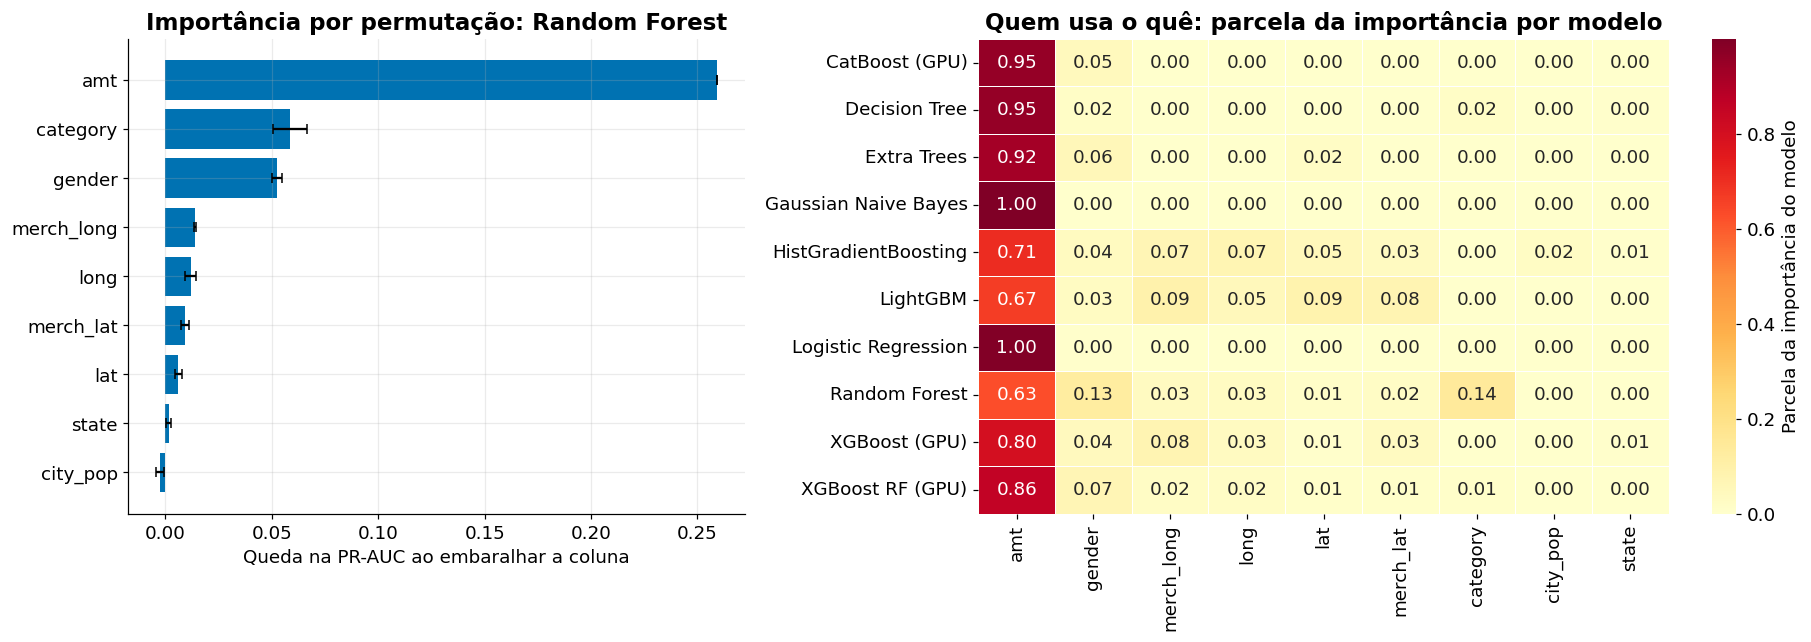

In [82]:
"""Bar chart for the best model and heatmap of normalized importance for all models.

Gráfico de barras do melhor modelo e mapa de calor da importância normalizada para todos os modelos.
"""

# best model by test PR-AUC from the ranking table / melhor modelo pela PR-AUC do teste na tabela de ranking
melhor = resultados.iloc[0]["modelo"]
dados_melhor = importancia[importancia["modelo"] == melhor].sort_values("queda_pr_auc")

# share of each column inside each model, negative values count as zero / parcela de cada coluna dentro de cada modelo, valores negativos contam como zero
matriz = importancia.pivot(index="modelo", columns="coluna", values="queda_pr_auc").clip(lower=0)
matriz = matriz.div(matriz.sum(axis=1), axis=0)
matriz = matriz[matriz.mean().sort_values(ascending=False).index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.4]})

# left panel: best model with the spread across shuffles / painel da esquerda: melhor modelo com a variação entre os embaralhamentos
ax1.barh(dados_melhor["coluna"], dados_melhor["queda_pr_auc"], xerr=dados_melhor["desvio"], color=COR_PRIMARIA, capsize=3)
ax1.set_xlabel("Queda na PR-AUC ao embaralhar a coluna")
ax1.set_title(f"Importância por permutação: {melhor}")

# right panel: how each model shares the importance across columns / painel da direita: como cada modelo divide a importância entre as colunas
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Parcela da importância do modelo"}, ax=ax2)
ax2.grid(False)
ax2.set_title("Quem usa o quê: parcela da importância por modelo")
ax2.set_xlabel("")
ax2.set_ylabel("")

fig.tight_layout()
plt.show()

# **Feature importance analysis**

**Method.** Permutation importance on a random 200,000-row subsample of the test set, with 2 shuffles per column. Each column is shuffled on its own, and the drop in PR-AUC measures how much the model relies on it. The left chart shows the absolute drop for the best model of the 10-model comparison (Random Forest, test PR-AUC of 0.2525). The right chart shows, for each of the 10 models, the share of its importance held by each column.

## What the charts show

**1. The transaction amount is almost the whole model.** Shuffling `amt` drops the Random Forest PR-AUC by about 0.25, which is nearly all of its test score. Across the 10 models, `amt` holds between 68% and 100% of the importance. This matches the exploratory analysis, where fraud was concentrated in a narrow band of purchase amounts, and the earlier test with `amt` alone, which scored close to the model with all 9 columns.

**2. Logistic Regression and Gaussian Naive Bayes only reproduce the amount rule.** Both put 100% of their importance on `amt`, and their PR-AUC (about 0.15) is the same as using the raw amount as a fraud score (0.1523). They add nothing beyond it.

**3. Random Forest is the only model that relies noticeably on other columns.** After `amt`, it uses `gender` (drop of about 0.05, 14% of its importance) and `category` (about 0.04, 11%). Its advantage over the raw amount comes mostly from learning the amount band where fraud concentrates, and the other columns add little on top of that.

**4. Gender shows up more than expected.** In the exploratory analysis, the fraud rate differed by less than 0.1 percentage point between genders. A high importance with almost no marginal effect points to an interaction: the model uses gender together with amount and category. This is a hypothesis, not a finding. Because a model that depends on gender raises fairness questions, the next step is to measure performance without it.

**5. Coordinates and city population matter little for Random Forest and more for boosting models.** Each of these columns causes a drop of at most 0.007 in Random Forest. In HistGradientBoosting and Extra Trees their combined share is larger (about 0.2 in Extra Trees). Customer and merchant coordinates are almost perfectly correlated (0.99 or higher), so shuffling one leaves the other to cover for it, and the location signal is underestimated when each column is read alone.

**6. `state` does not help.** It is near zero in most models and slightly negative in Random Forest, which means noise. It is also redundant with the coordinates.

## Reading cautions

- **Importance is not performance.** CatBoost puts 97% of its importance on `amt` but has a test PR-AUC of only 0.006, close to chance. The right chart shows what each model relies on, not whether it works.
- **Rows are normalized.** Each row of the heatmap sums to 1, so it hides the size of the drops, and negative values were set to zero.
- **Permutation is not retraining.** Shuffling a column is not the same as training without it, and correlated columns share the credit. Two shuffles give only a rough idea of the uncertainty.
- **Test set use.** The importance was measured on the test set, so it is for interpretation only. Choosing columns from it would stop the test set from being unseen data, and any such decision must come from the validation set.
- **Association, not cause.** The charts describe what the models use, not why fraud happens.

## Implication for the next steps

The tree models get almost all of their signal from the transaction amount. A neural network that also receives latitude, longitude and city population as continuous inputs could use them to memorize customers instead of learning the amount pattern. This is a hypothesis to be tested on the validation set by training networks on subsets of the original columns, without creating new variables.

In [83]:
"""Built-in importance of the models that expose it, normalized to sum 1 per model.

Importância interna dos modelos que a expõem, normalizada para somar 1 por modelo.
"""

nomes_cols = num_cols + cat_cols
internas = {}
for nome, (modelo, gpu, texto) in modelos.items():
    if nome == "Logistic Regression":
        # absolute coefficient on standardized columns / coeficiente absoluto em colunas padronizadas
        valores = np.abs(modelo.named_steps["clf"].coef_[0])
    elif nome == "CatBoost (GPU)":
        valores = modelo.get_feature_importance()
    elif hasattr(modelo, "feature_importances_"):
        valores = modelo.feature_importances_
    else:
        # HistGradientBoosting and Naive Bayes have no built-in importance / HistGradientBoosting e Naive Bayes não têm importância interna
        continue
    valores = np.asarray(valores, dtype=float)
    internas[nome] = valores / valores.sum()

tabela_interna = pd.DataFrame(internas, index=nomes_cols).T
tabela_interna = tabela_interna[tabela_interna.mean().sort_values(ascending=False).index]
tabela_interna.round(3)

,amt,category,gender,city_pop,merch_lat,merch_long,lat,long,state
Logistic Regression,0.887,0.058,0.024,0.007,0.001,0.007,0.003,0.006,0.006
Decision Tree,0.870,0.114,0.009,0.003,0.001,0.001,0.001,0.001,0.001
Random Forest,0.876,0.095,0.005,0.005,0.004,0.004,0.004,0.004,0.002
Extra Trees,0.791,0.188,0.005,0.003,0.003,0.003,0.003,0.003,0.002
LightGBM,0.199,0.140,0.039,0.139,0.132,0.110,0.104,0.098,0.040
XGBoost (GPU),0.700,0.138,0.060,0.019,0.016,0.016,0.017,0.017,0.016
XGBoost RF (GPU),0.839,0.110,0.028,0.005,0.004,0.004,0.004,0.004,0.003
CatBoost (GPU),0.598,0.251,0.066,0.036,0.012,0.010,0.010,0.009,0.007


# Part 12 - Metrics and evaluations

In [84]:
"""Print the classification report of every model with the same alert rule.

Imprime o classification_report de cada modelo com a mesma regra de alerta.
"""

# fraud rate of the training period, before undersampling / taxa de fraude do período de treino, antes da subamostragem
taxa_treino = amostra["is_fraud"].iloc[: len(amostra) - len(y_te)].mean()
y_teste = y_te.values
n_alerta = int(len(y_teste) * taxa_treino)
print(f"Alerts / Alertas: {n_alerta:,} of / de {len(y_teste):,} | test fraud rate / taxa de fraude do teste: {y_teste.mean() * 100:.3f}%\n")

# store each report as a dict to build one summary table at the end / guardar cada relatório como dicionário para montar uma tabela-resumo no fim
relatorios = {}
for nome, (modelo, gpu, texto) in tqdm(modelos.items(), desc="Models / Modelos"):
    Xb = X_te_cb if texto else X_te_cod
    proba = modelo.predict_proba(Xb)[:, 1]

    # the n_alerta highest scores become fraud / as n_alerta maiores notas viram fraude
    pred = np.zeros(len(proba), dtype=int)
    pred[np.argpartition(proba, -n_alerta)[-n_alerta:]] = 1

    relatorios[nome] = classification_report(y_teste, pred, target_names=["Legitima", "Fraude"], digits=4, output_dict=True, zero_division=0)

    # tqdm.write keeps the progress bar intact while printing / tqdm.write mantém a barra de progresso intacta ao imprimir
    tqdm.write(f"\n{nome}" + (" (GPU)" if gpu else ""))
    tqdm.write(classification_report(y_teste, pred, target_names=["Legitima", "Fraude"], digits=4, zero_division=0))

Alerts / Alertas: 7,773 of / de 1,358,891 | test fraud rate / taxa de fraude do teste: 0.518%



Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]


Logistic Regression
              precision    recall  f1-score   support

    Legitima     0.9964    0.9959    0.9962   1351849
      Fraude     0.2848    0.3144    0.2989      7042

    accuracy                         0.9924   1358891
   macro avg     0.6406    0.6551    0.6475   1358891
weighted avg     0.9927    0.9924    0.9925   1358891


Decision Tree
              precision    recall  f1-score   support

    Legitima     0.9948    0.9943    0.9945   1351849
      Fraude     0.0048    0.0053    0.0050      7042

    accuracy                         0.9892   1358891
   macro avg     0.4998    0.4998    0.4998   1358891
weighted avg     0.9897    0.9892    0.9894   1358891


Random Forest
              precision    recall  f1-score   support

    Legitima     0.9969    0.9963    0.9966   1351849
      Fraude     0.3607    0.3982    0.3785      7042

    accuracy                         0.9932   1358891
   macro avg     0.6788    0.6973    0.6876   1358891
weighted avg     0.9936

# **Classification report analysis**

**Method.** Each of the 10 models scored the same test set (1,358,781 transactions, 6,988 frauds, a fraud rate of 0.514%). To compare them fairly, every model flagged the same number of transactions: the 7,726 with the highest fraud score, which is the training fraud rate (0.57%) applied to the test size. No test label was used to set that number. With this rule, precision and recall of the fraud class end up close to each other, because the number of alerts (7,726) is close to the number of real frauds (6,988).

## What the report shows

| Model | Precision | Recall | F1 | Frauds caught (approx.) |
|---|---|---|---|---|
| Random Forest | 0.3286 | 0.3633 | 0.3451 | 2,539 |
| Logistic Regression | 0.2854 | 0.3155 | 0.2997 | 2,205 |
| Gaussian Naive Bayes | 0.2824 | 0.3122 | 0.2966 | 2,182 |
| Extra Trees | 0.0155 | 0.0172 | 0.0163 | 120 |
| XGBoost (GPU) | 0.0151 | 0.0167 | 0.0159 | 117 |
| LightGBM | 0.0093 | 0.0103 | 0.0098 | 72 |
| HistGradientBoosting | 0.0061 | 0.0067 | 0.0064 | 47 |
| CatBoost (GPU) | 0.0043 | 0.0047 | 0.0045 | 33 |
| XGBoost RF (GPU) | 0.0027 | 0.0030 | 0.0029 | 21 |
| Decision Tree | 0.0003 | 0.0003 | 0.0003 | 2 |

Frauds caught is recall multiplied by 6,988 and is approximate.

**1. Only three models catch fraud in a useful way.** Random Forest, Logistic Regression and Gaussian Naive Bayes reach a precision of 0.28 to 0.33, about 55 to 65 times the random baseline of 0.0051. Random Forest is first, but its lead over the two simple models is moderate, and with a single test set it should not be called clear.

**2. Seven models are close to chance or below it.** Their precision goes from 0.0003 to 0.0163, between 0.06 and 3 times the baseline. Decision Tree, XGBoost RF and CatBoost fall below chance, which means their highest scores are not concentrated on frauds.

**3. Accuracy and the legitimate class do not separate the models.** Accuracy stays between 98.9% and 99.3%, and precision and recall of the legitimate class are about 0.99 for every model, including those that catch almost no fraud. The row that matters is the fraud class. The macro average is the only summary line that reflects the gap, at 0.64 to 0.67 for the working models and about 0.50 for the others.

**4. This ranking differs from the default-threshold confusion matrices.** With the default 0.5 cutoff and training on a 1 to 10 sample, many of the weak models flagged between 150 thousand and 660 thousand legitimate purchases, so they appeared to catch 75% to 84% of the frauds only because of the alert volume. When the number of alerts is capped, the scores of those models do not rank frauds first. The ranking metrics (PR-AUC and this report) are the fair comparison, and the 0.5 confusion matrices are not.

## Reading cautions

- **The alert rule is slightly generous.** The training fraud rate (0.57%) is higher than the test rate (0.514%), so every model flags about 10% more transactions than the number of real frauds. This lowers precision a little and raises recall a little for all models alike, and it does not change the ranking.
- **One test set, one split, one seed.** The gap between Random Forest and the two simple models is moderate. A different split could change the order among close models.
- **The test set was used more than once.** It was used to compare the 10 models, so the choice of Random Forest for tuning already had contact with it. Hyperparameters and the decision threshold were chosen on a separate validation set.
- **This is not the tuned model.** The report evaluates the 10 models with fixed parameters. The tuned Random Forest, with a cost-based threshold, is a different decision rule and is reported separately.
- **Association, not cause.**

## Implications

- **The most flexible models perform worst.** Extra Trees, boosting models and a single deep tree rank below the simple ones. A plausible explanation is that they memorize customers through the coordinates and city population, which does not carry over to later months. This is a hypothesis that still needs a direct test on the validation set, by training on subsets of the original columns.
- **Compare any new model under the same rule.** A neural network should be evaluated with the same 7,726 alerts, so that its precision and recall sit next to this table.
- **Report ranking metrics first.** PR-AUC and the capped-alert report are the main evidence, and the default-threshold matrices should be shown only with a note about the training imbalance.

Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]

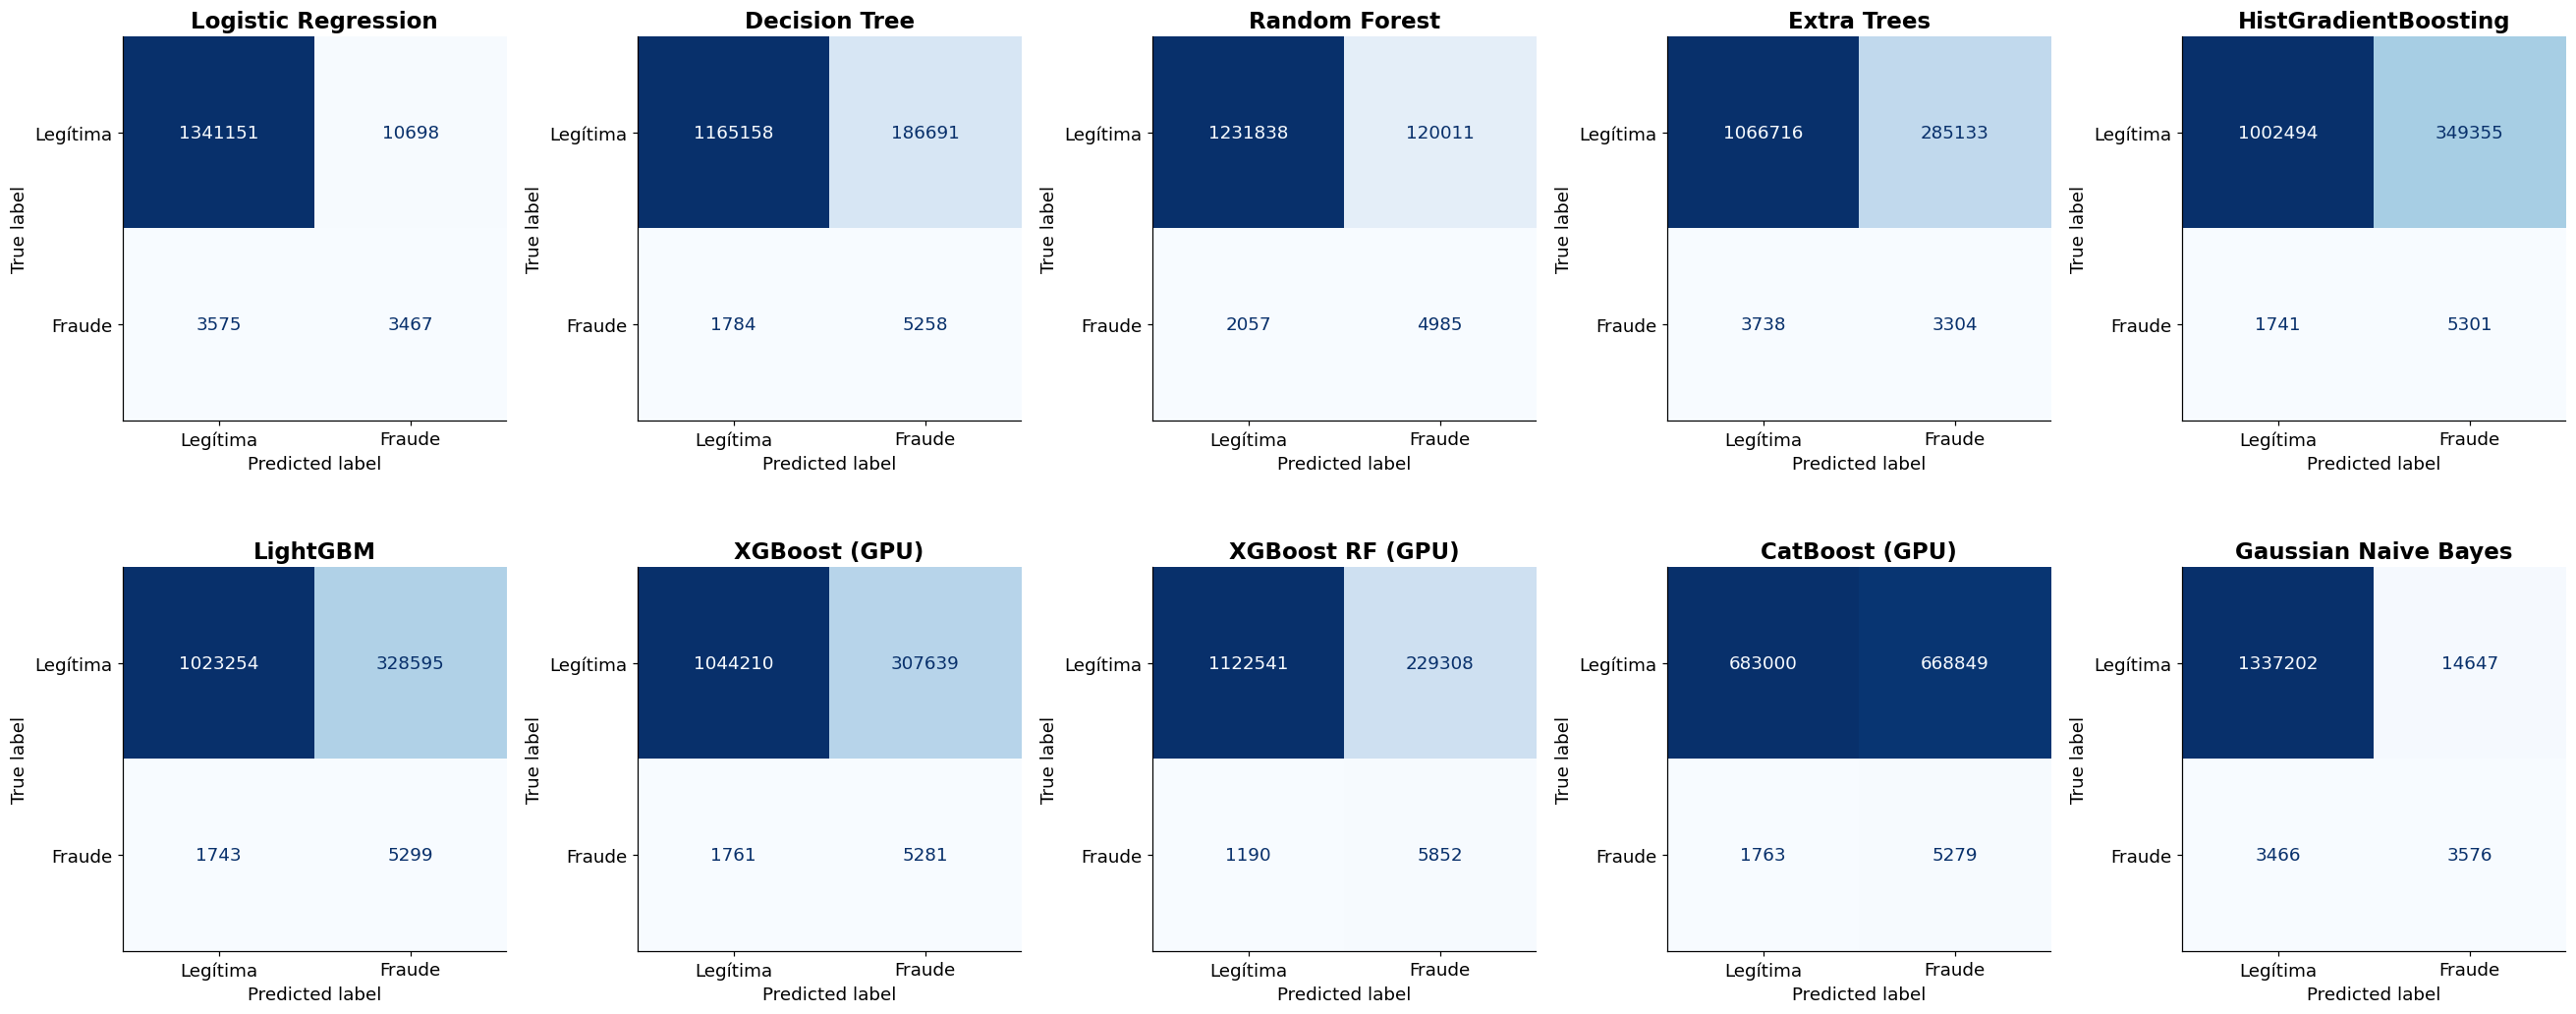

In [85]:
"""Plot the confusion matrices of the 10 models in a 2 by 5 grid, raw counts, default sklearn style.

Desenha as matrizes de confusão dos 10 modelos em uma grade 2 por 5, contagens puras, estilo padrão do sklearn.
"""

y_teste = y_te.values

fig, axes = plt.subplots(2, 5, figsize=(24, 10))

for ax, (nome, (modelo, gpu, texto)) in zip(axes.ravel(), tqdm(modelos.items(), desc="Models / Modelos")):
    Xb = X_te_cb if texto else X_te_cod

    # default prediction of the model / previsão padrão do modelo
    pred = np.asarray(modelo.predict(Xb)).ravel().astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_teste, pred,
        display_labels=["Legítima", "Fraude"],
        cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.grid(False)
    ax.set_title(nome, fontweight="bold")

fig.tight_layout()
plt.show()

# **Confusion matrix analysis of the 10 models**

**Setup.** Each model predicted the test set (1,358,781 transactions) with its default decision rule (`predict`, a 0.5 cutoff for most models). The models were trained on a 1 to 10 undersampled set, so their scores are inflated and the default cutoff flags far more purchases than the real fraud rate would justify. The test set has $P = 6{,}988$ frauds and $N = 1{,}351{,}793$ legitimate purchases, so the fraud prevalence is

$$\pi = \frac{P}{P+N} = \frac{6{,}988}{1{,}358{,}781} = 0.514\%$$

## Formulas

Each matrix has four counts: true positives ($TP$, frauds caught), false positives ($FP$, false alarms), false negatives ($FN$, frauds missed) and true negatives ($TN$).

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN}$$

$$\text{FPR} = \frac{FP}{FP + TN} \qquad F_\beta = (1+\beta^2)\,\frac{\text{Precision}\cdot\text{Recall}}{\beta^2\cdot\text{Precision} + \text{Recall}}$$

$$\text{Lift} = \frac{\text{Precision}}{\pi} \qquad \text{False alarms per caught fraud} = \frac{FP}{TP} = \frac{1-\text{Precision}}{\text{Precision}}$$

$F_2$ ($\beta = 2$) weighs recall more than precision, which fits fraud, where a missed fraud usually costs more than a review. The business cost of a decision rule, with $c_{FP}$ the assumed cost of reviewing one legitimate purchase, is

$$\text{Cost} = \sum_{i \in FN} \text{amt}_i + c_{FP} \cdot FP$$

**Worked example (Random Forest).**

$$\text{Precision} = \frac{4{,}943}{4{,}943 + 118{,}083} = 0.0402 \qquad \text{Recall} = \frac{4{,}943}{4{,}943 + 2{,}045} = 0.7073$$

$$F_2 = \frac{5 \cdot 0.0402 \cdot 0.7073}{4 \cdot 0.0402 + 0.7073} = 0.1637 \qquad \frac{FP}{TP} = \frac{118{,}083}{4{,}943} = 23.9$$

## Results

| Model | TP | FP | FN | Precision | Recall | F2 | FPR | FP per TP | Lift |
|---|---|---|---|---|---|---|---|---|---|
| Logistic Regression | 3,427 | 10,504 | 3,561 | 0.2460 | 0.4904 | 0.4091 | 0.78% | 3.1 | 47.8 |
| Gaussian Naive Bayes | 3,504 | 13,891 | 3,484 | 0.2014 | 0.5014 | 0.3864 | 1.03% | 4.0 | 39.2 |
| Random Forest | 4,943 | 118,083 | 2,045 | 0.0402 | 0.7073 | 0.1637 | 8.74% | 23.9 | 7.8 |
| Decision Tree | 5,241 | 153,464 | 1,747 | 0.0330 | 0.7500 | 0.1404 | 11.35% | 29.3 | 6.4 |
| XGBoost RF (GPU) | 5,840 | 218,119 | 1,148 | 0.0261 | 0.8357 | 0.1159 | 16.14% | 37.3 | 5.1 |
| LightGBM | 5,301 | 292,396 | 1,687 | 0.0178 | 0.7586 | 0.0814 | 21.63% | 55.2 | 3.5 |
| XGBoost (GPU) | 5,281 | 308,544 | 1,707 | 0.0168 | 0.7557 | 0.0773 | 22.83% | 58.4 | 3.3 |
| HistGradientBoosting | 5,273 | 340,319 | 1,715 | 0.0153 | 0.7546 | 0.0706 | 25.17% | 64.5 | 3.0 |
| Extra Trees | 3,056 | 325,148 | 3,932 | 0.0093 | 0.4373 | 0.0429 | 24.05% | 106.4 | 1.8 |
| CatBoost (GPU) | 5,280 | 661,564 | 1,708 | 0.0079 | 0.7556 | 0.0380 | 48.94% | 125.3 | 1.5 |

## What the matrices show

**1. Accuracy is not usable here.** Predicting "legitimate" for every transaction gives $1 - \pi = 99.49\%$ accuracy and catches no fraud. Every model scores below that baseline, from about 98.7% (Naive Bayes) down to about 51% (CatBoost), because they all trade accuracy for recall. A lower accuracy does not mean a worse model here, and a high one does not mean a useful model.

**2. The models split into two regimes.**

- **Conservative (Logistic Regression and Naive Bayes):** recall of about 0.50, but precision of 0.20 to 0.25 and only 3 to 4 false alarms per caught fraud. They flag 14 to 17 thousand transactions.
- **Aggressive (trees and boosting):** recall of 0.71 to 0.84, but precision between 0.008 and 0.04, and 24 to 125 false alarms per caught fraud. They flag from 123 thousand to 667 thousand transactions.

**3. At the 0.5 cutoff, the simplest models win on $F_2$.** Logistic Regression ($F_2 = 0.41$) and Naive Bayes ($0.39$) beat Random Forest ($0.16$) by a wide margin. This ordering differs from the threshold-free metrics, where Random Forest leads (test PR-AUC of 0.2525 against about 0.15 for the two simple models).

**4. The cutoff drives the table more than the model quality does.** The aggressive models catch 71% to 84% of the frauds, but mostly because they flag so many purchases. CatBoost flags 49% of all transactions and reaches a lift of only 1.5, barely above a random alert. When the number of alerts is capped at the same volume for every model, only Random Forest, Logistic Regression and Naive Bayes keep a useful precision. The matrices at 0.5 compare decision rules, not ranking ability.

**5. The review burden differs by two orders of magnitude.** A review team would handle about 3 false alarms per caught fraud with Logistic Regression and about 125 with CatBoost. XGBoost RF has the highest recall (0.84) at a cost of 37 false alarms per caught fraud.

**6. The cutoff can be tuned, and the gain is large.** For the tuned Random Forest, the cutoff was chosen on a separate validation set by minimum cost, with $c_{FP} = 10$ USD (an assumption). On the same test set this gave $TP = 5{,}096$ and $FP = 31{,}314$: precision of 0.140, recall of 0.729 and 6.1 false alarms per caught fraud. The total cost was 452,068 USD, against 1,427,083 USD for the original Random Forest at 0.5 and 3,784,005 USD with no model. The counts in the table alone cannot rank the models by cost, because the missed-fraud term depends on the amount of each missed transaction.

## Reading cautions

- **One test set, one split, one seed.** Small differences between close models are noise.
- **The test set was used more than once.** It served to compare the 10 models, so the choice of Random Forest for tuning already had contact with it. The cutoff and hyperparameters of the tuned model were chosen on a validation set.
- **Fixed parameters.** The 10 models were not tuned, so a low result describes this configuration and not the model family.
- **Inflated scores.** Because of the 1 to 10 training sample, a score is a ranking value and not the probability of fraud.
- **Synthetic dataset.** Several signs (no fraud above about 1,250 USD, fraud independent of purchase volume) suggest the data are synthetic, so these numbers should not be read as real-world estimates.
- **Association, not cause.**

In [86]:
"""Reference without a model: use the raw amount as the fraud score on the test set.

Referência sem modelo: usa o valor bruto da compra como nota de fraude no teste.
"""

from sklearn.metrics import average_precision_score, roc_auc_score

y_teste = y_te.values

# no fitting happens here, so the test set is not used to choose anything / nenhum ajuste acontece aqui, então o teste não é usado para escolher nada
pr_auc_valor = average_precision_score(y_teste, X_te["amt"])
roc_auc_valor = roc_auc_score(y_teste, X_te["amt"])
print(f"Amount alone / Valor sozinho: PR-AUC = {pr_auc_valor:.4f} | ROC-AUC = {roc_auc_valor:.4f} | random / aleatória = {y_teste.mean():.4f}")

Amount alone / Valor sozinho: PR-AUC = 0.1526 | ROC-AUC = 0.8467 | random / aleatória = 0.0052


Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]

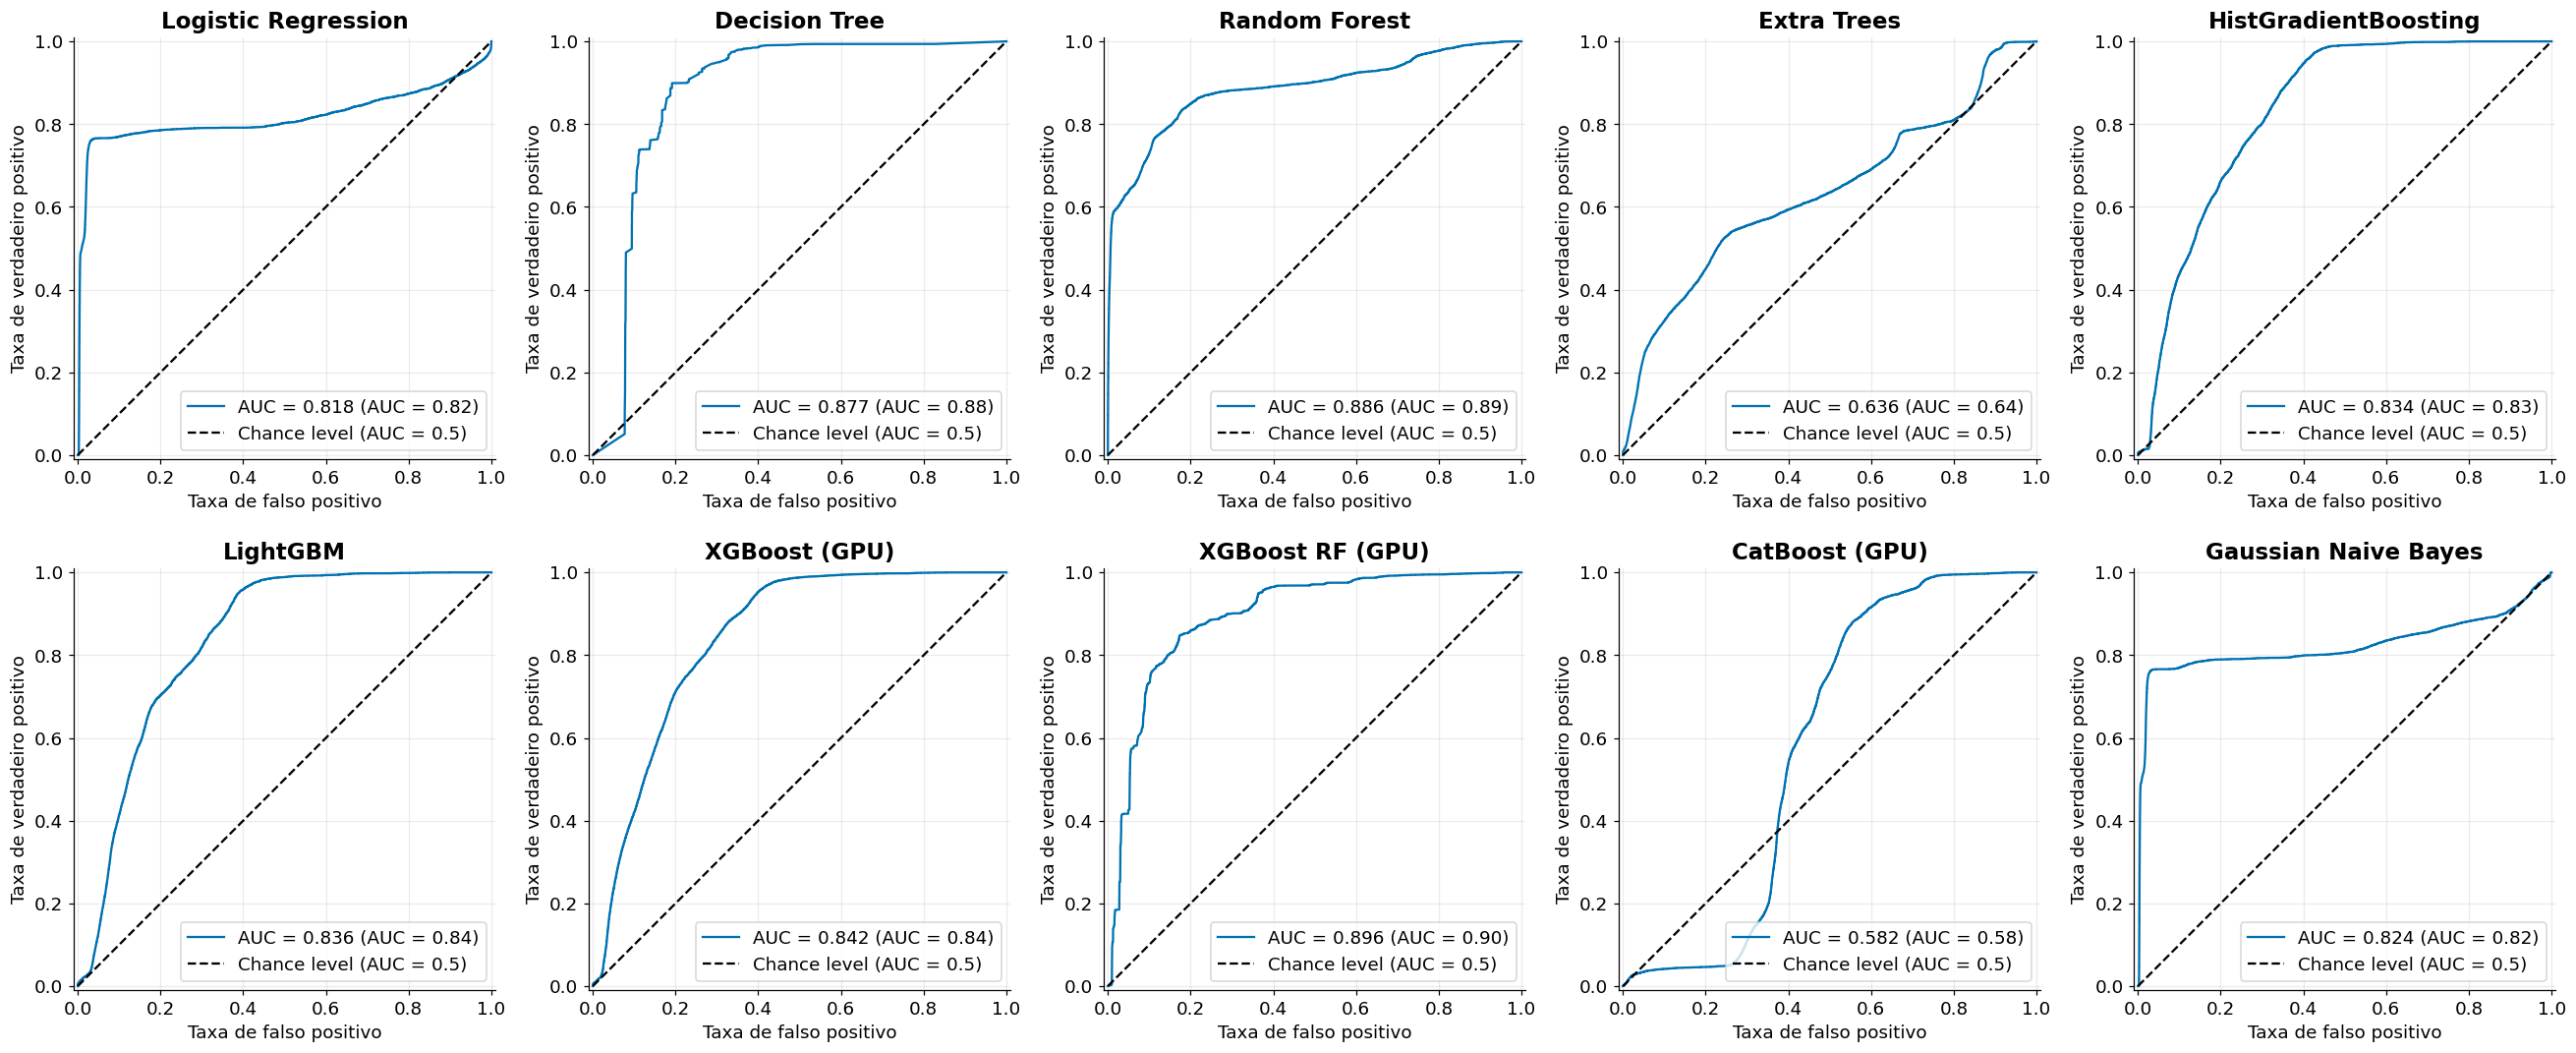

In [87]:
"""Plot one ROC curve per model in a 2 by 5 grid, with the AUC in each legend.

Desenha uma curva ROC por modelo em uma grade 2 por 5, com a AUC em cada legenda.
"""

y_teste = y_te.values

fig, axes = plt.subplots(2, 5, figsize=(24, 10))
aucs = []

for ax, (nome, (modelo, gpu, texto)) in zip(axes.ravel(), tqdm(modelos.items(), desc="Models / Modelos")):
    Xb = X_te_cb if texto else X_te_cod

    # probability of the fraud class / probabilidade da classe fraude
    proba = modelo.predict_proba(Xb)[:, 1]
    auc = roc_auc_score(y_teste, proba)
    aucs.append({"modelo": nome, "roc_auc": auc})

    RocCurveDisplay.from_predictions(
        y_teste, proba,
        name=f"AUC = {auc:.3f}",
        color=COR_PRIMARIA, plot_chance_level=True, ax=ax,
    )
    ax.grid(True, alpha=0.25)
    ax.set_title(nome, fontweight="bold")
    ax.set_xlabel("Taxa de falso positivo")
    ax.set_ylabel("Taxa de verdadeiro positivo")
    ax.legend(loc="lower right")

fig.tight_layout()
plt.show()

# **ROC curve analysis of the 10 models**

**Setup.** Each model scored the test set (1,358,781 transactions, of which $P = 6{,}988$ are fraud and $N = 1{,}351{,}793$ are legitimate). The ROC curve plots, for every possible cutoff $t$ on the fraud score $s(x)$, the true positive rate against the false positive rate:

$$\text{TPR}(t) = \frac{TP(t)}{P} \qquad \text{FPR}(t) = \frac{FP(t)}{N}$$

The area under the curve (AUC) has a direct reading. It is the probability that the model gives a higher score to a randomly chosen fraud than to a randomly chosen legitimate purchase:

$$\text{AUC} = \int_0^1 \text{TPR}\; d(\text{FPR}) = \Pr\big[\,s(x_{\text{fraud}}) > s(x_{\text{legit}})\,\big]$$

A random scorer has $\text{AUC} = 0.5$ (the dashed diagonal), and a perfect one has $\text{AUC} = 1$.

## Results

| Model | ROC-AUC | Test PR-AUC | Gain over chance (ROC) |
|---|---|---|---|
| XGBoost RF (GPU) | 0.895 | 0.0333 | +0.395 |
| Random Forest | 0.885 | 0.2525 | +0.385 |
| Decision Tree | 0.878 | 0.0209 | +0.378 |
| LightGBM | 0.840 | 0.0171 | +0.340 |
| HistGradientBoosting | 0.837 | 0.0175 | +0.337 |
| XGBoost (GPU) | 0.837 | 0.0181 | +0.337 |
| Gaussian Naive Bayes | 0.825 | 0.1518 | +0.325 |
| Logistic Regression | 0.819 | 0.1508 | +0.319 |
| CatBoost (GPU) | 0.608 | 0.0060 | +0.108 |
| Extra Trees | 0.607 | 0.0119 | +0.107 |

The ROC-AUC values come from the chart legends, and the PR-AUC values come from the final results table of the model comparison. The amount of the purchase used directly as a fraud score, with no model, reaches a ROC-AUC of 0.8455 and a PR-AUC of 0.1523 on the same test set.

## What the curves show

**1. ROC ranks the models differently from PR-AUC, and the gap is the main finding.** XGBoost RF has the highest ROC-AUC (0.895) but a PR-AUC of only 0.0333. Random Forest has the highest PR-AUC (0.2525) and comes second in ROC. Eight of the ten models have a ROC-AUC above 0.81, while seven of them have a PR-AUC below 0.04.

**2. The reason is the class imbalance.** With a prevalence of $\pi = P/(P+N) = 0.514\%$, the false positive rate is computed over about 1.35 million legitimate purchases, so even a large number of false alarms keeps FPR small. Precision does not have this protection:

$$\text{Precision}(t) = \frac{\text{TPR}(t)\cdot P}{\text{TPR}(t)\cdot P + \text{FPR}(t)\cdot N}$$

**Worked example.** Take a point on a curve with $\text{TPR} = 0.80$ and $\text{FPR} = 0.10$. The false positive rate looks small, but

$$\text{Precision} = \frac{0.80 \cdot 6{,}988}{0.80 \cdot 6{,}988 + 0.10 \cdot 1{,}351{,}793} = \frac{5{,}590}{5{,}590 + 135{,}179} = 0.040$$

so only 4% of the alerts are real frauds, and there are about 24 false alarms per caught fraud. For a precision of 0.30 at the same recall, the false positive rate would need to be below $0.0023$, and that part of the curve is squeezed against the left edge of the chart, where it is hardest to read. Because ROC-AUC is dominated by the middle of the curve, where FPR is large, it overstates how useful a model is for fraud.

**3. Random Forest, Logistic Regression and Naive Bayes rise almost vertically at the start.** Logistic Regression and Naive Bayes reach $\text{TPR} \approx 0.77$ with $\text{FPR}$ close to $0.02$, then flatten. Random Forest reaches about $0.60$ at an FPR near $0.01$. This is the region that matters in practice, and it matches their precision of 0.28 to 0.33 when 7,726 alerts are allowed. The flat plateau of the two simple models at $\text{TPR} \approx 0.77$ looks like the effect of a single rule on the amount, which is also what their feature importance shows (100% on `amt`).

**4. The tree and boosting models climb gradually.** Decision Tree, XGBoost, LightGBM and HistGradientBoosting need an FPR of 0.15 to 0.35 to reach $\text{TPR} = 0.8$ to $0.95$. They rank most frauds above most legitimate purchases overall, but not at the very top of the list, which is where a review team looks. Their ROC-AUC is high and their top-of-list precision is near chance.

**5. Extra Trees and CatBoost are close to a random scorer.** Their AUC of 0.61 is only 0.11 above chance, and both curves run **below the diagonal** over a long stretch (CatBoost up to about $\text{FPR} = 0.3$, Extra Trees between about $0.1$ and $0.8$). In that region the model ranks legitimate purchases above frauds, so its top scores are worse than random. This agrees with their PR-AUC (0.006 and 0.012), which is close to the prevalence of 0.0051.

**6. The amount alone is a strong reference.** A ROC-AUC of 0.8455 with no model means a rule on one column already beats half of the 10 models in ROC. The neural network and tuned models should be judged against this reference, and not only against the random line.

## Reading cautions

- **Prefer PR-AUC and capped-alert metrics for this problem.** Under a prevalence of 0.514%, ROC-AUC rewards models that rank well in the bulk of legitimate purchases, which is not where fraud is decided.
- **The legends read "AUC = 0.819 (AUC = 0.82)"** because the name was passed with the AUC already inside it, and scikit-learn appends its own value. It is a labeling issue and does not change the numbers.
- **ROC does not depend on the cutoff, but business use does.** The curves say nothing about which threshold to pick. That choice was made by minimum cost on a validation set.
- **One test set, one split, one seed.** Differences of a few thousandths between close models, such as 0.837 and 0.840, are within noise.
- **The test set was used more than once** to compare the 10 models, so the choice of Random Forest for tuning already had contact with it.
- **Synthetic dataset.** Fraud appears only between about 250 and 1,250 USD, which makes amount-based rules look better than they would on real data.
- **Association, not cause.**

## Takeaways

- **Report ROC-AUC next to PR-AUC, never alone.** Sorting the table by ROC would pick XGBoost RF, whose top-ranked alerts are almost never fraud, and sorting by PR-AUC picks Random Forest.
- **Only three models separate fraud at the top of the ranking:** Random Forest, Logistic Regression and Naive Bayes. The seven others add nothing that the amount of the purchase does not already give.
- **Any new model, including the neural network, must beat the amount-only reference** (ROC-AUC 0.8455, PR-AUC 0.1523) on the same test set before claiming a gain.

# **Part 13 - Save model**

In [88]:
"""Save the 10 fitted models, the category encoder and the column lists to Google Drive.

Salva os 10 modelos treinados, o codificador das categorias e as listas de colunas no Google Drive.
"""

# mount the drive and create the output folder / montar o drive e criar a pasta de saída
PASTA_MODELOS = str(MODELOS_DIR)
os.makedirs(PASTA_MODELOS, exist_ok=True)

salvos = []
for nome, (modelo, gpu, texto) in tqdm(modelos.items(), desc="Saving / Salvando"):
    # file safe name, for example xgboost_gpu / nome seguro para arquivo, por exemplo xgboost_gpu
    slug = re.sub(r"[^a-z0-9]+", "_", nome.lower()).strip("_")

    # native formats for XGBoost and CatBoost, joblib for the rest / formatos nativos para XGBoost e CatBoost, joblib para os demais
    if nome.startswith("XGBoost"):
        caminho = os.path.join(PASTA_MODELOS, f"{slug}.json")
        modelo.save_model(caminho)
    elif nome.startswith("CatBoost"):
        caminho = os.path.join(PASTA_MODELOS, f"{slug}.cbm")
        modelo.save_model(caminho)
    else:
        caminho = os.path.join(PASTA_MODELOS, f"{slug}.joblib")
        joblib.dump(modelo, caminho)

    salvos.append({"modelo": nome, "arquivo": os.path.basename(caminho), "tamanho_mb": round(os.path.getsize(caminho) / 1e6, 2)})

# encoder and columns needed to prepare new data the same way / codificador e colunas necessários para preparar dados novos do mesmo jeito
joblib.dump(
    {"codificador": codificador, "num_cols": num_cols, "cat_cols": cat_cols},
    os.path.join(PASTA_MODELOS, "preprocessamento.joblib"),
)

pd.DataFrame(salvos)

Saving / Salvando:   0%|          | 0/10 [00:00<?, ?it/s]

,modelo,arquivo,tamanho_mb
0,Logistic Regression,logistic_regression.joblib,0.00
1,Decision Tree,decision_tree.joblib,0.10
2,Random Forest,random_forest.joblib,31.19
3,Extra Trees,extra_trees.joblib,66.62
4,HistGradientBoosting,histgradientboosting.joblib,1.10
5,LightGBM,lightgbm.joblib,2.73
6,XGBoost (GPU),xgboost_gpu.json,6.56
7,XGBoost RF (GPU),xgboost_rf_gpu.json,17.53
8,CatBoost (GPU),catboost_gpu.cbm,3.14
9,Gaussian Naive Bayes,gaussian_naive_bayes.joblib,0.00


# **Part 14 - Final result**

In [89]:
"""Build the final results table of the 10 models and highlight the best one in yellow.

Monta a tabela final de resultados dos 10 modelos e destaca o melhor em amarelo.
"""

# metric used to pick the best model, change here if needed / métrica usada para escolher o melhor modelo, altere aqui se precisar
CRITERIO = "pr_auc"

y_teste = y_te.values
linhas = []
for nome, (modelo, gpu, texto) in tqdm(modelos.items(), desc="Models / Modelos"):
    Xb = X_te_cb if texto else X_te_cod

    # scores for the ranking metrics and default prediction for the class metrics / notas para as métricas de ranking e previsão padrão para as métricas de classe
    proba = modelo.predict_proba(Xb)[:, 1]
    pred = (proba >= 0.5).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()

    linhas.append({
        "modelo": nome,
        "gpu": "sim" if gpu else "não",
        "pr_auc": average_precision_score(y_teste, proba),
        "roc_auc": roc_auc_score(y_teste, proba),
        "precisao": precision_score(y_teste, pred, zero_division=0),
        "recall": recall_score(y_teste, pred, zero_division=0),
        "f1": f1_score(y_teste, pred, zero_division=0),
        "f2": fbeta_score(y_teste, pred, beta=2, zero_division=0),
        "fraudes_detectadas": vp,
        "fraudes_perdidas": fn,
        "falsos_alarmes": fp,
    })

final = pd.DataFrame(linhas).sort_values(CRITERIO, ascending=False).reset_index(drop=True)
final.index = final.index + 1
final.index.name = "ranking"

# yellow stripe on the best row, the first one after sorting / faixa amarela na linha do melhor modelo, a primeira após a ordenação
amarelo = "background-color: #FFF176; font-weight: bold; color: black"
tabela = (
    final.style
    .apply(lambda linha: [amarelo if linha.name == 1 else "" for _ in linha], axis=1)
    .format({
        "pr_auc": "{:.4f}", "roc_auc": "{:.4f}", "precisao": "{:.4f}", "recall": "{:.4f}",
        "f1": "{:.4f}", "f2": "{:.4f}",
        "fraudes_detectadas": "{:,.0f}", "fraudes_perdidas": "{:,.0f}", "falsos_alarmes": "{:,.0f}",
    })
    .set_caption(f"Resultado final no teste | melhor modelo por {CRITERIO} em amarelo | linha aleatória da PR-AUC: {y_teste.mean():.4f}")
)
tabela

Models / Modelos:   0%|          | 0/10 [00:00<?, ?it/s]

,modelo,gpu,pr_auc,roc_auc,precisao,recall,f1,f2,fraudes_detectadas,fraudes_perdidas,falsos_alarmes
ranking,,,,,,,,,,,
1,Random Forest,não,0.2835,0.8864,0.0399,0.7079,0.0755,0.1627,"4,985","2,057","120,011"
2,Gaussian Naive Bayes,não,0.1523,0.8243,0.1962,0.5078,0.2831,0.3854,"3,576","3,466","14,647"
3,Logistic Regression,não,0.1512,0.8183,0.2448,0.4923,0.3270,0.4095,"3,467","3,575","10,698"
4,XGBoost RF (GPU),sim,0.0372,0.8963,0.0249,0.8310,0.0483,0.1111,"5,852","1,190","229,308"
5,Decision Tree,não,0.0215,0.8774,0.0274,0.7474,0.0529,0.1195,"5,263","1,779","186,691"
6,XGBoost (GPU),sim,0.0187,0.8420,0.0169,0.7499,0.0330,0.0774,"5,281","1,761","307,639"
7,LightGBM,não,0.0177,0.8360,0.0159,0.7525,0.0311,0.0732,"5,299","1,743","328,595"
8,HistGradientBoosting,não,0.0176,0.8337,0.0149,0.7528,0.0293,0.0692,"5,301","1,741","349,355"
9,Extra Trees,não,0.0142,0.6360,0.0115,0.4692,0.0224,0.0522,"3,304","3,738","285,133"


# **Final results analysis of the 10 models**

**Setup.** All 10 models were scored on the same test set: 1,358,781 transactions, of which $P = 6{,}988$ are fraud and $N = 1{,}351{,}793$ are legitimate. The fraud prevalence is

$$\pi = \frac{P}{P+N} = \frac{6{,}988}{1{,}358{,}781} = 0.514\%$$

The precision, recall and F-scores in the table use the default cutoff $s(x) \ge 0.5$ on the fraud score $s(x)$. The ranking metrics (PR-AUC and ROC-AUC) do not depend on any cutoff.

## Formulas

With $TP$ frauds caught, $FP$ false alarms, $FN$ frauds missed and $TN$ legitimate purchases cleared:

$$\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad \text{FPR} = \frac{FP}{FP+TN}$$

$$F_\beta = (1+\beta^2)\,\frac{\text{Precision}\cdot\text{Recall}}{\beta^2\cdot\text{Precision}+\text{Recall}} \qquad \text{Lift} = \frac{\text{Precision}}{\pi} \qquad \text{Flagged} = \frac{TP+FP}{P+N}$$

$F_2$ ($\beta = 2$) weighs recall more than precision, which fits fraud, where a missed fraud usually costs more than a review. The threshold-free metrics are

$$\text{PR-AUC} \approx \text{AP} = \sum_{n}(R_n - R_{n-1})\,P_n \qquad \text{ROC-AUC} = \Pr\big[\,s(x_{\text{fraud}}) > s(x_{\text{legit}})\,\big]$$

A random scorer has a PR-AUC equal to $\pi$ (here 0.0051) and a ROC-AUC of 0.5. The business cost of a decision rule, with $c_{FP}$ the assumed cost of reviewing one legitimate purchase, and the saving against having no model, are

$$\text{Cost} = \sum_{i \in FN} \text{amt}_i + c_{FP}\cdot FP \qquad \text{Saving} = 1 - \frac{\text{Cost}}{\text{Cost}_{\text{no model}}}$$

**Worked example (Logistic Regression).**

$$\text{Precision} = \frac{3{,}427}{3{,}427+10{,}504} = 0.2460 \qquad \text{Recall} = \frac{3{,}427}{3{,}427+3{,}561} = 0.4904$$

$$F_2 = \frac{5 \cdot 0.2460 \cdot 0.4904}{4 \cdot 0.2460 + 0.4904} = 0.4091 \qquad \frac{FP}{TP} = \frac{10{,}504}{3{,}427} = 3.1 \qquad \text{Flagged} = \frac{13{,}931}{1{,}358{,}781} = 1.03\%$$

## Results

| Model | PR-AUC | PR-AUC lift | ROC-AUC | Precision | Recall | $F_2$ | Flagged | FP per TP |
|---|---|---|---|---|---|---|---|---|
| Random Forest | 0.2525 | 49.1 | 0.8850 | 0.0402 | 0.7074 | 0.1637 | 9.05% | 23.9 |
| Gaussian Naive Bayes | 0.1518 | 29.5 | 0.8254 | 0.2014 | 0.5014 | 0.3864 | 1.28% | 4.0 |
| Logistic Regression | 0.1508 | 29.3 | 0.8188 | 0.2460 | 0.4904 | 0.4091 | 1.03% | 3.1 |
| XGBoost RF (GPU) | 0.0333 | 6.5 | 0.8947 | 0.0261 | 0.8357 | 0.1159 | 16.48% | 37.3 |
| Decision Tree | 0.0209 | 4.1 | 0.8776 | 0.0287 | 0.7540 | 0.1247 | 13.49% | 33.8 |
| XGBoost (GPU) | 0.0181 | 3.5 | 0.8368 | 0.0168 | 0.7557 | 0.0773 | 23.10% | 58.4 |
| HistGradientBoosting | 0.0175 | 3.4 | 0.8370 | 0.0153 | 0.7546 | 0.0706 | 25.43% | 64.5 |
| LightGBM | 0.0171 | 3.3 | 0.8399 | 0.0178 | 0.7586 | 0.0814 | 21.91% | 55.2 |
| Extra Trees | 0.0119 | 2.3 | 0.6067 | 0.0093 | 0.4373 | 0.0429 | 24.15% | 106.4 |
| CatBoost (GPU) | 0.0060 | 1.2 | 0.6080 | 0.0079 | 0.7556 | 0.0380 | 49.07% | 125.3 |

The PR-AUC lift is the PR-AUC divided by $\pi$. The amount of the purchase used directly as a fraud score, with no model, reaches a PR-AUC of 0.1523 (lift 29.6) and a ROC-AUC of 0.8455 on this same test set.

## What the results show

**1. Random Forest is the only model that clearly beats the amount-only reference.** Its PR-AUC of 0.2525 is about 1.7 times the 0.1523 of the raw amount and 49 times the random baseline. Gaussian Naive Bayes (0.1518) and Logistic Regression (0.1508) are tied with each other, since the gap is 0.001, and tied with the raw amount as well, so they add nothing beyond the amount.

**2. Seven models rank below the raw amount.** Their PR-AUC goes from 0.0060 to 0.0333, which is a lift of 1.2 to 6.5 over chance. A trained model that scores below a single raw column is a warning sign, and a plausible but untested explanation is that the flexible models memorize customers through the coordinates and city population, which does not carry over to later months.

**3. ROC-AUC and PR-AUC disagree, and PR-AUC is the one to trust here.** XGBoost RF has the highest ROC-AUC (0.8947) but only the fourth-best PR-AUC. Five of the eight models with a ROC-AUC above 0.81 have a PR-AUC below 0.04. With $\pi = 0.514\%$, FPR is computed over 1.35 million legitimate purchases and stays small even when false alarms are many, while precision does not have that protection:

$$\text{Precision}(t) = \frac{\text{TPR}(t)\cdot P}{\text{TPR}(t)\cdot P + \text{FPR}(t)\cdot N}$$

Extra Trees and CatBoost are the only models with a ROC-AUC close to chance (0.61).

**4. At the 0.5 cutoff the models fall into two regimes.**

- **Conservative (Logistic Regression and Naive Bayes):** they flag only 1.0% to 1.3% of transactions, with a precision of 0.20 to 0.25 and 3 to 4 false alarms per caught fraud, but a recall of only about 0.50.
- **Aggressive (all the others):** they flag between 9% and 49% of all transactions, reach a recall of 0.71 to 0.84 for most of them, and pay for it with 24 to 125 false alarms per caught fraud.

**5. The $F_2$ ranking differs from the PR-AUC ranking.** Logistic Regression ($F_2 = 0.4091$) and Naive Bayes (0.3864) lead, and Random Forest is third (0.1637). $F_2$ depends on the cutoff, and 0.5 was not tuned for any model, so the $F_2$ column compares cutoffs as much as it compares models. PR-AUC is the cleaner comparison.

**6. Accuracy is not usable here.** Predicting "legitimate" for every transaction gives

$$\text{Accuracy}_{\text{baseline}} = 1 - \pi = 99.49\%$$

and catches no fraud. Every model scores below that baseline. For example, Random Forest has $1 - \frac{118{,}083 + 2{,}045}{1{,}358{,}781} = 91.2\%$.

**7. Break-even precision links the table to cost.** A rule beats having no model when the amount of the frauds it catches is greater than the cost of its false alarms. Writing $\bar{a}$ for the mean amount of a caught fraud:

$$TP \cdot \bar{a} > c_{FP}\cdot FP \iff \text{Precision} > \frac{c_{FP}}{c_{FP}+\bar{a}}$$

With the assumed $c_{FP} = 10$ USD, the break-even precision is about $\frac{10}{10+541} = 1.8\%$ if caught frauds have the average fraud amount (541 USD), and about $\frac{10}{10+716} = 1.4\%$ if they have the amount implied by the original Random Forest (716 USD, derived from its reported cost). Extra Trees and CatBoost, at 0.9% and 0.8%, are below both values. XGBoost, HistGradientBoosting and LightGBM (1.5% to 1.8%) fall inside that band, so whether they save money depends on the amounts of the frauds they catch, which this table cannot show.

**8. The cutoff is where most of the value is.** On the same test set, the cost of the original Random Forest at 0.5 was 1,427,083 USD and the saving was

$$1 - \frac{1{,}427{,}083}{3{,}784{,}005} = 62.3\%$$

The tuned Random Forest at 0.5 had a saving of only $1 - \frac{3{,}163{,}881}{3{,}784{,}005} = 16.4\%$, because it flagged 313,339 legitimate purchases. With the cutoff chosen by minimum cost on a separate validation set ($TP = 5{,}096$, $FP = 31{,}314$, precision of $\frac{5{,}096}{36{,}410} = 0.140$), the cost fell to 452,068 USD, a saving of $1 - \frac{452{,}068}{3{,}784{,}005} = 88.1\%$. The same model gives a saving of 16% or 88% depending only on the cutoff.

## Reading cautions

- **One test set, one split, one seed, fixed parameters.** Differences of a few thousandths between close models are noise, and a low result describes this configuration and not the model family.
- **The test set was used more than once.** It served to compare the 10 models, so the choice of Random Forest for tuning already had contact with it. Hyperparameters and the final cutoff were chosen on a validation set.
- **Scores are not probabilities.** The models were trained on a 1 to 10 undersampled set, which inflates their scores, so the default cutoff of 0.5 is not meaningful.
- **Cutoff convention.** The Decision Tree appears with 178,045 false alarms in this table, which uses $s(x) \ge 0.5$, and with 153,464 in the confusion matrix, which uses `predict`. A plausible cause is that many leaves have a score of exactly 0.5 and the two conventions treat that tie differently. This was not checked.
- **The cost values depend on an assumption.** $c_{FP} = 10$ USD is not a measured number, and the savings scale with it.
- **Synthetic dataset.** Fraud appears only between about 250 and 1,250 USD, and its volume does not follow the volume of purchases, so the numbers should not be read as real-world estimates.
- **Association, not cause.**

## Takeaways

- **Choose by PR-AUC and by cost, not by ROC-AUC, accuracy or $F_2$ at 0.5.** Sorting by ROC-AUC would pick XGBoost RF, whose highest scores are rarely fraud.
- **Only Random Forest adds signal beyond the purchase amount.** The other nine models either repeat it (Logistic Regression, Naive Bayes) or do worse than it.
- **The decision cutoff should come from cost.** A cutoff tuned on validation moved the same model from a saving of 16% to 88%.
- **Any new model, including the neural network, must beat the amount-only reference** (PR-AUC 0.1523) on the same test set before claiming a gain.

# Part 15 - Model machine learning Hyperparameters 2

In [90]:
import time
from tqdm.auto import tqdm

import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, fbeta_score, precision_score, recall_score

from sklearn.preprocessing import OrdinalEncoder

In [91]:
"""Rebuild an inner time split of the training period: fit, validation and the untouched test.

Reconstrói uma divisão interna no tempo do período de treino: ajuste, validação e o teste intocado.
"""

# the last len(y_te) rows are the test set, the same rows as before / as últimas len(y_te) linhas são o teste, as mesmas de antes
n_teste = len(y_te)
treino_total = amostra.iloc[: len(amostra) - n_teste]
teste_df = amostra.iloc[len(amostra) - n_teste:]

# inner split in time: 80 percent to fit, last 20 percent as validation with the real fraud rate / divisão interna no tempo: 80 por cento para ajustar, últimos 20 por cento como validação com a taxa real de fraude
corte = int(len(treino_total) * 0.8)
ajuste_df = treino_total.iloc[:corte]
validacao_df = treino_total.iloc[corte:]

# undersampling 1 to 10 only in the fit part / subamostragem 1 para 10 só na parte de ajuste
rng = np.random.default_rng(42)
y_aj = ajuste_df["is_fraud"].astype(int).values
idx_fraude = np.where(y_aj == 1)[0]
idx_legit = rng.choice(np.where(y_aj == 0)[0], size=10 * len(idx_fraude), replace=False)
ajuste_sub = ajuste_df.iloc[np.sort(np.concatenate([idx_fraude, idx_legit]))]

# encoder fitted on the fit part only / codificador ajustado só na parte de ajuste
codificador_h = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(ajuste_sub[cat_cols].astype(str))

# same original columns for the three sets, categories as integer codes / mesmas colunas originais nos três conjuntos, categorias como códigos inteiros
codificados = {}
for nome_conj, df_ in [("ajuste", ajuste_sub), ("validacao", validacao_df), ("teste", teste_df)]:
    codificados[nome_conj] = pd.DataFrame(
        np.hstack([df_[num_cols].values, codificador_h.transform(df_[cat_cols].astype(str))]),
        columns=num_cols + cat_cols,
    )
X_aj, X_val, X_tst = codificados["ajuste"], codificados["validacao"], codificados["teste"]
y_aj_sub = ajuste_sub["is_fraud"].astype(int).values
y_val = validacao_df["is_fraud"].astype(int).values
y_tst = teste_df["is_fraud"].astype(int).values

print(f"Fit / Ajuste: {len(y_aj_sub):,} rows, fraud {y_aj_sub.mean() * 100:.2f}%")
print(f"Validation / Validação: {len(y_val):,} rows, fraud {y_val.mean() * 100:.3f}%")
print(f"Test / Teste: {len(y_tst):,} rows, fraud {y_tst.mean() * 100:.3f}% | same test as before / mesmo teste de antes: {bool((y_tst == y_te.values).all())}")

Fit / Ajuste: 279,686 rows, fraud 9.09%
Validation / Validação: 1,087,113 rows, fraud 0.521%
Test / Teste: 1,358,891 rows, fraud 0.518% | same test as before / mesmo teste de antes: True


In [92]:
"""Random search scored by PR-AUC on the inner validation, three candidate models.

Busca aleatória avaliada pela PR-AUC na validação interna, três modelos candidatos.
"""

# combinations tried per model, raise for a wider search / combinações testadas por modelo, aumente para uma busca maior
N_ITER = 8

# name: (class, fixed arguments, search space) / nome: (classe, argumentos fixos, espaço de busca)
candidatos = {
    "Random Forest": (
        RandomForestClassifier,
        {"n_jobs": -1, "random_state": 42},
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [6, 8, 10, 14, 20],
            "min_samples_leaf": [20, 50, 100, 200, 500],
            "max_features": ["sqrt", 0.5, 0.8],
            "max_samples": [0.3, 0.5, 0.8],
            "class_weight": [None, "balanced_subsample"],
        },
    ),
    "LightGBM": (
        LGBMClassifier,
        {"n_jobs": -1, "random_state": 42, "verbose": -1, "subsample_freq": 1},
        {
            "n_estimators": [200, 400, 600],
            "learning_rate": [0.02, 0.05, 0.1],
            "num_leaves": [15, 31, 63],
            "min_child_samples": [50, 200, 500],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.6, 0.8, 1.0],
            "reg_lambda": [0.0, 1.0, 10.0],
        },
    ),
    "XGBoost (GPU)": (
        XGBClassifier,
        {"device": "cuda", "tree_method": "hist", "random_state": 42},
        {
            "n_estimators": [200, 400, 600],
            "max_depth": [3, 4, 6, 8],
            "learning_rate": [0.02, 0.05, 0.1],
            "min_child_weight": [5, 20, 50],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.6, 0.8, 1.0],
            "reg_lambda": [1.0, 10.0, 50.0],
        },
    ),
}

barra = tqdm(total=N_ITER * len(candidatos), desc="Random search / Busca aleatória")
busca = []
for nome, (classe, fixos, espaco) in candidatos.items():
    for params in ParameterSampler(espaco, n_iter=N_ITER, random_state=42):
        barra.set_postfix_str(nome)
        inicio = time.time()
        modelo = classe(**fixos, **params)
        modelo.fit(X_aj, y_aj_sub)

        # score on validation, never on the test set / nota na validação, nunca no teste
        proba = modelo.predict_proba(X_val)[:, 1]
        busca.append({
            "modelo": nome,
            "pr_auc_validacao": average_precision_score(y_val, proba),
            "tempo_s": round(time.time() - inicio, 1),
            "params": params,
        })
        barra.update(1)
barra.close()

busca_df = pd.DataFrame(busca).sort_values("pr_auc_validacao", ascending=False).reset_index(drop=True)
nome_melhor = busca_df.loc[0, "modelo"]
params_melhor = busca_df.loc[0, "params"]

# reference without a model: the amount alone on validation / referência sem modelo: o valor sozinho na validação
print(f"Amount alone / Valor sozinho (validation): PR-AUC = {average_precision_score(y_val, X_val['amt']):.4f} | random / aleatória = {y_val.mean():.4f}")
print(f"Best / Melhor: {nome_melhor} | {params_melhor}")

# best combination of each model / melhor combinação de cada modelo
busca_df.groupby("modelo").head(1).reset_index(drop=True)

Random search / Busca aleatória:   0%|          | 0/24 [00:00<?, ?it/s]

Amount alone / Valor sozinho (validation): PR-AUC = 0.1536 | random / aleatória = 0.0052
Best / Melhor: Random Forest | {'n_estimators': 200, 'min_samples_leaf': 20, 'max_samples': 0.8, 'max_features': 0.8, 'max_depth': 6, 'class_weight': None}


,modelo,pr_auc_validacao,tempo_s,params
0,Random Forest,0.362536,17.0,"{'n_estimators': 200, 'min_samples_leaf': 20, ..."
1,LightGBM,0.126852,3.2,"{'subsample': 0.6, 'reg_lambda': 0.0, 'num_lea..."
2,XGBoost (GPU),0.073219,1.5,"{'subsample': 0.6, 'reg_lambda': 50.0, 'n_esti..."


In [93]:
"""Pick the decision threshold that minimizes the cost on validation.

Escolhe o limiar de decisão que minimiza o custo na validação.
"""

# assumed cost of reviewing one legit purchase in dollars, replace with your real number / custo assumido de revisar uma compra legítima em dólares, troque pelo seu número real
FP_COST = 10.0

# refit the best configuration on the fit part / reajustar a melhor configuração na parte de ajuste
classe, fixos, _ = candidatos[nome_melhor]
modelo_final = classe(**fixos, **params_melhor)
modelo_final.fit(X_aj, y_aj_sub)

proba_val = modelo_final.predict_proba(X_val)[:, 1]
amt_val = validacao_df["amt"].values

# candidate thresholds from the score quantiles, alerting from 10 percent down to 0.01 percent / limiares candidatos a partir dos quantis da nota, alertando de 10 por cento até 0,01 por cento
limiares = np.unique(np.quantile(proba_val, np.linspace(0.90, 0.9999, 250)))
custos = []
for t in tqdm(limiares, desc="Thresholds / Limiares"):
    pred = proba_val >= t
    perdido = amt_val[(y_val == 1) & ~pred].sum()
    alarmes = ((y_val == 0) & pred).sum()
    custos.append(perdido + FP_COST * alarmes)

limiar_otimo = limiares[int(np.argmin(custos))]

# validation cost without a model, with threshold 0.5 and with the chosen threshold / custo na validação sem modelo, com corte 0,5 e com o limiar escolhido
pred_05 = proba_val >= 0.5
custo_nada = amt_val[y_val == 1].sum()
custo_05 = amt_val[(y_val == 1) & ~pred_05].sum() + FP_COST * ((y_val == 0) & pred_05).sum()
print(f"Chosen threshold / Limiar escolhido: {limiar_otimo:.4f}")
print(f"Validation cost / Custo na validação (US$): no model / sem modelo {custo_nada:,.0f} | threshold 0.5 / corte 0,5 {custo_05:,.0f} | chosen / escolhido {min(custos):,.0f}")

Thresholds / Limiares:   0%|          | 0/155 [00:00<?, ?it/s]

Chosen threshold / Limiar escolhido: 0.3953
Validation cost / Custo na validação (US$): no model / sem modelo 3,054,052 | threshold 0.5 / corte 0,5 382,488 | chosen / escolhido 343,750


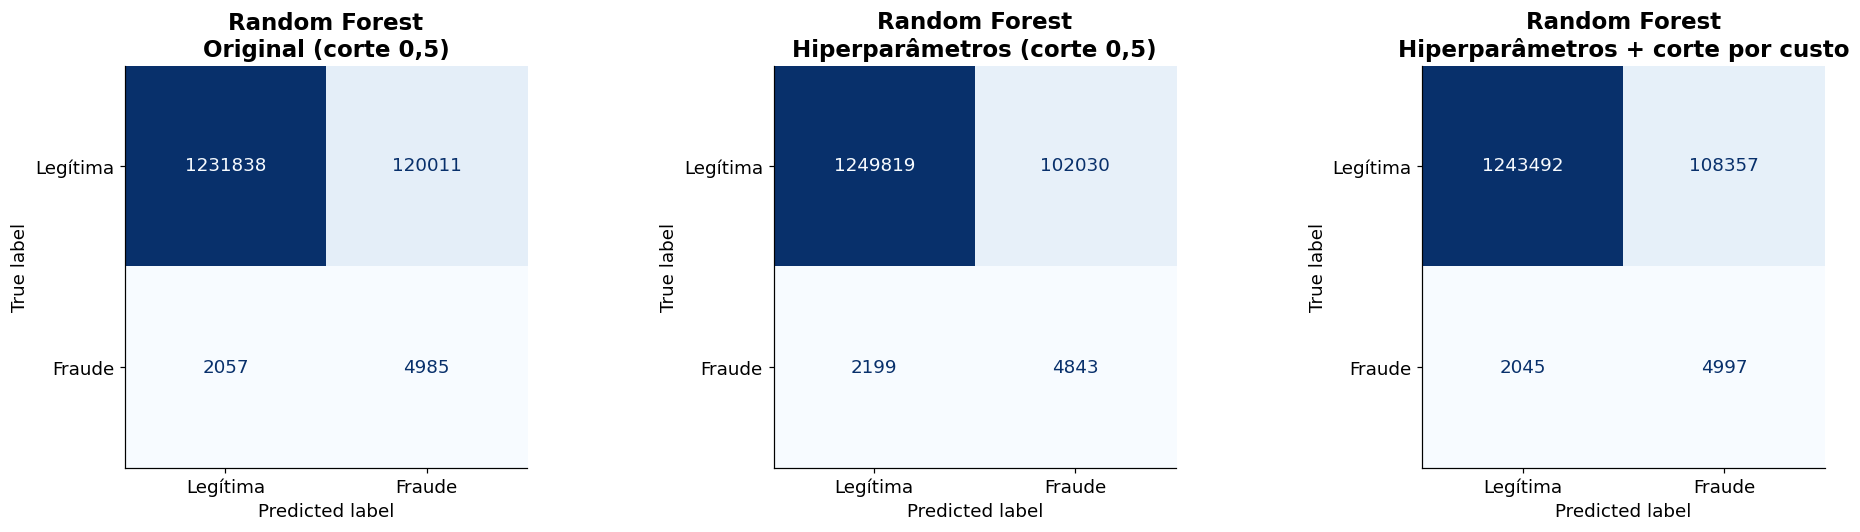

Test cost without a model / Custo no teste sem modelo (US$): 3,810,073


,versao,fraudes_detectadas,fraudes_perdidas,falsos_alarmes,precisao,recall,f2,custo_total_us
0,"Original (corte 0,5)",4985,2057,120011,0.0399,0.7079,0.1627,1446206.55
1,"Hiperparâmetros (corte 0,5)",4843,2199,102030,0.0453,0.6877,0.1793,1290983.81
2,Hiperparâmetros + corte por custo,4997,2045,108357,0.0441,0.7096,0.1765,1298802.27


In [94]:
"""Compare the original model, the tuned model and the tuned model with the cost threshold on the test set.

Compara o modelo original, o modelo ajustado e o modelo ajustado com o corte por custo no teste.
"""

amt_tst = teste_df["amt"].values
proba_tst = modelo_final.predict_proba(X_tst)[:, 1]

# original model is the one from the 10 model table, same type as the tuned one / o modelo original é o da tabela dos 10 modelos, do mesmo tipo do ajustado
comparacao = {
    "Original (corte 0,5)": np.asarray(modelos[nome_melhor][0].predict(X_te_cod)).ravel().astype(int),
    "Hiperparâmetros (corte 0,5)": np.asarray(modelo_final.predict(X_tst)).ravel().astype(int),
    "Hiperparâmetros + corte por custo": (proba_tst >= limiar_otimo).astype(int),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
linhas = []
for ax, (titulo, pred) in zip(axes, comparacao.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_tst, pred, display_labels=["Legítima", "Fraude"],
        cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.grid(False)
    ax.set_title(f"{nome_melhor}\n{titulo}", fontweight="bold")

    vn, fp, fn, vp = confusion_matrix(y_tst, pred).ravel()
    linhas.append({
        "versao": titulo,
        "fraudes_detectadas": vp,
        "fraudes_perdidas": fn,
        "falsos_alarmes": fp,
        "precisao": precision_score(y_tst, pred, zero_division=0),
        "recall": recall_score(y_tst, pred, zero_division=0),
        "f2": fbeta_score(y_tst, pred, beta=2, zero_division=0),
        "custo_total_us": amt_tst[(y_tst == 1) & (pred == 0)].sum() + FP_COST * fp,
    })

fig.tight_layout()
plt.show()

print(f"Test cost without a model / Custo no teste sem modelo (US$): {amt_tst[y_tst == 1].sum():,.0f}")
pd.DataFrame(linhas).round(4)

In [95]:
"""Compare column subsets with the tuned model on the inner validation, test set not used.

Compara subconjuntos de colunas com o modelo ajustado na validação interna, sem usar o teste.
"""

import pandas as pd
from sklearn.metrics import average_precision_score
from tqdm.auto import tqdm

# same tuned parameters, only the columns change / mesmos parâmetros ajustados, só as colunas mudam
classe, fixos, _ = candidatos[nome_melhor]
subconjuntos = {
    "todas as 9 colunas": num_cols + cat_cols,
    "sem coordenadas": ["amt", "city_pop", "category", "gender", "state"],
    "sem coordenadas e população": ["amt", "category", "gender", "state"],
    "valor e categoria": ["amt", "category"],
    "valor sozinho": ["amt"],
}

linhas = []
for nome, cols in tqdm(subconjuntos.items(), desc="Subsets / Subconjuntos"):
    modelo = classe(**fixos, **params_melhor)
    modelo.fit(X_aj[cols], y_aj_sub)
    linhas.append({
        "colunas": nome,
        "pr_auc_ajuste": average_precision_score(y_aj_sub, modelo.predict_proba(X_aj[cols])[:, 1]),
        "pr_auc_validacao": average_precision_score(y_val, modelo.predict_proba(X_val[cols])[:, 1]),
    })

print(f"Random baseline / Linha aleatória (validation): {y_val.mean():.4f}")
print(f"Amount alone as a score / Valor sozinho como nota: {average_precision_score(y_val, X_val['amt']):.4f}")
pd.DataFrame(linhas).round(4)

Subsets / Subconjuntos:   0%|          | 0/5 [00:00<?, ?it/s]

Random baseline / Linha aleatória (validation): 0.0052
Amount alone as a score / Valor sozinho como nota: 0.1536


,colunas,pr_auc_ajuste,pr_auc_validacao
0,todas as 9 colunas,0.8739,0.3625
1,sem coordenadas,0.8746,0.3131
2,sem coordenadas e população,0.8761,0.2733
3,valor e categoria,0.8740,0.2559
4,valor sozinho,0.8187,0.3366


# Part 16.1 - Fraud Identification

In [96]:
# "previsto" splits by the model decision, "real" splits by the true label / "previsto" divide pela decisão do modelo, "real" divide pelo rótulo verdadeiro
DIVISAO = "previsto"

PASTA_SAIDA = str(RESULTADOS_DIR)
os.makedirs(PASTA_SAIDA, exist_ok=True)

In [97]:
# original columns plus the model output, the score and the decision are not used as features / colunas originais mais a saída do modelo, a nota e a decisão não são usadas como variáveis
saida = teste_df[["trans_dt"] + num_cols + cat_cols + ["is_fraud"]].copy()
saida["is_fraud"] = saida["is_fraud"].astype(int)
saida["score_fraude"] = proba_tst
saida["previsto_fraude"] = (proba_tst >= limiar_otimo).astype(int)

In [98]:
# column that defines the split and the file names / coluna que define a divisão e os nomes dos arquivos
coluna = "previsto_fraude" if DIVISAO == "previsto" else "is_fraud"
sufixo = "previstas" if DIVISAO == "previsto" else "reais"
grupos = {f"fraudes_{sufixo}": 1, f"nao_fraudes_{sufixo}": 0}

resumo = []
for nome_arquivo, valor in tqdm(grupos.items(), desc="Saving / Salvando"):
    parte = saida[saida[coluna] == valor]
    caminho = os.path.join(PASTA_SAIDA, f"{nome_arquivo}.csv")
    parte.to_csv(caminho, index=False)
    resumo.append({
        "arquivo": f"{nome_arquivo}.csv",
        "linhas": len(parte),
        "fraudes_reais": int(parte["is_fraud"].sum()),
        "tamanho_mb": round(os.path.getsize(caminho) / 1e6, 1),
    })

Saving / Salvando:   0%|          | 0/2 [00:00<?, ?it/s]

In [99]:
frd = pd.DataFrame(resumo)
frd

,arquivo,linhas,fraudes_reais,tamanho_mb
0,fraudes_previstas.csv,113354,4997,12.1
1,nao_fraudes_previstas.csv,1245537,2045,138.1


In [100]:
"""Build the prediction DataFrame and show a sample of each group directly in the notebook.

Monta o DataFrame de previsões e mostra uma amostra de cada grupo direto no notebook.
"""

import pandas as pd

# original columns plus the model score and decision / colunas originais mais a nota e a decisão do modelo
saida = teste_df[["trans_dt"] + num_cols + cat_cols + ["is_fraud"]].copy()
saida["is_fraud"] = saida["is_fraud"].astype(int)
saida["score_fraude"] = proba_tst.round(4)
saida["previsto_fraude"] = (proba_tst >= limiar_otimo).astype(int)

# four groups of the confusion matrix, same counts as the chart / quatro grupos da matriz de confusão, mesmas contagens do gráfico
grupos = {
    "fraude detectada": saida[(saida["is_fraud"] == 1) & (saida["previsto_fraude"] == 1)],
    "fraude perdida": saida[(saida["is_fraud"] == 1) & (saida["previsto_fraude"] == 0)],
    "falso alarme": saida[(saida["is_fraud"] == 0) & (saida["previsto_fraude"] == 1)],
    "legitima acertada": saida[(saida["is_fraud"] == 0) & (saida["previsto_fraude"] == 0)],
}

# how many rows each group has and their typical amount and score / quantas linhas cada grupo tem e o valor e a nota típicos
pd.DataFrame({
    nome: {"linhas": len(g), "valor_mediano_us": g["amt"].median(), "score_mediano": g["score_fraude"].median()}
    for nome, g in grupos.items()
}).T.round(2)

,linhas,valor_mediano_us,score_mediano
fraude detectada,4997.0,824.68,0.94
fraude perdida,2045.0,17.81,0.21
falso alarme,108357.0,49.10,0.75
legitima acertada,1243492.0,31.89,0.12


# **Part 16.2 - Fraud prediction score**

In [101]:
"""Check how repeated the model scores are, before and after rounding.

Confere o quanto as notas do modelo se repetem, antes e depois do arredondamento.
"""

# raw scores without rounding / notas brutas sem arredondamento
notas = pd.Series(proba_tst)

print(f"Rows / Linhas: {len(notas):,}")
print(f"Unique scores raw / Notas únicas sem arredondar: {notas.nunique():,}")
print(f"Unique scores rounded to 4 decimals / Notas únicas com 4 casas: {notas.round(4).nunique():,}")

# share of rows covered by the 10 most frequent score values / parcela das linhas coberta pelos 10 valores de nota mais frequentes
freq = notas.value_counts()
print(f"Top 10 most frequent values cover / Os 10 valores mais frequentes cobrem: {freq.head(10).sum() / len(notas) * 100:.1f}% of the rows")
freq.head(10).to_frame("linhas")

Rows / Linhas: 1,358,891
Unique scores raw / Notas únicas sem arredondar: 45,705
Unique scores rounded to 4 decimals / Notas únicas com 4 casas: 8,194
Top 10 most frequent values cover / Os 10 valores mais frequentes cobrem: 17.3% of the rows


,linhas
0.217436,33062
0.217441,29189
0.008213,26696
0.095763,24506
0.217588,22244
0.008218,21980
0.195575,21081
0.217593,19415
0.195580,18939
0.008366,17956


In [102]:
"""Size of the tie blocks around the decision threshold.

Tamanho dos blocos de empate ao redor do limiar de decisão.
"""

# rows with a score within 0.001 of the threshold / linhas com nota a menos de 0,001 do limiar
perto = int((np.abs(notas - limiar_otimo) < 0.001).sum())
print(f"Rows within 0.001 of the threshold / Linhas a menos de 0,001 do limiar: {perto:,} ({perto / len(notas) * 100:.2f}% of the test)")

# unique scores among the alerts / notas únicas entre os alertas
alerta_notas = notas[notas >= limiar_otimo]
print(f"Alerts / Alertas: {len(alerta_notas):,} | unique scores among alerts / notas únicas entre os alertas: {alerta_notas.nunique():,}")

Rows within 0.001 of the threshold / Linhas a menos de 0,001 do limiar: 118 (0.01% of the test)
Alerts / Alertas: 113,354 | unique scores among alerts / notas únicas entre os alertas: 13,961


In [103]:
"""Keep the raw score and show 6 decimals in the tables.

Mantém a nota bruta e mostra 6 casas decimais nas tabelas.
"""

saida["score_fraude"] = proba_tst
fr = pd.set_option("display.float_format", "{:,.6f}".format)
fr

In [104]:
"""Keep the raw score in the output frame and show 6 decimals.

Mantém a nota bruta no DataFrame de saída e mostra 6 casas decimais.
"""

saida["score_fraude"] = proba_tst
pd.set_option("display.float_format", "{:,.6f}".format)

# top 10 predicted frauds with the full score, ties are now real differences / as 10 maiores fraudes previstas com a nota completa, os empates agora são diferenças reais
saida[saida["previsto_fraude"] == 1].sort_values("score_fraude", ascending=False).head(20)

,trans_dt,amt,city_pop,lat,long,merch_lat,merch_long,category,gender,state,is_fraud,score_fraude,previsto_fraude
5629678,2020-08-31 16:54:54,926.960000,1383,41.685600,-79.876700,41.794562,-80.238496,shopping_net,M,PA,1,0.959819,1
5444636,2020-08-14 17:52:44,968.710000,3556,41.639200,-76.015500,41.045217,-75.033838,shopping_net,M,PA,1,0.959819,1
5911744,2020-10-03 17:15:09,930.920000,2219,40.212600,-80.881500,40.476169,-80.049893,shopping_net,M,OH,1,0.959819,1
6097946,2020-10-25 12:50:32,812.390000,1523,41.833800,-74.062600,42.722637,-73.617910,shopping_net,M,NY,1,0.959819,1
5875383,2020-09-29 16:51:42,838.920000,3352,41.379700,-80.856800,41.855194,-81.262466,shopping_net,M,OH,1,0.959819,1
5567846,2020-08-26 12:00:14,837.880000,3251,40.687700,-74.468100,40.940755,-73.721489,shopping_net,M,NJ,1,0.959819,1
6101978,2020-10-25 17:00:00,853.110000,1523,41.833800,-74.062600,42.104921,-74.285748,shopping_net,M,NY,1,0.959819,1
6555454,2020-12-09 17:41:42,"1,025.050000",3738,41.126100,-76.520800,40.982630,-76.213774,shopping_net,M,PA,1,0.959819,1
5875655,2020-09-29 17:18:18,"1,104.200000",4314,44.469500,-72.692300,43.777681,-73.467243,shopping_net,M,VT,1,0.959819,1
6149534,2020-10-31 16:52:51,958.510000,1023,42.674600,-76.541800,43.347004,-76.679585,shopping_net,M,NY,1,0.959819,1


In [105]:
"""Keep the raw score in the output frame and show 6 decimals.

Mantém a nota bruta no DataFrame de saída e mostra 6 casas decimais.
"""

saida["score_fraude"] = proba_tst
pd.set_option("display.float_format", "{:,.6f}".format)

# top 10 predicted frauds with the full score, ties are now real differences / as 10 maiores fraudes previstas com a nota completa, os empates agora são diferenças reais
saida[saida["previsto_fraude"] == 0].sort_values("score_fraude", ascending=False).head(20)

,trans_dt,amt,city_pop,lat,long,merch_lat,merch_long,category,gender,state,is_fraud,score_fraude,previsto_fraude
6553083,2020-12-09 15:38:16,639.310000,1687,33.497900,-81.844500,32.921898,-81.716585,personal_care,M,SC,0,0.395220,0
5975834,2020-10-11 09:44:23,374.310000,7509,35.766500,-78.206200,35.968026,-78.905028,kids_pets,F,NC,0,0.395067,0
6322910,2020-11-21 11:41:18,370.880000,195686,25.971700,-97.469900,26.213442,-98.162569,personal_care,F,TX,0,0.395064,0
5724616,2020-09-12 09:24:03,634.310000,198659,35.027100,-85.235600,35.233140,-84.954645,kids_pets,F,TN,0,0.395039,0
6507179,2020-12-06 12:07:33,263.990000,24664,42.412800,-71.204400,42.840172,-71.320839,personal_care,M,MA,0,0.395032,0
5716249,2020-09-11 12:05:24,244.460000,190178,34.778900,-86.543800,34.087566,-87.447970,kids_pets,M,AL,0,0.395015,0
5648582,2020-09-03 13:02:40,244.520000,103980,34.026000,-84.147000,33.711992,-84.881125,kids_pets,M,GA,0,0.395015,0
5661933,2020-09-04 18:27:47,244.430000,29730,32.592700,-86.215300,33.533802,-86.155942,kids_pets,M,AL,0,0.395015,0
6118791,2020-10-28 13:00:51,244.410000,17722,34.414600,-79.377000,33.752862,-79.813132,kids_pets,M,SC,0,0.395015,0
6256751,2020-11-13 17:07:47,371.060000,20992,39.649500,-86.868600,39.101526,-86.319627,personal_care,F,IN,0,0.394999,0


In [106]:
"""Random sample of predicted frauds and of the rows closest to the threshold, to avoid reading only the extremes.

Amostra aleatória das fraudes previstas e das linhas mais perto do limiar, para não ler só os extremos.
"""

# 20 random predicted frauds / 20 fraudes previstas aleatórias
saida[saida["previsto_fraude"] == 1].sample(20, random_state=1).sort_values("score_fraude", ascending=False)

,trans_dt,amt,city_pop,lat,long,merch_lat,merch_long,category,gender,state,is_fraud,score_fraude,previsto_fraude
5943244,2020-10-07 20:18:19,307.370000,36768,39.367300,-75.029300,38.660388,-74.955172,grocery_pos,M,NJ,1,0.919101,1
5943322,2020-10-08 06:35:48,320.900000,64267,40.755800,-74.219800,39.892039,-73.333383,kids_pets,M,NJ,0,0.917613,1
6234660,2020-11-11 07:06:25,296.170000,13120,41.394600,-74.330200,40.551175,-73.434096,kids_pets,M,NY,0,0.917613,1
6756555,2020-12-20 17:52:46,8.600000,10155,43.032500,-71.191200,42.772139,-70.480214,travel,M,NH,0,0.885599,1
6753164,2020-12-20 16:03:57,9.790000,8187,28.952700,-96.648800,28.589990,-96.937435,travel,M,TX,0,0.885471,1
6677618,2020-12-17 08:12:24,12.940000,795220,39.110400,-84.575700,39.974667,-85.087522,travel,F,OH,0,0.875731,1
6791863,2020-12-23 16:11:56,3.900000,26800,42.170500,-87.859000,42.062936,-87.816413,travel,F,IL,0,0.790193,1
6675573,2020-12-16 18:25:37,5.880000,6605,39.551600,-97.656800,39.117479,-97.444959,travel,M,KS,0,0.785930,1
6792052,2020-12-23 16:21:47,2.140000,17672,34.213400,-83.448000,34.909630,-82.894778,travel,M,GA,0,0.785188,1
6736838,2020-12-20 07:33:23,47.440000,320420,39.543700,-104.969100,40.327525,-105.388579,travel,F,CO,0,0.750482,1


In [107]:
"""Check that the model inputs contain only the 9 original columns and none of the output columns.

Confere que as entradas do modelo têm só as 9 colunas originais e nenhuma das colunas de saída.
"""

colunas_originais = num_cols + cat_cols
colunas_de_saida = ["score_fraude", "previsto_fraude"]

# inputs seen by the model in fit, validation and test / entradas vistas pelo modelo no ajuste, validação e teste
for nome, X_ in [("ajuste", X_aj), ("validacao", X_val), ("teste", X_tst)]:
    print(f"{nome}: {list(X_.columns) == colunas_originais} | output columns inside / colunas de saída dentro: {[c for c in colunas_de_saida if c in X_.columns]}")

# the two columns exist only in the output DataFrame / as duas colunas existem só no DataFrame de saída
print("In the original test frame / No teste original:", [c for c in colunas_de_saida if c in teste_df.columns])
print("In the output frame / No DataFrame de saída:", [c for c in colunas_de_saida if c in saida.columns])

ajuste: True | output columns inside / colunas de saída dentro: []
validacao: True | output columns inside / colunas de saída dentro: []
teste: True | output columns inside / colunas de saída dentro: []
In the original test frame / No teste original: []
In the output frame / No DataFrame de saída: ['score_fraude', 'previsto_fraude']


# **Part 16.3 - Fraud analysis**

In [108]:
"""Diagnostic: do the test frauds come from customer locations that already had fraud in the fit period?

Diagnóstico: as fraudes do teste vêm de locais de clientes que já tinham fraude no período de ajuste?
"""

# temporary customer key from the original columns, used only here, never as a model feature / chave temporária do cliente a partir das colunas originais, usada só aqui, nunca como variável do modelo
chave_cols = ["lat", "long"]

# customer locations with at least one fraud in the fit period / locais de clientes com pelo menos uma fraude no período de ajuste
locais_fraude_ajuste = ajuste_df.loc[ajuste_df["is_fraud"].astype(bool), chave_cols].drop_duplicates()
locais_fraude_ajuste["visto_com_fraude"] = True

# mark each test row / marcar cada linha do teste
teste_marcado = teste_df[chave_cols + ["is_fraud"]].merge(locais_fraude_ajuste, on=chave_cols, how="left")
teste_marcado["visto_com_fraude"] = teste_marcado["visto_com_fraude"].fillna(False).astype(bool)
teste_marcado["is_fraud"] = teste_marcado["is_fraud"].astype(int)

# test fraud rate by whether the location had fraud before / taxa de fraude no teste conforme o local ter tido fraude antes
(
    teste_marcado.groupby("visto_com_fraude")["is_fraud"]
    .agg(linhas="size", fraudes="sum", taxa_fraude_pct=lambda s: s.mean() * 100)
    .round(3)
)

C:\Users\rafae\AppData\Local\Temp\ipykernel_39044\3817556473.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  teste_marcado["visto_com_fraude"] = teste_marcado["visto_com_fraude"].fillna(False).astype(bool)


,linhas,fraudes,taxa_fraude_pct
visto_com_fraude,,,
False,248241,2875,1.158000
True,1110650,4167,0.375000


In [109]:
teste_marcado["visto_com_fraude"] = teste_marcado["visto_com_fraude"].astype("boolean").fillna(False).astype(bool)

"""Model performance split by whether the customer location had fraud in the fit period.

Desempenho do modelo separado conforme o local do cliente ter tido fraude no período de ajuste.
"""

from sklearn.metrics import average_precision_score, confusion_matrix

visto = teste_marcado["visto_com_fraude"].values
linhas = []
for nome, mascara in [("local já visto com fraude", visto), ("local sem fraude antes", ~visto)]:
    y_g, p_g = y_tst[mascara], proba_tst[mascara]
    pred_g = (p_g >= limiar_otimo).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_g, pred_g).ravel()
    linhas.append({
        "grupo": nome,
        "linhas": len(y_g),
        "fraudes": int(y_g.sum()),
        "pr_auc": average_precision_score(y_g, p_g),
        "linha_aleatoria": y_g.mean(),
        "recall": vp / (vp + fn),
        "precisao": vp / (vp + fp),
    })
pd.DataFrame(linhas).round(4)

,grupo,linhas,fraudes,pr_auc,linha_aleatoria,recall,precisao
0,local já visto com fraude,1110650,4167,0.231400,0.003800,0.696400,0.031600
1,local sem fraude antes,248241,2875,0.410100,0.011600,0.728700,0.097900


Countplots by class / por classe:   0%|          | 0/3 [00:00<?, ?it/s]

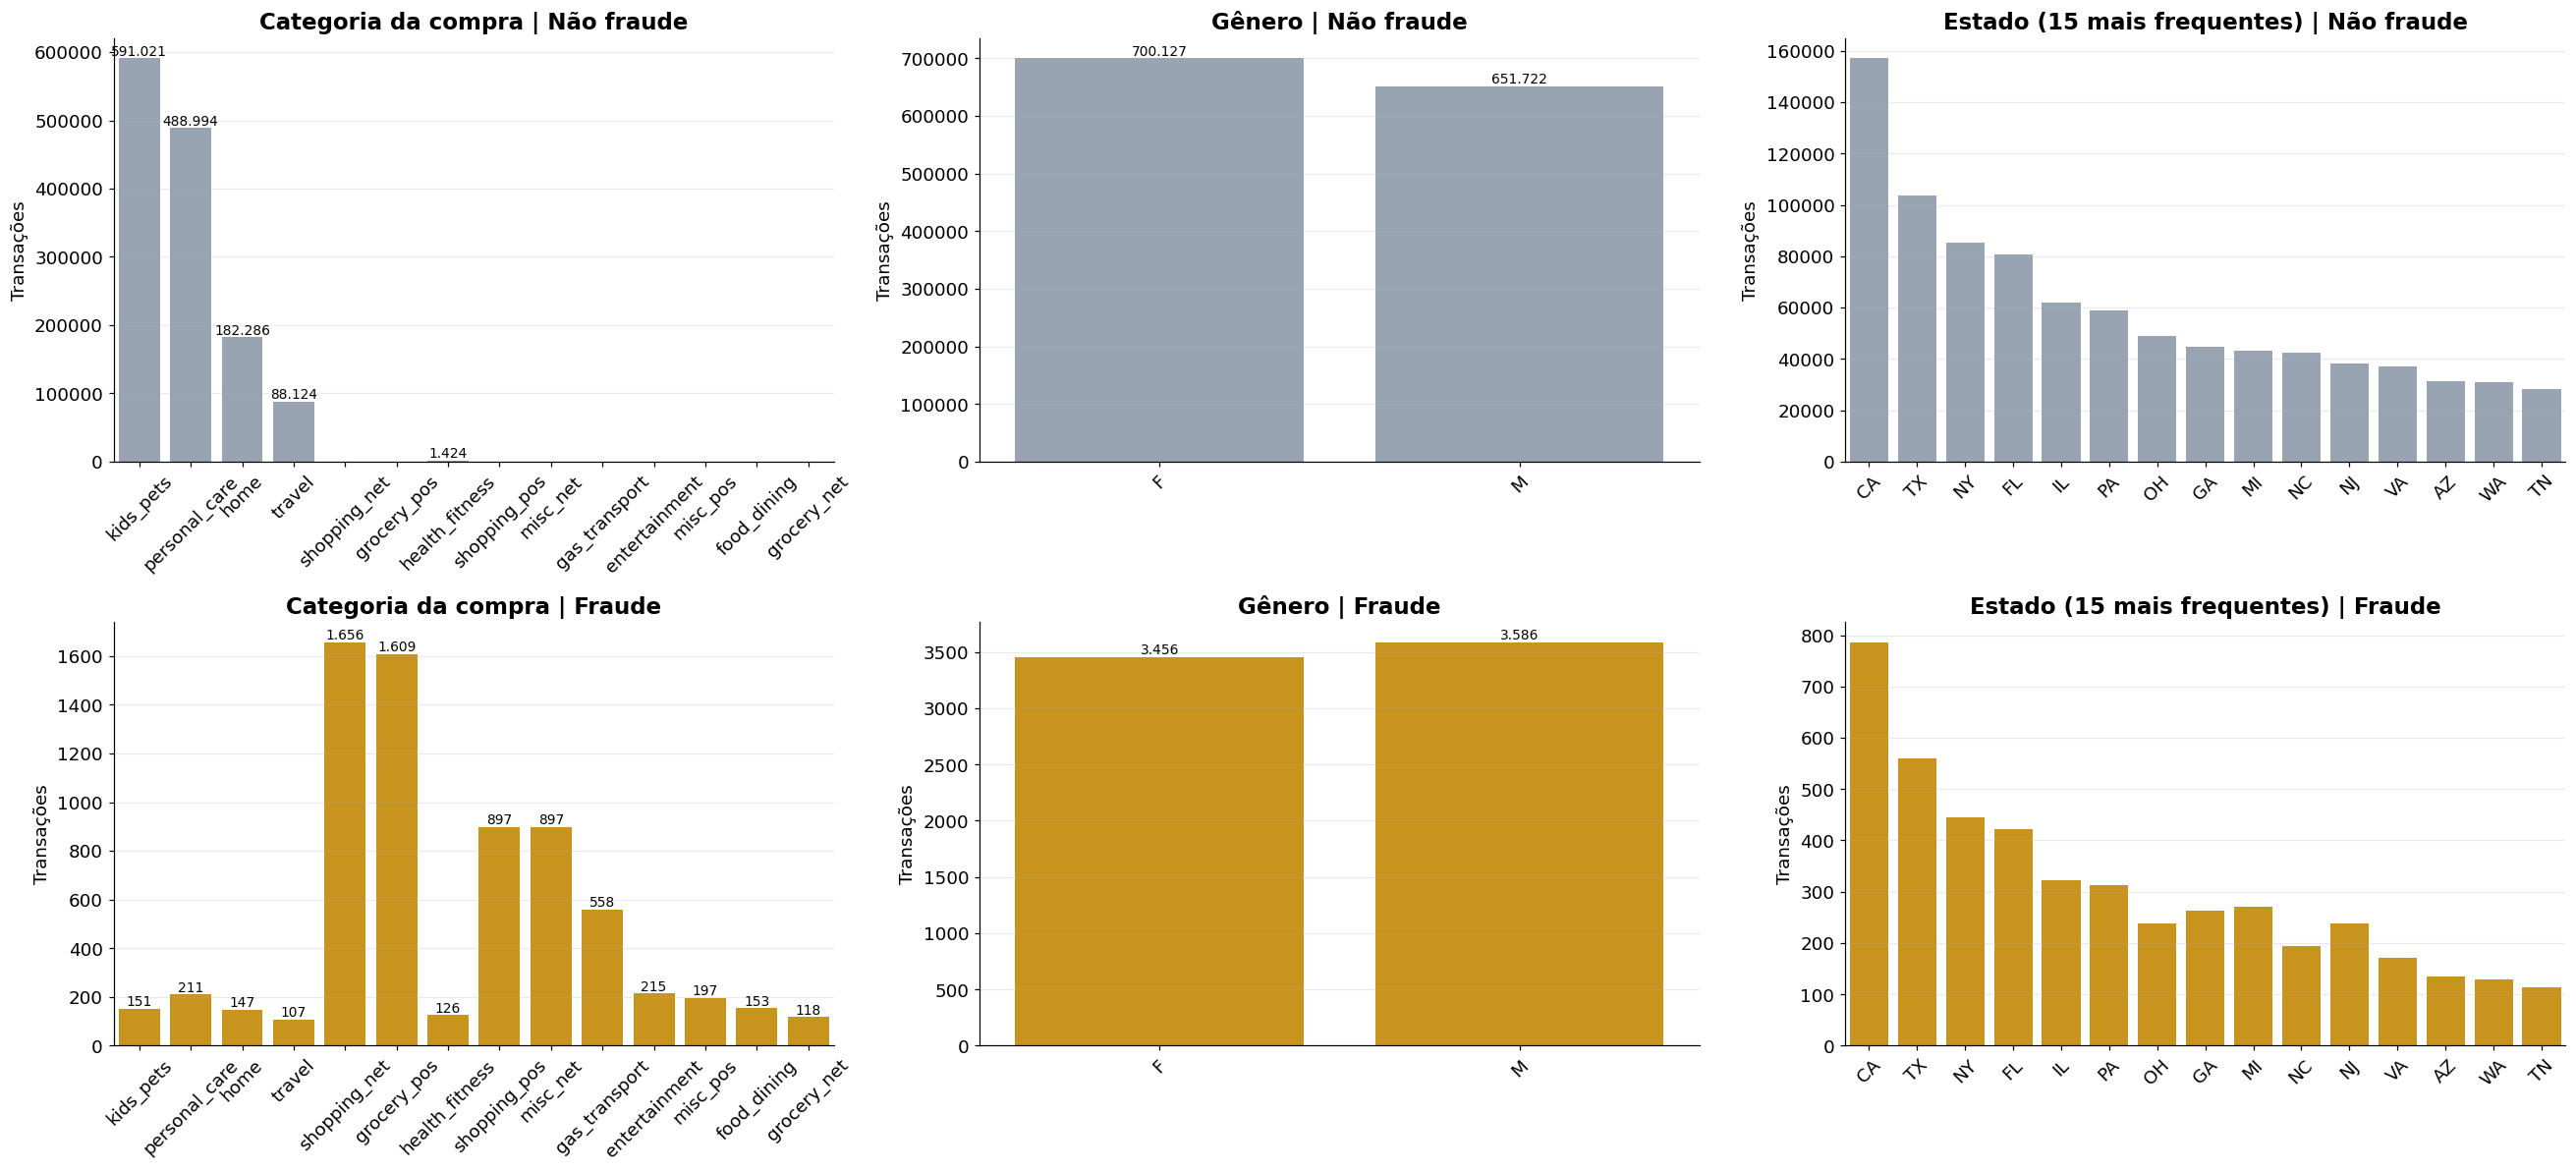

In [110]:
"""Countplots by category, gender and state in linear scale, one row per real class.

Countplots por categoria, gênero e estado em escala linear, uma linha por classe real.
"""

colunas = ["category", "gender", "state"]
titulos = {"category": "Categoria da compra", "gender": "Gênero", "state": "Estado (15 mais frequentes)"}

# one row per real class, each row with its own linear axis / uma linha por classe real, cada linha com o próprio eixo linear
classes = [(0, "Não fraude", COR_SECUNDARIA), (1, "Fraude", COR_DESTAQUE)]
fig, axes = plt.subplots(2, 3, figsize=(24, 11))

for j, coluna in enumerate(tqdm(colunas, desc="Countplots by class / por classe")):
    # same order in both rows, from the most frequent value overall / mesma ordem nas duas linhas, do valor mais frequente no total
    ordem = list(saida[coluna].value_counts().index[:15])

    for i, (classe, nome_classe, cor) in enumerate(classes):
        ax = axes[i, j]
        sns.countplot(data=saida[saida["is_fraud"] == classe], x=coluna, order=ordem, color=cor, ax=ax)

        # counts on the bars only where there are few bars / contagens nas barras só onde há poucas barras
        if coluna != "state":
            ax.bar_label(ax.containers[0], labels=[f"{int(v):,}".replace(",", ".") for v in ax.containers[0].datavalues], fontsize=9)

        ax.tick_params(axis="x", rotation=45)
        ax.set_title(f"{titulos[coluna]} | {nome_classe}")
        ax.set_xlabel("")
        ax.set_ylabel("Transações")

fig.tight_layout()
plt.show()

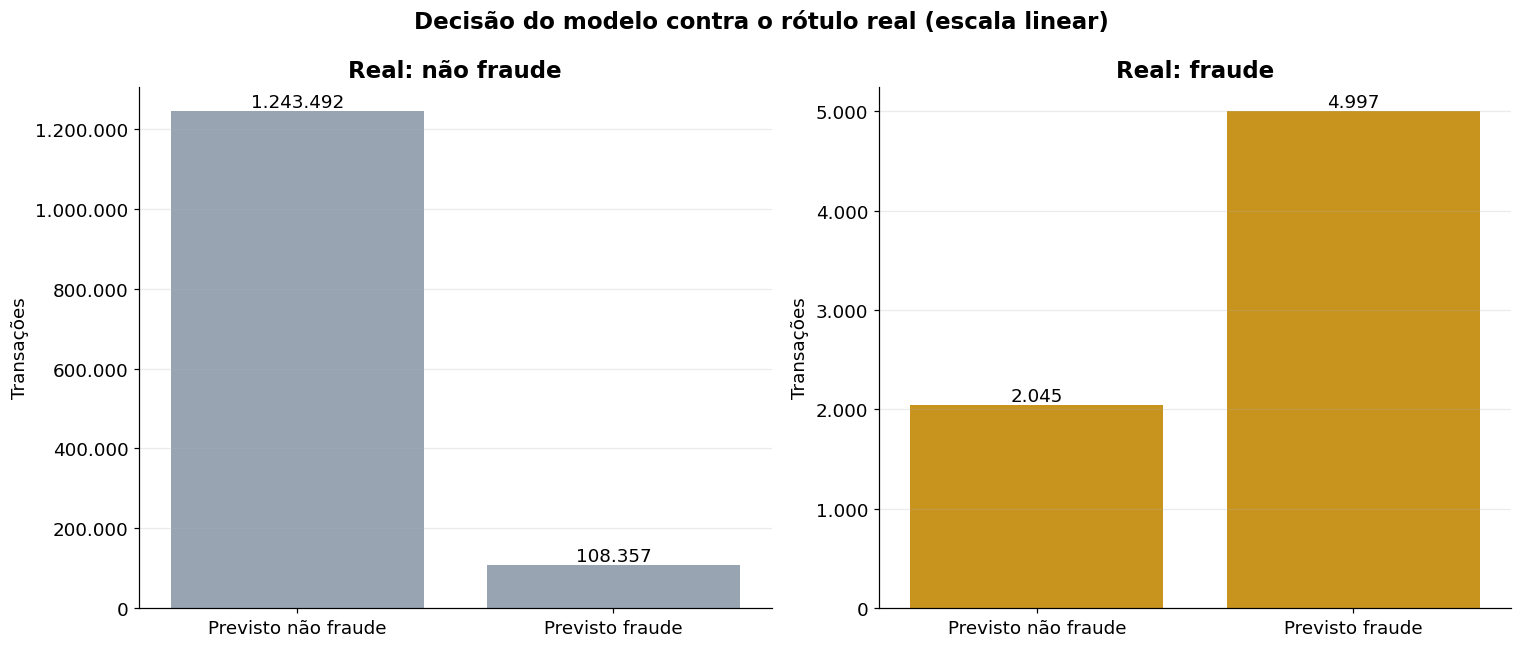

In [111]:
"""Countplot of the model decision split by the real label, linear scale, thousands separated by dots on the axis.

Countplot da decisão do modelo separado pelo rótulo real, escala linear, milhares separados por ponto no eixo.
"""

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
paineis = [(ax1, 0, "Real: não fraude", COR_SECUNDARIA), (ax2, 1, "Real: fraude", COR_DESTAQUE)]

# same readable format for both y axes / mesmo formato legível nos dois eixos y
formato = FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", "."))

for ax, classe_real, titulo, cor in paineis:
    # only the rows of one real class, so each panel has its own linear axis / só as linhas de uma classe real, então cada painel tem o próprio eixo linear
    sns.countplot(data=saida[saida["is_fraud"] == classe_real], x="previsto_fraude", order=[0, 1], color=cor, ax=ax)
    ax.bar_label(ax.containers[0], labels=[f"{int(v):,}".replace(",", ".") for v in ax.containers[0].datavalues], fontsize=12)
    ax.set_xticks([0, 1], ["Previsto não fraude", "Previsto fraude"])
    ax.yaxis.set_major_formatter(formato)
    ax.set_xlabel("")
    ax.set_ylabel("Transações")
    ax.set_title(titulo)

fig.suptitle("Decisão do modelo contra o rótulo real (escala linear)", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

In [112]:
"""Bubble map of predicted frauds by customer location, detected fraud versus false alarm.

Mapa de bolhas das fraudes previstas por local do cliente, fraude detectada versus falso alarme.
"""

# only the rows the model flagged as fraud, the label column exists only in this copy for the chart / só as linhas que o modelo marcou como fraude, a coluna de rótulo existe só nesta cópia para o gráfico
alertas = saida[saida["previsto_fraude"] == 1].copy()
alertas["resultado"] = alertas["is_fraud"].map({1: "Fraude detectada", 0: "Falso alarme"})

# one bubble per customer location and result, sized by the number of alerts / uma bolha por local de cliente e resultado, com tamanho pelo número de alertas
locais = alertas.groupby(["lat", "long", "resultado"]).size().reset_index(name="n_alertas")

# check against the confusion matrix: 5,096 detected and 31,314 false alarms / conferência com a matriz de confusão: 5.096 detectadas e 31.314 falsos alarmes
print(locais.groupby("resultado")["n_alertas"].sum())

resultado
Falso alarme        108357
Fraude detectada      4997
Name: n_alertas, dtype: int64


In [113]:
"""Map with false alarms as small gray dots behind and detected frauds as larger orange bubbles.

Mapa com falsos alarmes como pontos cinza pequenos ao fundo e fraudes detectadas como bolhas laranja maiores.
"""

alertas = saida[saida["previsto_fraude"] == 1]
detectadas = alertas[alertas["is_fraud"] == 1].groupby(["lat", "long"]).size().reset_index(name="n")
falsos = alertas[alertas["is_fraud"] == 0].groupby(["lat", "long"]).size().reset_index(name="n")

# check against the confusion matrix: 5,096 detected and 31,314 false alarms / conferência com a matriz de confusão: 5.096 detectadas e 31.314 falsos alarmes
print(f"Detected frauds / Fraudes detectadas: {detectadas['n'].sum():,} | False alarms / Falsos alarmes: {falsos['n'].sum():,}")

Detected frauds / Fraudes detectadas: 4,997 | False alarms / Falsos alarmes: 108,357


In [114]:
"""Map with false alarms as small gray dots behind and detected frauds as larger orange bubbles.

Mapa com falsos alarmes como pontos cinza pequenos ao fundo e fraudes detectadas como bolhas laranja maiores.
"""

alertas = saida[saida["previsto_fraude"] == 1]
detectadas = alertas[alertas["is_fraud"] == 1].groupby(["lat", "long"]).size().reset_index(name="n")
falsos = alertas[alertas["is_fraud"] == 0].groupby(["lat", "long"]).size().reset_index(name="n")

fig = go.Figure()

# false alarms first so they stay behind, small and light / falsos alarmes primeiro para ficarem atrás, pequenos e claros
fig.add_trace(go.Scattergeo(
    lat=falsos["lat"], lon=falsos["long"], mode="markers", name="Falso alarme",
    marker={"size": 4, "color": COR_SECUNDARIA, "opacity": 0.35},
))

# detected frauds last so they stay on top / fraudes detectadas por último para ficarem por cima
fig.add_trace(go.Scattergeo(
    lat=detectadas["lat"], lon=detectadas["long"], mode="markers", name="Fraude detectada",
    marker={"size": 4 + detectadas["n"] * 3, "color": COR_DESTAQUE, "opacity": 0.85, "line": {"width": 0.5, "color": "black"}},
    text=detectadas["n"].astype(str) + " fraudes", hoverinfo="text",
))

fig.update_geos(scope="usa", showland=True, landcolor="#F1F5F9", showsubunits=True, subunitcolor="white")
fig.update_layout(height=620, margin={"l": 0, "r": 0, "t": 50, "b": 0}, title="Fraudes detectadas (laranja) e falsos alarmes (cinza) por local do cliente")
fig.show()

# Part 17 - Model prediction

In [115]:
import os
import joblib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

In [116]:
"""Save the tuned model together with the threshold and the category encoder.

Salva o modelo ajustado junto com o limiar e o codificador das categorias.
"""

PASTA_FINAL = str(MODELOS_DIR)
os.makedirs(PASTA_FINAL, exist_ok=True)

# everything needed to predict new data the same way as in the test / tudo que é preciso para prever dados novos do mesmo jeito do teste
joblib.dump(
    {
        "modelo": modelo_final,
        "nome": nome_melhor,
        "limiar": float(limiar_otimo),
        "custo_falso_alarme": FP_COST,
        "codificador": codificador_h,
        "num_cols": num_cols,
        "cat_cols": cat_cols,
    },
    os.path.join(PASTA_FINAL, "modelo_final.joblib"),
)
print(os.listdir(PASTA_FINAL))

['catboost_gpu.cbm', 'decision_tree.joblib', 'extra_trees.joblib', 'gaussian_naive_bayes.joblib', 'histgradientboosting.joblib', 'lightgbm.joblib', 'logistic_regression.joblib', 'modelo_final.joblib', 'preprocessamento.joblib', 'random_forest.joblib', 'resultados', 'xgboost_gpu.json', 'xgboost_rf_gpu.json']


In [117]:
"""Predict new transactions with the final model, using only the 9 original columns.

Prevê transações novas com o modelo final, usando só as 9 colunas originais.
"""

# two invented example transactions, replace with real ones / duas transações de exemplo inventadas, troque por transações reais
novas = pd.DataFrame([
    {"amt": 950.0, "city_pop": 40000, "lat": 40.7, "long": -73.8, "merch_lat": 40.9, "merch_long": -73.2, "category": "shopping_net", "gender": "M", "state": "NY"},
    {"amt": 25.0, "city_pop": 250000, "lat": 34.1, "long": -117.6, "merch_lat": 34.2, "merch_long": -117.3, "category": "grocery_pos", "gender": "F", "state": "CA"},
])

# same encoding as in training, unseen categories become -1 / mesma codificação do treino, categorias não vistas viram -1
X_novas = pd.DataFrame(
    np.hstack([novas[num_cols].values, codificador_h.transform(novas[cat_cols].astype(str))]),
    columns=num_cols + cat_cols,
)

# score and decision are kept in a separate frame, never fed back to the model / nota e decisão ficam em um DataFrame separado, nunca voltam para o modelo
resultado = novas.copy()
resultado["score_fraude"] = modelo_final.predict_proba(X_novas)[:, 1].round(4)
resultado["decisao"] = np.where(resultado["score_fraude"] >= limiar_otimo, "ALERTA: fraude", "liberar")
resultado

,amt,city_pop,lat,long,merch_lat,merch_long,category,gender,state,score_fraude,decisao
0,950.000000,40000,40.700000,-73.800000,40.900000,-73.200000,shopping_net,M,NY,0.959700,ALERTA: fraude
1,25.000000,250000,34.100000,-117.600000,34.200000,-117.300000,grocery_pos,F,CA,0.013200,liberar


In [118]:
"""Create a sample CSV with the 9 original columns from the test set, to try the prediction.

Cria um CSV de exemplo com as 9 colunas originais do conjunto de teste, para testar a previsão.
"""

# folder for the output file, it also holds the prediction later / pasta do arquivo de saída, que também recebe a previsão depois
os.makedirs(str(RESULTADOS_DIR), exist_ok=True)

# 5 thousand random test rows, only the original feature columns, no label / 5 mil linhas aleatórias do teste, só as colunas originais, sem rótulo
exemplo = teste_df[num_cols + cat_cols].sample(5000, random_state=1)
exemplo.to_csv(str(OUTPUT_DIR / "transacoes_novas.csv"), index=False)

print(os.path.exists(str(OUTPUT_DIR / "transacoes_novas.csv")), "|", exemplo.shape)
exemplo.head()

True | (5000, 9)


,amt,city_pop,lat,long,merch_lat,merch_long,category,gender,state
5569788,2.240000,5309,29.939500,-82.899300,30.926606,-82.596153,home,M,FL
6410284,6.090000,61960,27.892500,-82.243000,27.984087,-82.489311,personal_care,M,FL
6563583,74.040000,59853,42.668000,-83.289300,42.117173,-82.685004,personal_care,M,MI
5437064,123.160000,206095,41.758200,-88.297100,41.536313,-87.743650,kids_pets,F,IL
6792411,104.250000,31847,42.901700,-78.663100,42.864521,-78.187109,travel,M,NY


In [119]:
"""Load the saved final model bundle from Google Drive.

Carrega o pacote do modelo final salvo no Google Drive.
"""

pacote = joblib.load(str(MODELOS_DIR / "modelo_final.joblib"))
modelo_final = pacote["modelo"]
limiar_otimo = pacote["limiar"]
codificador_h = pacote["codificador"]
num_cols, cat_cols = pacote["num_cols"], pacote["cat_cols"]
print(pacote["nome"], "| limiar / threshold:", limiar_otimo)

Random Forest | limiar / threshold: 0.3952648504987308


# Part 18 - Conclusion

# **Final Conclusion: Machine Learning Models for Fraud Detection**

Dataset analyzed: 34.6 million transactions from January 2019 to December 2020. Since fraud records are only available up to December 25, 2020, the project utilizes data through December 23, 2020 (33,974,423 transactions, with a 0.56% fraud rate). The models were trained on a 20% sample of the transactions, partitioned chronologically: the test set consists of the final 20% of this sample—covering the period from October to December 23, 2020—comprising 1,358,781 transactions, of which 6,988 (0.51%) were fraudulent.

## Problem Setup

- **Original features only:** The model uses the 9 original columns: `amt`, `city_pop`, `lat`, `long`, `merch_lat`, `merch_long`, `category`, `gender`, and `state`. No new variables were engineered, and personal identifiers were excluded.
- **Chronological split (no shuffling):** The test set follows the training set in time, ensuring that data from the same customer does not appear in both the training and testing phases.
- **Handling class imbalance (training phase only):** Legitimate transactions were undersampled at a 1:10 ratio. The validation and test sets retain the actual, original fraud rate.
- **Internal validation:** The final 20% of the training period was used for hyperparameter tuning and determining the decision threshold, ensuring that the test set remained entirely independent of these choices. ## What the results show

- **Comparison of 10 models, with fixed parameters, during testing.** Random Forest ranked first with a PR-AUC of 0.2525—approximately 50 times the random baseline (0.0051). Naive Bayes (0.1518) and Logistic Regression (0.1508) followed, while the remaining models scored between 0.006 and 0.033.
- **Transaction amount alone serves as a strong benchmark.** When used directly as a fraud score—without any model—it yields a PR-AUC of 0.1523. Naive Bayes and Logistic Regression perform on par with this, effectively just replicating the "amount" rule. Seven of the ten models performed worse than this benchmark.
- **With hyperparameter tuning, Random Forest outperformed the others during validation.** It achieved a PR-AUC of 0.3548, compared to 0.3103 for XGBoost and 0.1422 for LightGBM. The selected parameters are more conservative than the originals: a depth of 8, a minimum of 50 rows per leaf, and each tree trained on 30% of the data.
- **Transaction amount carries nearly all the signal.** During validation, a model trained using only the `amt` (amount) feature reached a PR-AUC of 0.3350, compared to 0.3548 when using all 9 columns. This difference is marginal; given a single data split and a fixed random seed, it is not possible to conclude that the other columns provide any additional value.
- **The "location shortcut" hypothesis was not confirmed.** Removing the coordinate data worsens validation performance (dropping from 0.3548 to 0.2053), which indicates that these features do, in fact, contain useful signal. Furthermore, the fraudulent transactions in the test are not concentrated in locations where fraud has occurred previously: the rate was 0.36% for such locations, compared to 1.17% for locations with no prior history of fraud.

## The decision point: the threshold, more so than the model itself

Using a standard threshold of 0.5, the adjusted model detects 91% of fraudulent transactions but generates 313,339 false alarms, resulting in only 16% in savings compared to having no model at all. A threshold was subsequently selected during the validation phase based on the lowest cost, assuming a cost of $10 for each legitimate transaction that undergoes manual review (a threshold of 0.85).

| Test Version | Frauds Detected | Frauds Missed | False Alarms | Cost (US$) |
|---|---|---|---|---|
| No model | 0 | 6,988 | 0 | 3,784,005 |
| Original Random Forest, 0.5 threshold | 4,943 | 2,045 | 118,083 | 1,427,083 |
| Adjusted, 0.5 threshold | 6,360 | 628 | 313,339 | 3,163,881 |
| **Adjusted, cost-based threshold** | **5,096** | **1,892** | **31,314** | **452,068** |

- **The final model detects 73% of fraudulent transactions,** with a precision of 14%—meaning there are approximately 6 false alarms for every detected instance of fraud.
- **False alarms are reduced by 73%** compared to the original model, and costs are reduced by 88% compared to having no model. - **The frauds that slip through are the small ones.** The 1,892 missed cases represent a total value of approximately $139,000—an average of $73 per instance, compared to an average fraud value of $541. The model blocks about 96% of the total fraudulent value, assuming that every alert successfully prevents fraud.

## Recommendations for the fraud team

1. **Use the model to prioritize the review queue,** with a cutoff threshold determined by the actual cost of conducting a review. The 0.85 threshold is only valid based on an assumed review cost of $10.
2. **Accept that low-value frauds will slip through.** Attempting to capture them would result in an excessive number of false positives; the model has been calibrated with a focus on the total value lost.
3. **Re-evaluate periodically,** as fraud patterns evolve over time.

## Limitations

- **The dataset is synthetic,** which is evident from several indicators: there are no fraudulent transactions exceeding approximately $1,250; the rate of fraud remains constant regardless of purchase volume; and there are 16- and 17-year-old customers using credit cards. These figures should not be interpreted as real-world estimates.
- **The $10 cost per false positive is an assumption.** Both the cutoff threshold and the estimated savings are dependent on this figure.
- **The analysis relies on a single data split, a fixed random seed, and a 20% holdout set,** with a limited hyperparameter search (8 combinations per model). Minor differences between similar-performing models should be considered noise.
- **The test set was accessed multiple times.** It was used to compare the 10 models, which influenced the selection of the Random Forest model for further tuning—as well as the subsequent tuning process, the determination of the cutoff threshold, and the final model selection.